In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

ball = pd.read_parquet("../data/processed/primary_ball.parquet")
matches = pd.read_csv("../data/processed/primary_matches.csv")

print("Ball-by-ball shape:", ball.shape)
print("Matches shape:", matches.shape)

display(ball.head())

Ball-by-ball shape: (194014, 42)
Matches shape: (853, 25)


,match_id,innings,overid,over_ball_num,innings_ball_num,batting_team_id,bowling_team_id,striker_id,striker_name,non_striker_id,...,delivery_ist_time,comp_id,comp_name,match_format,season,match_date,venue_country,revised_target,first_inn_revised_overs,second_inn_revised_overs
0,13511,1,1,1,1,22,28,1187,Jason Roy,6273,...,2022-01-23 00:00:00 UTC,1331,England in West Indies T20I Series 2022,T20I,2022,2022-01-22,West Indies,NaN,NaN,NaN
1,13511,1,1,2,2,22,28,1187,Jason Roy,6273,...,2022-01-23 00:00:00 UTC,1331,England in West Indies T20I Series 2022,T20I,2022,2022-01-22,West Indies,NaN,NaN,NaN
2,13511,1,1,3,3,22,28,1187,Jason Roy,6273,...,2022-01-23 00:00:00 UTC,1331,England in West Indies T20I Series 2022,T20I,2022,2022-01-22,West Indies,NaN,NaN,NaN
3,13511,1,1,4,4,22,28,1187,Jason Roy,6273,...,2022-01-23 00:00:00 UTC,1331,England in West Indies T20I Series 2022,T20I,2022,2022-01-22,West Indies,NaN,NaN,NaN
4,13511,1,1,5,5,22,28,1187,Jason Roy,6273,...,2022-01-23 00:00:00 UTC,1331,England in West Indies T20I Series 2022,T20I,2022,2022-01-22,West Indies,NaN,NaN,NaN


In [11]:
# STEP 2: Rebuild delivery-level match state

# Sort deliveries chronologically
ball = ball.sort_values(
    ["match_id", "innings", "innings_ball_num"]
).copy()

# 1. Calculate team runs
ball["team_runs"] = (
    pd.to_numeric(ball["runs"], errors="coerce").fillna(0)
    + pd.to_numeric(ball["extras1_runs"], errors="coerce").fillna(0)
    + pd.to_numeric(ball["extras_2_runs"], errors="coerce").fillna(0)
)

# 2. Identify illegal deliveries
ball["is_wide"] = ball["extras_type"].eq("wide")
ball["is_no_ball"] = ball["extras_type"].eq("Overstep")

ball["legal_ball"] = ~(
    ball["is_wide"] | ball["is_no_ball"]
)

# 3. Identify uncertain extras
ball["uncertain_extras"] = (
    ball["extras_type"].isin(["other", "Penalty"])
    | (
        ball["extras_type"].isna()
        & (
            ball["extras1_runs"].fillna(0).ne(0)
            | ball["extras_2_runs"].fillna(0).ne(0)
        )
    )
)

# 4. Calculate team wickets
ball["team_wicket"] = (
    pd.to_numeric(ball["is_wicket"], errors="coerce")
    .fillna(0).astype(int)
)

# 5. Calculate bowler-credited wickets
dismissal = (
    ball["dismissal_type"]
    .fillna("")
    .str.strip()
    .str.lower()
)

bowler_wicket_types = [
    "caught",
    "bowled",
    "lbw",
    "stump",
    "hit wicket"
]

ball["bowler_wicket"] = (
    dismissal.isin(bowler_wicket_types).astype(int)
)

# 6. Calculate match state before each delivery
group = ball.groupby(
    ["match_id", "innings"],
    sort=False
)

ball["score_before"] = (
    group["team_runs"]
    .transform(lambda x: x.cumsum().shift(1, fill_value=0))
)

ball["wickets_before"] = (
    group["team_wicket"]
    .transform(lambda x: x.cumsum().shift(1, fill_value=0))
)

ball["wickets_remaining"] = (
    10 - ball["wickets_before"]
)

ball["legal_balls_before"] = (
    group["legal_ball"]
    .transform(lambda x: x.astype(int).cumsum().shift(1, fill_value=0))
)

# 7. Determine innings ball limits
first_limit = pd.to_numeric(
    ball["first_inn_revised_overs"], errors="coerce"
)

second_limit = pd.to_numeric(
    ball["second_inn_revised_overs"], errors="coerce"
)

ball["max_legal_balls"] = np.where(
    ball["innings"] == 1,
    first_limit,
    second_limit
)

# Standard T20 fallback
ball["max_legal_balls"] = (
    pd.Series(ball["max_legal_balls"], index=ball.index)
    .fillna(120)
)

ball["balls_remaining"] = (
    ball["max_legal_balls"] - ball["legal_balls_before"]
).clip(lower=0)

# 8. Calculate first-innings total
first_totals = (
    ball[ball["innings"] == 1]
    .groupby("match_id")["team_runs"]
    .sum()
)

ball["first_innings_total"] = (
    ball["match_id"].map(first_totals)
)

# 9. Calculate chase target
ball["target"] = ball["revised_target"].where(
    ball["revised_target"].notna(),
    ball["first_innings_total"] + 1
)

# 10. Calculate runs required and required run rate
ball["runs_required"] = np.where(
    ball["innings"] == 2,
    ball["target"] - ball["score_before"],
    np.nan
)

ball["required_run_rate"] = np.where(
    (ball["innings"] == 2)
    & (ball["balls_remaining"] > 0),
    ball["runs_required"] * 6 / ball["balls_remaining"],
    np.nan
)

print("Delivery preparation completed.")
print("Dataset shape:", ball.shape)

Delivery preparation completed.
Dataset shape: (194014, 59)


In [12]:
# STEP 3: Validate reconstructed variables

required_columns = [
    "team_runs",
    "team_wicket",
    "bowler_wicket",
    "legal_ball",
    "score_before",
    "wickets_before",
    "wickets_remaining",
    "legal_balls_before",
    "balls_remaining",
    "runs_required",
    "required_run_rate"
]

print("Missing columns:")
print([c for c in required_columns if c not in ball.columns])

print("\nMissing values:")
print(ball[required_columns].isna().sum())

print("\nNegative balls remaining:")
print((ball["balls_remaining"] < 0).sum())

print("\nBowler wickets greater than team wickets:")
print((ball["bowler_wicket"] > ball["team_wicket"]).sum())

print("\nUncertain extras:")
print(ball["uncertain_extras"].sum())

print("\nMatch formats:")
print(ball["match_format"].value_counts())

Missing columns:
[]

Missing values:
team_runs                  0
team_wicket                0
bowler_wicket              0
legal_ball                 0
score_before               0
wickets_before             0
wickets_remaining          0
legal_balls_before         0
balls_remaining            0
runs_required         102080
required_run_rate     102123
dtype: int64

Negative balls remaining:
0

Bowler wickets greater than team wickets:
0

Uncertain extras:
263

Match formats:
match_format
T20I    106327
T20      87687
Name: count, dtype: int64


In [13]:
# STEP 4: Match-state summary

display(
    ball[
        [
            "innings",
            "score_before",
            "wickets_before",
            "wickets_remaining",
            "balls_remaining",
            "runs_required",
            "required_run_rate"
        ]
    ].describe().round(2)
)

,innings,score_before,wickets_before,wickets_remaining,balls_remaining,runs_required,required_run_rate
count,194014.00,194014.00,194014.00,194014.00,194014.00,91934.00,91891.00
mean,1.47,81.07,2.68,7.32,62.19,102.52,11.45
std,0.50,53.35,2.22,2.22,34.02,54.86,13.73
min,1.00,0.00,0.00,1.00,0.00,-9.00,-54.00
25%,1.00,37.00,1.00,6.00,33.00,59.00,7.69
50%,1.00,76.00,2.00,8.00,63.00,101.00,9.67
75%,2.00,120.00,4.00,9.00,92.00,143.00,12.00
max,4.00,302.00,9.00,10.00,120.00,305.00,810.00


In [14]:
# STEP 5: Inspect innings and chase-state distribution

print("INNINGS DISTRIBUTION")
print(ball["innings"].value_counts().sort_index())

print("\nMATCHES WITH MORE THAN TWO INNINGS")
print(
    ball.groupby("match_id")["innings"]
    .nunique()
    .value_counts()
    .sort_index()
)

print("\nCHASE STATE")

chase = ball[ball["innings"] == 2].copy()

print("Total second-innings deliveries:", len(chase))

print("Positive runs required:",
      (chase["runs_required"] > 0).sum())

print("Zero runs required:",
      (chase["runs_required"] == 0).sum())

print("Negative runs required:",
      (chase["runs_required"] < 0).sum())

print("Zero balls remaining:",
      (chase["balls_remaining"] == 0).sum())

print("\nREQUIRED RUN RATE PERCENTILES")

print(
    chase["required_run_rate"]
    .replace([np.inf, -np.inf], np.nan)
    .quantile([0.50, 0.75, 0.90, 0.95, 0.99])
)

INNINGS DISTRIBUTION
innings
1    102054
2     91934
3        19
4         7
Name: count, dtype: int64

MATCHES WITH MORE THAN TWO INNINGS
innings
1     22
2    811
4      4
Name: count, dtype: int64

CHASE STATE
Total second-innings deliveries: 91934
Positive runs required: 91922
Zero runs required: 2
Negative runs required: 10
Zero balls remaining: 43

REQUIRED RUN RATE PERCENTILES
0.50     9.670588
0.75    12.000000
0.90    15.906977
0.95    21.000000
0.99    50.476161
Name: required_run_rate, dtype: float64


In [15]:
# STEP 6: Investigate unusual match situations

# A. Super Overs / additional innings
print("ADDITIONAL INNINGS")

print(
    ball[ball["innings"] > 2][
        [
            "match_id",
            "innings",
            "score_before",
            "wickets_before",
            "balls_remaining"
        ]
    ].to_string(index=False)
)

# B. Negative or zero runs required
print("\nCOMPLETED OR UNUSUAL CHASE STATES")

print(
    ball[
        (ball["innings"] == 2)
        & (ball["runs_required"] <= 0)
    ][
        [
            "match_id",
            "score_before",
            "target",
            "runs_required",
            "balls_remaining"
        ]
    ].to_string(index=False)
)

# C. Extremely high required run rates
print("\nTOP 15 REQUIRED RUN RATES")

print(
    ball[
        (ball["innings"] == 2)
        & ball["required_run_rate"].notna()
    ].nlargest(15, "required_run_rate")[
        [
            "match_id",
            "score_before",
            "target",
            "runs_required",
            "balls_remaining",
            "required_run_rate"
        ]
    ].to_string(index=False)
)

# D. Deliveries with zero balls remaining
print("\nDELIVERIES WITH ZERO BALLS REMAINING")

print(
    ball[
        ball["balls_remaining"] == 0
    ][
        [
            "match_id",
            "innings",
            "innings_ball_num",
            "max_legal_balls",
            "legal_ball",
            "extras_type",
            "runs_required"
        ]
    ].head(30).to_string(index=False)
)

ADDITIONAL INNINGS
 match_id  innings  score_before  wickets_before  balls_remaining
    34429        3             0               0            120.0
    34429        3             1               0            120.0
    34429        3             2               0            119.0
    34429        3             2               1            118.0
    34429        4             0               0            120.0
    40725        3             0               0            120.0
    40725        3             0               0            119.0
    40725        3             4               0            118.0
    40725        3             5               0            117.0
    40725        3            10               0            116.0
    40725        3            10               1            115.0
    40725        4             0               0            120.0
    40725        4             2               0            119.0
    40725        4             6               0         

In [16]:
# STEP 7: Filter valid regulation-innings deliveries

# Only first and second innings
regulation = ball[
    ball["innings"].isin([1, 2])
].copy()

# Exclude deliveries after the innings limit
regulation = regulation[
    regulation["legal_balls_before"]
    < regulation["max_legal_balls"]
].copy()

# Exclude deliveries after the batting team is all out
regulation = regulation[
    regulation["wickets_before"] < 10
].copy()

# For second innings, retain only deliveries before target is reached
regulation = regulation[
    (regulation["innings"] == 1)
    | (
        (regulation["innings"] == 2)
        & (regulation["runs_required"] > 0)
    )
].copy()

print("Original deliveries:", len(ball))
print("Regulation deliveries:", len(regulation))

print("\nInnings distribution:")
print(regulation["innings"].value_counts().sort_index())

print("\nMatches:")
print(regulation["match_id"].nunique())

print("\nRemaining negative runs required:")
print(
    (regulation["runs_required"].dropna() <= 0).sum()
)

print("\nRemaining zero balls:")
print((regulation["balls_remaining"] <= 0).sum())

Original deliveries: 194014
Regulation deliveries: 193792

Innings distribution:
innings
1    101913
2     91879
Name: count, dtype: int64

Matches:
837

Remaining negative runs required:
0

Remaining zero balls:
0


In [17]:
# STEP 8: Validate regulation dataset

print("VALIDATION")

print(
    "Super Overs remaining:",
    (regulation["innings"] > 2).sum()
)

print(
    "Deliveries beyond innings limit:",
    (
        regulation["legal_balls_before"]
        >= regulation["max_legal_balls"]
    ).sum()
)

print(
    "Completed chase states:",
    (
        (regulation["innings"] == 2)
        & (regulation["runs_required"] <= 0)
    ).sum()
)

print("\nPressure variable summary:")

display(
    regulation[
        [
            "score_before",
            "wickets_remaining",
            "balls_remaining",
            "runs_required",
            "required_run_rate"
        ]
    ].describe().round(2)
)

VALIDATION
Super Overs remaining: 0
Deliveries beyond innings limit: 0
Completed chase states: 0

Pressure variable summary:


,score_before,wickets_remaining,balls_remaining,runs_required,required_run_rate
count,193792.00,193792.00,193792.00,91879.00,91879.00
mean,80.97,7.33,62.25,102.57,11.45
std,53.26,2.22,33.98,54.83,13.73
min,0.00,1.00,1.00,1.00,0.07
25%,37.00,6.00,33.00,59.00,7.69
50%,76.00,8.00,63.00,101.00,9.67
75%,120.00,9.00,92.00,143.00,12.00
max,302.00,10.00,120.00,305.00,810.00


In [18]:
# STEP 9: Match completeness audit

match_audit = (
    regulation.groupby("match_id")
    .agg(
        innings_recorded=("innings", "nunique"),
        innings_list=("innings", lambda x: tuple(sorted(x.unique()))),
        total_deliveries=("team_runs", "size")
    )
    .reset_index()
)

# Count deliveries separately by innings
innings_audit = (
    regulation.groupby(["match_id", "innings"])
    .agg(
        legal_balls=("legal_ball", "sum"),
        runs=("team_runs", "sum"),
        wickets=("team_wicket", "sum"),
        innings_limit=("max_legal_balls", "first")
    )
    .reset_index()
)

print("MATCH COMPLETENESS")
print(match_audit["innings_recorded"].value_counts().sort_index())

print("\nMatches without both regulation innings:")
print(
    match_audit[match_audit["innings_recorded"] != 2]
    .to_string(index=False)
)

print("\nSHORTENED INNINGS")
print(
    innings_audit[
        innings_audit["innings_limit"] < 120
    ].head(30).to_string(index=False)
)

print("\nInnings limit distribution:")
print(innings_audit["innings_limit"].value_counts().sort_index())

MATCH COMPLETENESS
innings_recorded
1     22
2    815
Name: count, dtype: int64

Matches without both regulation innings:
 match_id  innings_recorded innings_list  total_deliveries
    15410                 1         (1,)                22
    15546                 1         (1,)                82
    20226                 1         (1,)               118
    21406                 1         (1,)               118
    28333                 1         (1,)                66
    31707                 1         (1,)                 2
    35424                 1         (1,)               125
    37353                 1         (1,)                30
    39983                 1         (1,)                56
    39985                 1         (1,)               112
    40748                 1         (1,)               123
    40751                 1         (1,)                63
    41975                 1         (1,)                60
    41979                 1         (1,)            

In [22]:
# STEP 10 (CORRECTED): Revised target audit

revised_second = (
    regulation[
        (regulation["innings"] == 2)
        & (regulation["revised_target"].notna())
    ]
    .groupby("match_id")
    .agg(
        revised_target=("revised_target", "first"),
        first_innings_total=("first_innings_total", "first"),
        second_innings_limit=("max_legal_balls", "first"),
        second_innings_runs=("team_runs", "sum")
    )
    .reset_index()
)

print("Matches with revised targets:",
      revised_second["match_id"].nunique())

display(revised_second)

Matches with revised targets: 23


,match_id,revised_target,first_innings_total,second_innings_limit,second_innings_runs
0,13612,143.0,149,114.0,122
1,16754,56.0,95,42.0,56
2,17395,91.0,90,48.0,92
3,17765,130.0,112,72.0,30
4,21070,104.0,207,48.0,81
5,21071,203.0,202,102.0,125
6,21586,171.0,214,90.0,171
7,28046,152.0,180,90.0,154
8,29984,126.0,118,60.0,98
9,34428,78.0,161,48.0,81


In [20]:
# STEP 11: Inspect incomplete matches using match metadata

incomplete_ids = match_audit.loc[
    match_audit["innings_recorded"] == 1,
    "match_id"
]

print("Incomplete match IDs:")
print(incomplete_ids.tolist())

print("\nAvailable match metadata columns:")
print(matches.columns.tolist())

print("\nOriginal match records:")

display(
    matches[matches["match_id"].isin(incomplete_ids)]
    .sort_values("match_id")
)

Incomplete match IDs:
[15410, 15546, 20226, 21406, 28333, 31707, 35424, 37353, 39983, 39985, 40748, 40751, 41975, 41979, 45390, 45908, 46311, 46747, 46749, 47968, 50136, 50408]

Available match metadata columns:
['match_id', 'comp_id', 'match_number', 'match_date', 'stage', 'venue_id', 'venue_country', 'home_team_id', 'home_team', 'away_team_id', 'away_team', 'home_team_captain_id', 'away_team_captain_id', 'toss_win_team_id', 'toss_opted', 'man_of_the_match', 'first_inn_revised_overs', 'second_inn_revised_overs', 'revised_target', 'knock_out', 'win_team_id', 'result', 'comp_name', 'match_format', 'season']

Original match records:


,match_id,comp_id,match_number,match_date,stage,venue_id,venue_country,home_team_id,home_team,away_team_id,...,man_of_the_match,first_inn_revised_overs,second_inn_revised_overs,revised_target,knock_out,win_team_id,result,comp_name,match_format,season
391,15410,1439,5,2022-06-19,League,2,India,18,India,19,...,0,114.0,NaN,NaN,0,NaN,Match Abandoned,South Africa in India T20I Series 2022,T20I,2022
392,15546,1452,1,2022-07-02,League,84,West Indies,28,West Indies,21,...,0,84.0,NaN,NaN,0,NaN,No Result,Bangladesh in West Indies T20I Series 2022,T20I,2022
119,20226,1715,45,2023-05-03,League,3272,India,3509,Lucknow Super Giants,1,...,0,NaN,NaN,NaN,0,NaN,Match Abandoned,IPL 2023,T20,2023
504,21406,1799,4,2023-04-20,League,126,Pakistan,25,Pakistan,17,...,0,NaN,NaN,NaN,0,NaN,Match Abandoned,New Zealand in Pakistan T20I Series 2023,T20I,2023
538,28333,2058,2,2023-12-29,Others,179,New Zealand,17,New Zealand,21,...,0,NaN,NaN,NaN,0,NaN,No Result,Bangladesh in New Zealand T20I Series 2023,T20I,2023
569,31707,2350,1,2024-04-18,League,126,Pakistan,25,Pakistan,17,...,0,30.0,NaN,NaN,0,NaN,No Result,New Zealand in Pakistan T20I Series 2024,T20I,2024
637,35424,2605,2,2024-08-24,League,3404,Netherlands,89,Canada,315,...,0,NaN,NaN,NaN,0,NaN,No Result,Netherlands Tri-Nation T20I Series [Aug 2024] ...,T20I,2024
613,37353,2455,5,2024-11-18,Others,204,West Indies,28,West Indies,22,...,0,NaN,NaN,NaN,0,NaN,No Result,England in West Indies T20I Series 2024,T20I,2024
671,39983,2801,1,2025-02-22,League,59,Zimbabwe,72,Zimbabwe,23,...,0,54.0,NaN,NaN,0,NaN,No Result,Ireland in Zimbabwe T20I Series 2025,T20I,2025
673,39985,2801,3,2025-02-25,League,59,Zimbabwe,72,Zimbabwe,23,...,0,108.0,NaN,NaN,0,NaN,No Result,Ireland in Zimbabwe T20I Series 2025,T20I,2025


In [21]:
# STEP 12: Validate complete-match coverage

complete_ids = set(
    match_audit.loc[
        match_audit["innings_recorded"] == 2,
        "match_id"
    ]
)

print("Complete matches:", len(complete_ids))

print(
    "Matches with both innings:",
    (
        regulation[
            regulation["match_id"].isin(complete_ids)
        ]
        .groupby("match_id")["innings"]
        .nunique()
        .eq(2)
        .sum()
    )
)

print("\nIncomplete matches retained separately:",
      len(incomplete_ids))

Complete matches: 815
Matches with both innings: 815

Incomplete matches retained separately: 22


In [23]:
# STEP 13: Select complete regulation matches

complete_ids = set(complete_ids)

analysis = regulation[
    regulation["match_id"].isin(complete_ids)
].copy()

analysis = analysis.sort_values(
    ["match_id", "innings", "innings_ball_num"]
).reset_index(drop=True)

print("Primary analysis dataset")
print("Deliveries:", len(analysis))
print("Matches:", analysis["match_id"].nunique())

print("\nInnings distribution:")
print(analysis["innings"].value_counts().sort_index())

print("\nCompetition formats:")
print(analysis["match_format"].value_counts())

print("\nSeasons:")
print(analysis["season"].value_counts().sort_index())

Primary analysis dataset
Deliveries: 192270
Matches: 815

Innings distribution:
innings
1    100391
2     91879
Name: count, dtype: int64

Competition formats:
match_format
T20I    105012
T20      87258
Name: count, dtype: int64

Seasons:
season
2022       39490
2022/23     2835
2023       31911
2023/24      739
2024       40573
2024/25      753
2025       43137
2026       32832
Name: count, dtype: int64


In [24]:
# STEP 14: Verify competition scope

competition_audit = (
    analysis.groupby(
        ["match_format", "comp_name", "season"]
    )
    .agg(
        matches=("match_id", "nunique"),
        deliveries=("match_id", "size")
    )
    .reset_index()
    .sort_values(["match_format", "season", "comp_name"])
)

display(competition_audit)

print("\nUnique competition names:")
print(
    analysis[["match_format", "comp_name"]]
    .drop_duplicates()
    .sort_values(["match_format", "comp_name"])
    .to_string(index=False)
)

,match_format,comp_name,season,matches,deliveries
0,T20,IPL 2022,2022,74,17894
1,T20,IPL 2023,2023,73,17717
2,T20,IPL 2024,2024,71,17090
3,T20,IPL 2025,2025,72,17077
4,T20,IPL 2026,2026,73,17480
...,...,...,...,...,...
115,T20I,Sri Lanka in England T20I Series 2026,2026,3,632
119,T20I,Sri Lanka in Pakistan T20I Series 2026,2026,3,717
120,T20I,Sri Lanka in West Indies T20I Series 2026,2026,3,733
128,T20I,West Indies in India T20I Series 2026,2026,4,957



Unique competition names:
match_format                                               comp_name
         T20                                                IPL 2022
         T20                                                IPL 2023
         T20                                                IPL 2024
         T20                                                IPL 2025
         T20                                                IPL 2026
        T20I              Afghanistan in Bangladesh T20I Series 2023
        T20I                   Afghanistan in India T20I Series 2024
        T20I                 Afghanistan in Ireland T20I Series 2022
        T20I               Afghanistan in Sri Lanka T20I Series 2024
        T20I                Afghanistan in Zimbabwe T20I Series 2022
        T20I                Afghanistan in Zimbabwe T20I Series 2024
        T20I                Afghanistan in Zimbabwe T20I Series 2025
        T20I               Afghanistan v Bangladesh T20I Series 2025
       

In [25]:
# STEP 15: Finalize competition scope

# Verify only IPL appears in T20 format
t20_competitions = (
    analysis.loc[
        analysis["match_format"] == "T20",
        "comp_name"
    ].dropna().unique()
)

print("T20 competitions:")
print(t20_competitions)

assert all(
    str(name).startswith("IPL")
    for name in t20_competitions
), "Unexpected non-IPL T20 competition found!"

assert set(analysis["match_format"].unique()) == {
    "T20", "T20I"
}

# Save primary analysis dataset
analysis.to_parquet(
    "../data/processed/pressure_analysis_base.parquet",
    index=False
)

print("\nFinal dataset saved successfully.")
print("Matches:", analysis["match_id"].nunique())
print("Deliveries:", len(analysis))

T20 competitions:
<ArrowStringArray>
['IPL 2022', 'IPL 2023', 'IPL 2024', 'IPL 2025', 'IPL 2026']
Length: 5, dtype: str

Final dataset saved successfully.
Matches: 815
Deliveries: 192270


In [26]:
# STEP 16: Create innings stage variables

analysis["overs_completed"] = (
    analysis["legal_balls_before"] // 6
)

analysis["innings_progress"] = (
    analysis["legal_balls_before"]
    / analysis["max_legal_balls"]
).clip(0, 1)

# Divide innings into five phases
analysis["innings_phase"] = pd.cut(
    analysis["innings_progress"],
    bins=[-0.001, 0.20, 0.40, 0.60, 0.80, 1.001],
    labels=[
        "Powerplay",
        "Early Middle",
        "Middle",
        "Late Middle",
        "Death"
    ]
)

print("Phase distribution:")
print(analysis["innings_phase"].value_counts().sort_index())

print("\nSample:")
display(
    analysis[
        [
            "match_id",
            "innings",
            "overs_completed",
            "innings_progress",
            "innings_phase",
            "wickets_remaining",
            "balls_remaining"
        ]
    ].head(10)
)

Phase distribution:
innings_phase
Powerplay       42125
Early Middle    39885
Middle          39611
Late Middle     38609
Death           32040
Name: count, dtype: int64

Sample:


,match_id,innings,overs_completed,innings_progress,innings_phase,wickets_remaining,balls_remaining
0,13511,1,0,0.000000,Powerplay,10,120.0
1,13511,1,0,0.008333,Powerplay,10,119.0
2,13511,1,0,0.016667,Powerplay,10,118.0
3,13511,1,0,0.025000,Powerplay,10,117.0
4,13511,1,0,0.033333,Powerplay,10,116.0
5,13511,1,0,0.041667,Powerplay,10,115.0
6,13511,1,1,0.050000,Powerplay,9,114.0
7,13511,1,1,0.058333,Powerplay,9,113.0
8,13511,1,1,0.066667,Powerplay,9,112.0
9,13511,1,1,0.075000,Powerplay,9,111.0


In [27]:
# STEP 17: First innings expected scoring baseline

first = analysis[
    analysis["innings"] == 1
].copy()

# Historical context groups
baseline = (
    first.groupby(
        [
            "match_format",
            "innings_phase",
            "wickets_remaining"
        ],
        observed=True
    )
    .agg(
        expected_score=("score_before", "mean"),
        sample_size=("score_before", "size")
    )
    .reset_index()
)

print("Historical scoring baseline:")
display(baseline.head(20))

Historical scoring baseline:


,match_format,innings_phase,wickets_remaining,expected_score,sample_size
0,T20,Powerplay,4,8.500000,2
1,T20,Powerplay,5,7.750000,8
2,T20,Powerplay,6,14.428571,7
3,T20,Powerplay,7,21.779310,145
4,T20,Powerplay,8,21.680395,607
5,T20,Powerplay,9,20.078497,2395
6,T20,Powerplay,10,14.210626,6305
7,T20,Early Middle,4,24.066667,30
8,T20,Early Middle,5,46.956522,69
9,T20,Early Middle,6,45.004963,403


In [28]:
# STEP 18: Baseline coverage

display(
    baseline.groupby("match_format")
    .agg(
        context_groups=("sample_size", "count"),
        minimum_sample=("sample_size", "min"),
        median_sample=("sample_size", "median"),
        maximum_sample=("sample_size", "max")
    )
)

,context_groups,minimum_sample,median_sample,maximum_sample
match_format,,,,
T20,43,2,607.0,6305
T20I,44,1,963.5,7156


In [29]:
# STEP 19: Historical baseline coverage by match

first = analysis[
    analysis["innings"] == 1
].copy()

# Divide the innings into 10 progress intervals
first["progress_bin"] = (
    np.floor(first["innings_progress"] * 10)
    .clip(0, 9)
    .astype(int)
)

# Count distinct matches for each context
baseline_coverage = (
    first.groupby(
        [
            "match_format",
            "progress_bin",
            "wickets_remaining"
        ],
        observed=True
    )
    .agg(
        distinct_matches=("match_id", "nunique"),
        deliveries=("match_id", "size")
    )
    .reset_index()
)

print("BASELINE COVERAGE")

display(
    baseline_coverage.sort_values(
        ["match_format", "progress_bin", "wickets_remaining"]
    )
)

print("\nSUMMARY")

display(
    baseline_coverage.groupby("match_format")
    .agg(
        context_groups=("distinct_matches", "count"),
        minimum_matches=("distinct_matches", "min"),
        median_matches=("distinct_matches", "median"),
        maximum_matches=("distinct_matches", "max")
    )
)

BASELINE COVERAGE


,match_format,progress_bin,wickets_remaining,distinct_matches,deliveries
0,T20,0,7,2,6
1,T20,0,8,16,72
2,T20,0,9,107,597
3,T20,0,10,363,3908
4,T20,1,4,1,1
...,...,...,...,...,...
158,T20I,9,5,177,1162
159,T20I,9,6,118,742
160,T20I,9,7,54,411
161,T20I,9,8,20,167



SUMMARY


,context_groups,minimum_matches,median_matches,maximum_matches
match_format,,,,
T20,82,1,51.0,363
T20I,81,1,75.0,452


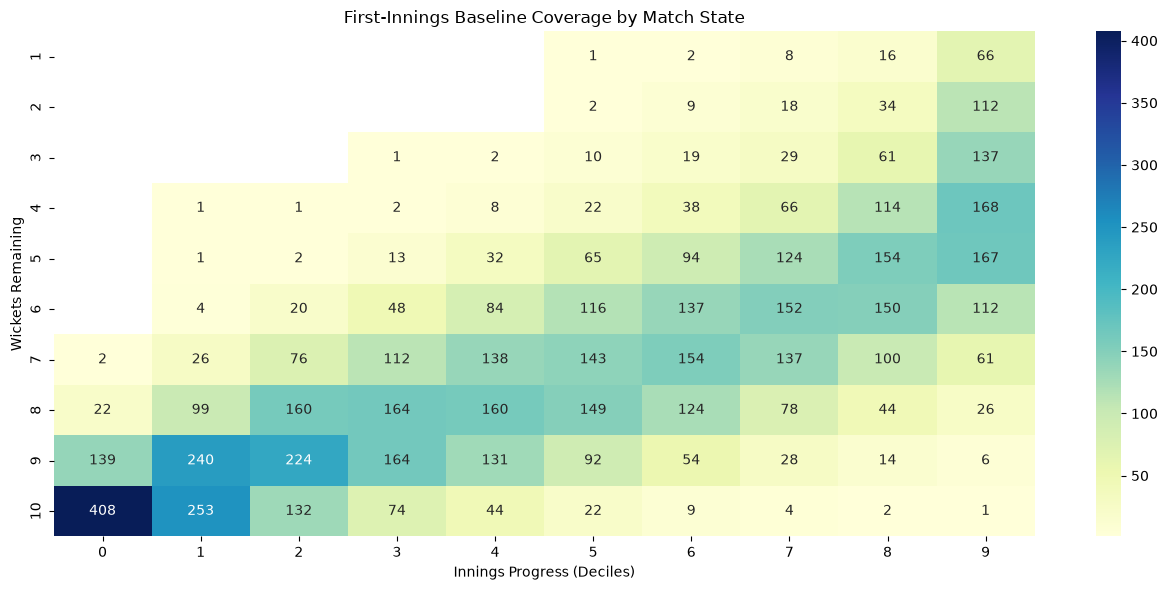

In [30]:
# STEP 20: Visualize baseline coverage

plt.figure(figsize=(13, 6))

sns.heatmap(
    baseline_coverage.pivot_table(
        index="wickets_remaining",
        columns="progress_bin",
        values="distinct_matches",
        aggfunc="mean"
    ),
    annot=True,
    fmt=".0f",
    cmap="YlGnBu"
)

plt.title("First-Innings Baseline Coverage by Match State")
plt.xlabel("Innings Progress (Deciles)")
plt.ylabel("Wickets Remaining")
plt.tight_layout()
plt.show()

In [31]:
# STEP 21: Cross-validated first-innings expected score model

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# First innings only
first = analysis[
    analysis["innings"] == 1
].copy()

# Features available before the delivery
features = [
    "innings_progress",
    "wickets_remaining",
    "balls_remaining",
    "max_legal_balls",
    "match_format"
]

# Encode competition format
X = pd.get_dummies(
    first[features],
    columns=["match_format"],
    dtype=int
)

y = first["score_before"]

# Each match receives equal total weight
match_counts = first.groupby("match_id")["match_id"].transform("size")
sample_weights = 1 / match_counts

# Five-fold validation grouped by match
gkf = GroupKFold(n_splits=5)

first["expected_score"] = np.nan

for fold, (train_idx, test_idx) in enumerate(
    gkf.split(X, y, groups=first["match_id"]), start=1
):

    model = RandomForestRegressor(
        n_estimators=250,
        min_samples_leaf=20,
        max_features=0.9,
        random_state=42,
        n_jobs=-1
    )

    model.fit(
        X.iloc[train_idx],
        y.iloc[train_idx],
        sample_weight=sample_weights.iloc[train_idx]
    )

    first.loc[
        first.index[test_idx],
        "expected_score"
    ] = model.predict(X.iloc[test_idx])

    print(f"Fold {fold} completed")

# Evaluate out-of-fold predictions
mae = mean_absolute_error(y, first["expected_score"])

rmse = np.sqrt(
    mean_squared_error(y, first["expected_score"])
)

r2 = r2_score(y, first["expected_score"])

print("\nMODEL PERFORMANCE")
print("MAE:", round(mae, 3))
print("RMSE:", round(rmse, 3))
print("R2 Score:", round(r2, 3))

display(
    first[
        [
            "match_id",
            "innings_progress",
            "wickets_remaining",
            "score_before",
            "expected_score"
        ]
    ].head(15)
)

Fold 1 completed
Fold 2 completed
Fold 3 completed
Fold 4 completed
Fold 5 completed

MODEL PERFORMANCE
MAE: 12.923
RMSE: 18.093
R2 Score: 0.893


,match_id,innings_progress,wickets_remaining,score_before,expected_score
0,13511,0.000000,10,0,0.076997
1,13511,0.008333,10,0,0.962574
2,13511,0.016667,10,0,2.106807
3,13511,0.025000,10,0,3.312106
4,13511,0.033333,10,0,4.655285
5,13511,0.041667,10,6,5.843028
6,13511,0.050000,9,6,5.165981
7,13511,0.058333,9,6,6.300176
8,13511,0.066667,9,6,7.685918
9,13511,0.075000,9,6,8.569930


In [32]:
# STEP 22: Performance by competition format

first["prediction_error"] = (
    first["score_before"] - first["expected_score"]
)

format_performance = (
    first.groupby("match_format")
    .agg(
        deliveries=("match_id", "size"),
        actual_average=("score_before", "mean"),
        predicted_average=("expected_score", "mean"),
        average_error=("prediction_error", "mean"),
        error_std=("prediction_error", "std")
    )
)

display(format_performance.round(3))

,deliveries,actual_average,predicted_average,average_error,error_std
match_format,,,,,
T20,45199,88.470,88.309,0.161,18.304
T20I,55192,80.523,80.393,0.130,17.918


In [33]:
# STEP 23: Calculate first-innings scoring deficit

# Positive value means team is behind expected score
first["scoring_deficit"] = (
    first["expected_score"] - first["score_before"]
)

# Create innings progress deciles
first["progress_bin"] = (
    np.floor(first["innings_progress"] * 10)
    .clip(0, 9)
    .astype(int)
)

print("SCORING DEFICIT SUMMARY")

display(
    first.groupby("match_format")["scoring_deficit"]
    .describe()
    .round(3)
)

print("\nSample scoring deficits:")

display(
    first[
        [
            "match_id",
            "innings_progress",
            "wickets_remaining",
            "score_before",
            "expected_score",
            "scoring_deficit"
        ]
    ].head(20)
)

SCORING DEFICIT SUMMARY


,count,mean,std,min,25%,50%,75%,max
match_format,,,,,,,,
T20,45199.0,-0.161,18.304,-96.655,-8.759,1.080,10.058,77.212
T20I,55192.0,-0.130,17.918,-114.218,-7.581,1.149,9.993,99.565



Sample scoring deficits:


,match_id,innings_progress,wickets_remaining,score_before,expected_score,scoring_deficit
0,13511,0.000000,10,0,0.076997,0.076997
1,13511,0.008333,10,0,0.962574,0.962574
2,13511,0.016667,10,0,2.106807,2.106807
3,13511,0.025000,10,0,3.312106,3.312106
4,13511,0.033333,10,0,4.655285,4.655285
5,13511,0.041667,10,6,5.843028,-0.156972
6,13511,0.050000,9,6,5.165981,-0.834019
7,13511,0.058333,9,6,6.300176,0.300176
8,13511,0.066667,9,6,7.685918,1.685918
9,13511,0.075000,9,6,8.569930,2.569930


In [34]:
# STEP 24: Analyze residual variation by progress

residual_analysis = (
    first.groupby(
        ["match_format", "progress_bin"]
    )
    .agg(
        deliveries=("match_id", "size"),
        matches=("match_id", "nunique"),
        mean_deficit=("scoring_deficit", "mean"),
        std_deficit=("scoring_deficit", "std"),
        median_deficit=("scoring_deficit", "median")
    )
    .reset_index()
)

display(residual_analysis.round(3))

,match_format,progress_bin,deliveries,matches,mean_deficit,std_deficit,median_deficit
0,T20,0,4583,363,-0.032,3.973,0.173
1,T20,1,4505,363,-0.074,8.069,0.742
2,T20,2,4498,363,-0.126,11.537,1.258
3,T20,3,4472,363,-0.157,14.376,1.591
4,T20,4,4492,363,-0.117,16.655,1.786
5,T20,5,4505,363,-0.088,18.436,1.745
6,T20,6,4547,363,-0.164,20.772,0.978
7,T20,7,4550,363,-0.188,22.919,2.051
8,T20,8,4535,359,-0.360,24.912,2.571
9,T20,9,4512,354,-0.304,27.097,2.424


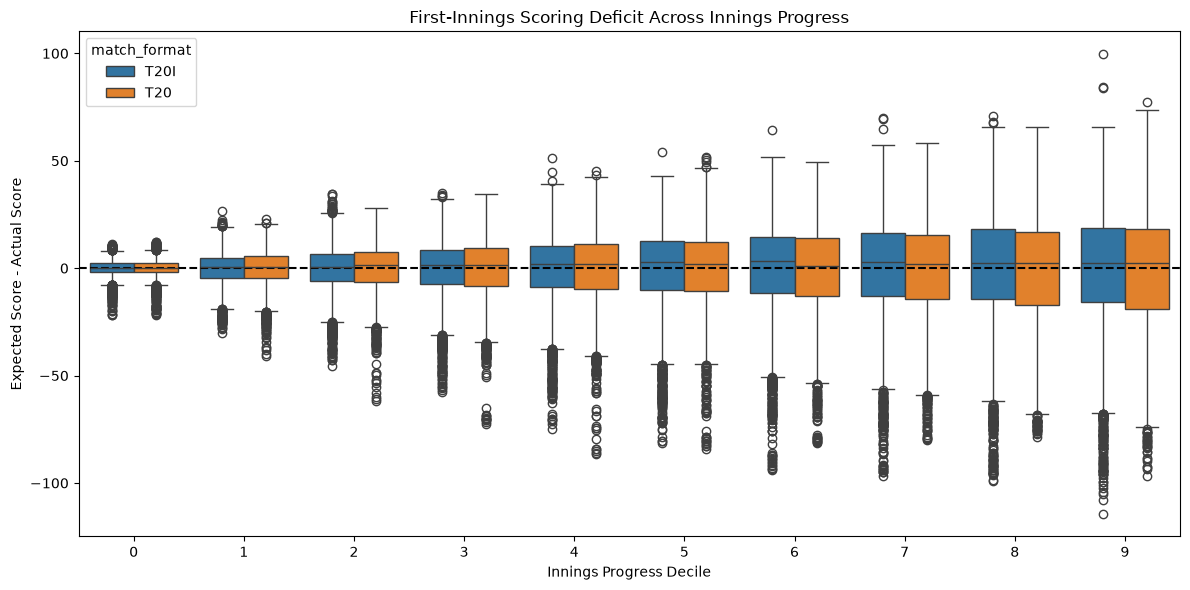

In [35]:
# STEP 25: Scoring deficit visualization

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=first,
    x="progress_bin",
    y="scoring_deficit",
    hue="match_format"
)

plt.axhline(0, linestyle="--", color="black")

plt.title("First-Innings Scoring Deficit Across Innings Progress")
plt.xlabel("Innings Progress Decile")
plt.ylabel("Expected Score - Actual Score")
plt.tight_layout()
plt.show()

In [39]:
# STEP 26: Calculate correctly standardized scoring pressure

# Calculate mean and standard deviation for each format and progress decile
pressure_scale = (
    first.groupby(["match_format", "progress_bin"])
    ["scoring_deficit"]
    .agg(["mean", "std"])
    .reset_index()
    .rename(columns={
        "mean": "deficit_mean",
        "std": "deficit_std"
    })
)

# Remove old columns if this cell is being rerun
first = first.drop(
    columns=["deficit_mean", "deficit_std", "pressure_z"],
    errors="ignore"
)

# Merge the pressure statistics
first = first.merge(
    pressure_scale,
    on=["match_format", "progress_bin"],
    how="left"
)

# Calculate standardized pressure
first["pressure_z"] = (
    (first["scoring_deficit"] - first["deficit_mean"])
    / first["deficit_std"]
)

print("CORRECTED STANDARDIZED PRESSURE SUMMARY")

display(
    first.groupby("match_format")["pressure_z"]
    .describe()
    .round(3)
)

CORRECTED STANDARDIZED PRESSURE SUMMARY


,count,mean,std,min,25%,50%,75%,max
match_format,,,,,,,,
T20,45199.0,0.0,1.0,-5.476,-0.598,0.097,0.667,3.094
T20I,55192.0,-0.0,1.0,-5.818,-0.557,0.111,0.687,3.669


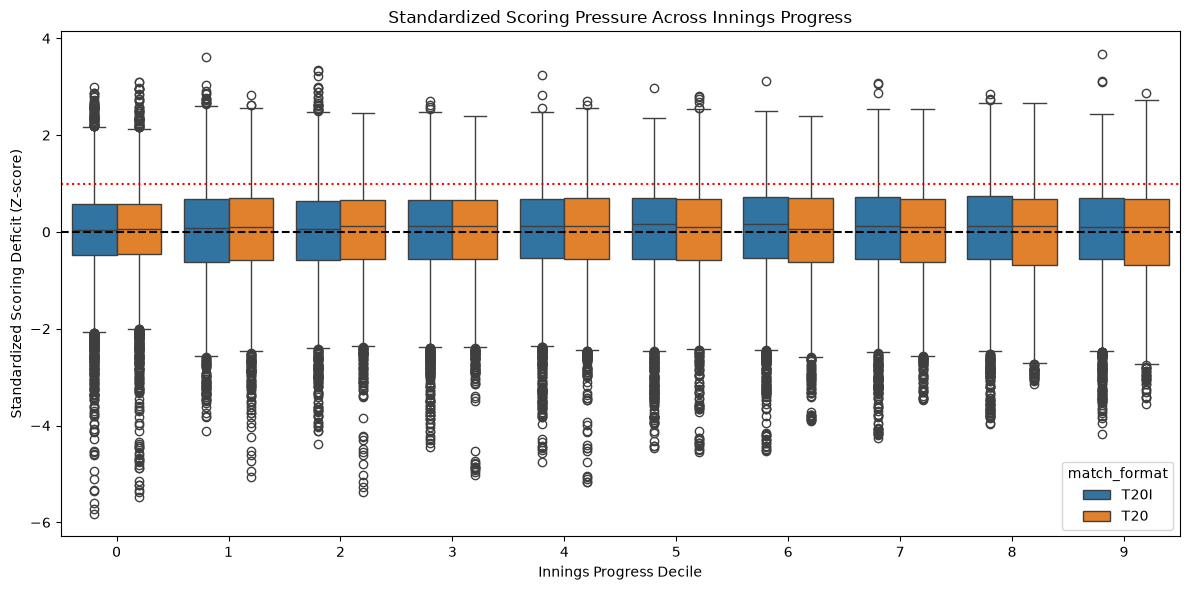

In [40]:
# STEP 27: Visualize standardized pressure

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=first,
    x="progress_bin",
    y="pressure_z",
    hue="match_format"
)

plt.axhline(0, linestyle="--", color="black")
plt.axhline(1, linestyle=":", color="red")

plt.title("Standardized Scoring Pressure Across Innings Progress")
plt.xlabel("Innings Progress Decile")
plt.ylabel("Standardized Scoring Deficit (Z-score)")

plt.tight_layout()
plt.show()

In [41]:
# STEP 28: Identify high-pressure first-innings states

high_pressure = first[
    first["pressure_z"] >= 1
].copy()

print("High-pressure deliveries:", len(high_pressure))

print("\nHigh-pressure deliveries by format:")

display(
    high_pressure.groupby("match_format")
    .agg(
        deliveries=("match_id", "size"),
        matches=("match_id", "nunique"),
        average_deficit=("scoring_deficit", "mean"),
        average_pressure=("pressure_z", "mean")
    )
    .round(3)
)

High-pressure deliveries: 14232

High-pressure deliveries by format:


,deliveries,matches,average_deficit,average_pressure
match_format,,,,
T20,6510,220,24.170,1.416
T20I,7722,288,21.952,1.371


In [42]:
# STEP 29: Audit second-innings match outcomes

# Get match outcome information
match_results = matches[
    ["match_id", "win_team_id", "result"]
].drop_duplicates("match_id")

# Select second-innings deliveries
chase = analysis[
    analysis["innings"] == 2
].copy()

# Attach match outcomes
chase = chase.merge(
    match_results,
    on="match_id",
    how="left",
    validate="many_to_one"
)

print("SECOND-INNINGS OUTCOME AUDIT")

print("\nTotal chase deliveries:", len(chase))

print("\nMissing winner IDs:")
print(chase["win_team_id"].isna().sum())

print("\nMatch result distribution:")
display(
    match_results["result"]
    .value_counts(dropna=False)
    .to_frame("matches")
)

print("\nUnique match outcomes:")
display(
    match_results[
        ["win_team_id", "result"]
    ].drop_duplicates()["result"]
    .value_counts(dropna=False)
)

SECOND-INNINGS OUTCOME AUDIT

Total chase deliveries: 91879

Missing winner IDs:
88

Match result distribution:


,matches
result,
No Result,21
Match Abandoned,19
India Won by 7 wickets,8
Delhi Capitals Won by 6 wickets,7
Kolkata Knight Riders Won by 8 wickets,6
...,...
India Won by 127 runs,1
India Won by 2 runs,1
Pakistan Won by 82 runs,1



Unique match outcomes:


result
Kolkata Knight Riders Won by 6 Wkts    1
Delhi Capitals Won by 4 Wickets        1
Punjab Kings Won by 5 Wkts             1
Gujarat Titans Won by 5 Wickets        1
Rajasthan Royals Won by 61 Runs        1
                                      ..
India Won by 127 runs                  1
India Won by 2 runs                    1
Pakistan Won by 82 runs                1
Afghanistan Won by 37 runs             1
Afghanistan Won by 19 runs             1
Name: count, Length: 643, dtype: int64

In [43]:
# STEP 30: Create chase outcome variable

# Exclude matches without a recorded winner
chase = chase[
    chase["win_team_id"].notna()
].copy()

# 1 = chasing team won, 0 = chasing team lost
chase["chase_won"] = (
    chase["batting_team_id"] == chase["win_team_id"]
).astype(int)

print("CHASE SUCCESS DATASET")

print("Deliveries:", len(chase))
print("Matches:", chase["match_id"].nunique())

print("\nChase outcome distribution:")

display(
    chase.groupby("chase_won")
    .agg(
        deliveries=("match_id", "size"),
        matches=("match_id", "nunique")
    )
)

CHASE SUCCESS DATASET
Deliveries: 91791
Matches: 812

Chase outcome distribution:


,deliveries,matches
chase_won,,
0,48002,406
1,43789,406


In [44]:
# STEP 31: Validate chase model features

print("CHASE MODEL FEATURE VALIDATION")

print("\nMissing values:")
display(
    chase[
        [
            "required_run_rate",
            "balls_remaining",
            "wickets_remaining",
            "match_format",
            "chase_won"
        ]
    ].isna().sum()
)

print("\nInfinite required run rates:")
print(
    np.isinf(chase["required_run_rate"]).sum()
)

print("\nInvalid chase states:")
print(
    "Runs required <= 0:",
    (chase["runs_required"] <= 0).sum()
)

print(
    "Balls remaining <= 0:",
    (chase["balls_remaining"] <= 0).sum()
)

print(
    "Wickets remaining <= 0:",
    (chase["wickets_remaining"] <= 0).sum()
)

print("\nOutcome distribution by format:")

display(
    chase.groupby(["match_format", "chase_won"])
    .agg(
        deliveries=("match_id", "size"),
        matches=("match_id", "nunique")
    )
)

CHASE MODEL FEATURE VALIDATION

Missing values:


required_run_rate    0
balls_remaining      0
wickets_remaining    0
match_format         0
chase_won            0
dtype: int64


Infinite required run rates:
0

Invalid chase states:
Runs required <= 0: 0
Balls remaining <= 0: 0
Wickets remaining <= 0: 0

Outcome distribution by format:


deliveries  matches
match_format chase_won                     
T20          0               21102      174
             1               20950      188
T20I         0               26900      232
             1               22839      218

In [45]:
# STEP 32: Chase-win probability model

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    brier_score_loss,
    log_loss
)

# Keep valid pre-delivery chase states
chase_model_data = chase[
    np.isfinite(chase["required_run_rate"])
    & (chase["balls_remaining"] > 0)
    & (chase["wickets_remaining"] > 0)
    & (chase["runs_required"] > 0)
].copy()

# Select pre-delivery features
features = [
    "required_run_rate",
    "balls_remaining",
    "wickets_remaining",
    "match_format"
]

X = chase_model_data[features]
y = chase_model_data["chase_won"]

# Numeric and categorical features
numeric_features = [
    "required_run_rate",
    "balls_remaining",
    "wickets_remaining"
]

categorical_features = ["match_format"]

preprocessor = ColumnTransformer([
    (
        "numeric",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]),
        numeric_features
    ),
    (
        "categorical",
        OneHotEncoder(handle_unknown="ignore"),
        categorical_features
    )
])

# Logistic Regression pipeline
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000))
])

# Equal total sample weight per match
match_counts = (
    chase_model_data.groupby("match_id")["match_id"]
    .transform("size")
)

sample_weights = 1 / match_counts

# Grouped cross-validation
gkf = GroupKFold(n_splits=5)

chase_model_data["chase_win_probability"] = np.nan

for fold, (train_idx, test_idx) in enumerate(
    gkf.split(
        X,
        y,
        groups=chase_model_data["match_id"]
    ),
    start=1
):
    model.fit(
        X.iloc[train_idx],
        y.iloc[train_idx],
        classifier__sample_weight=sample_weights.iloc[train_idx]
    )

    chase_model_data.iloc[
        test_idx,
        chase_model_data.columns.get_loc("chase_win_probability")
    ] = model.predict_proba(X.iloc[test_idx])[:, 1]

    print(f"Fold {fold} completed")

# Evaluate out-of-fold probabilities
actual = y
predicted = chase_model_data["chase_win_probability"]

print("\nCHASE MODEL PERFORMANCE")

print(
    "ROC-AUC:",
    round(roc_auc_score(actual, predicted), 3)
)

print(
    "Accuracy:",
    round(accuracy_score(actual, predicted >= 0.5), 3)
)

print(
    "Brier Score:",
    round(brier_score_loss(actual, predicted), 3)
)

print(
    "Log Loss:",
    round(log_loss(actual, predicted), 3)
)

Fold 1 completed
Fold 2 completed
Fold 3 completed
Fold 4 completed
Fold 5 completed

CHASE MODEL PERFORMANCE
ROC-AUC: 0.893
Accuracy: 0.809
Brier Score: 0.135
Log Loss: 0.418


In [46]:
# STEP 33: Calculate chase pressure

chase_model_data["chase_pressure"] = (
    1 - chase_model_data["chase_win_probability"]
) * 100

print("CHASE PRESSURE SUMMARY")

display(
    chase_model_data["chase_pressure"]
    .describe()
    .round(2)
)

print("\nSample chase pressure states:")

display(
    chase_model_data[
        [
            "match_id",
            "match_format",
            "runs_required",
            "balls_remaining",
            "wickets_remaining",
            "required_run_rate",
            "chase_win_probability",
            "chase_pressure",
            "chase_won"
        ]
    ].head(15).round(3)
)

CHASE PRESSURE SUMMARY


count    91791.00
mean        51.68
std         30.79
min          0.07
25%         25.09
50%         51.01
75%         78.46
max        100.00
Name: chase_pressure, dtype: float64


Sample chase pressure states:


,match_id,match_format,runs_required,balls_remaining,wickets_remaining,required_run_rate,chase_win_probability,chase_pressure,chase_won
0,13511,T20I,104.0,120.0,10,5.200,0.786,21.383,1
1,13511,T20I,104.0,119.0,10,5.244,0.789,21.136,1
2,13511,T20I,100.0,118.0,10,5.085,0.805,19.510,1
3,13511,T20I,100.0,117.0,10,5.128,0.807,19.277,1
4,13511,T20I,100.0,116.0,10,5.172,0.809,19.051,1
5,13511,T20I,99.0,115.0,10,5.165,0.815,18.497,1
6,13511,T20I,98.0,114.0,10,5.158,0.820,17.955,1
7,13511,T20I,94.0,113.0,10,4.991,0.835,16.477,1
8,13511,T20I,93.0,112.0,10,4.982,0.840,15.973,1
9,13511,T20I,93.0,111.0,10,5.027,0.842,15.782,1


In [47]:
# STEP 34: Check chase-win probability calibration

calibration_data = chase_model_data.copy()

# Divide predictions into 10 probability groups
calibration_data["probability_bin"] = pd.qcut(
    calibration_data["chase_win_probability"],
    q=10,
    duplicates="drop"
)

# Compare predicted probability with actual win rate
calibration_table = (
    calibration_data.groupby(
        "probability_bin",
        observed=True
    )
    .agg(
        deliveries=("match_id", "size"),
        matches=("match_id", "nunique"),
        predicted_win_probability=(
            "chase_win_probability", "mean"
        ),
        actual_win_rate=("chase_won", "mean")
    )
    .reset_index()
)

calibration_table["calibration_error"] = (
    calibration_table["actual_win_rate"]
    - calibration_table["predicted_win_probability"]
)

print("CHASE MODEL CALIBRATION")

display(calibration_table.round(3))

CHASE MODEL CALIBRATION


,probability_bin,deliveries,matches,predicted_win_probability,actual_win_rate,calibration_error
0,"(-0.001, 0.0354]",9180,412,0.009,0.013,0.005
1,"(0.0354, 0.15]",9179,440,0.090,0.051,-0.039
2,"(0.15, 0.275]",9179,465,0.214,0.151,-0.063
3,"(0.275, 0.388]",9179,500,0.333,0.247,-0.086
4,"(0.388, 0.49]",9179,514,0.440,0.384,-0.056
5,"(0.49, 0.594]",9179,532,0.542,0.543,0.001
6,"(0.594, 0.694]",9179,514,0.644,0.680,0.036
7,"(0.694, 0.805]",9180,473,0.749,0.809,0.060
8,"(0.805, 0.909]",9178,420,0.858,0.915,0.057
9,"(0.909, 0.999]",9179,374,0.954,0.976,0.022


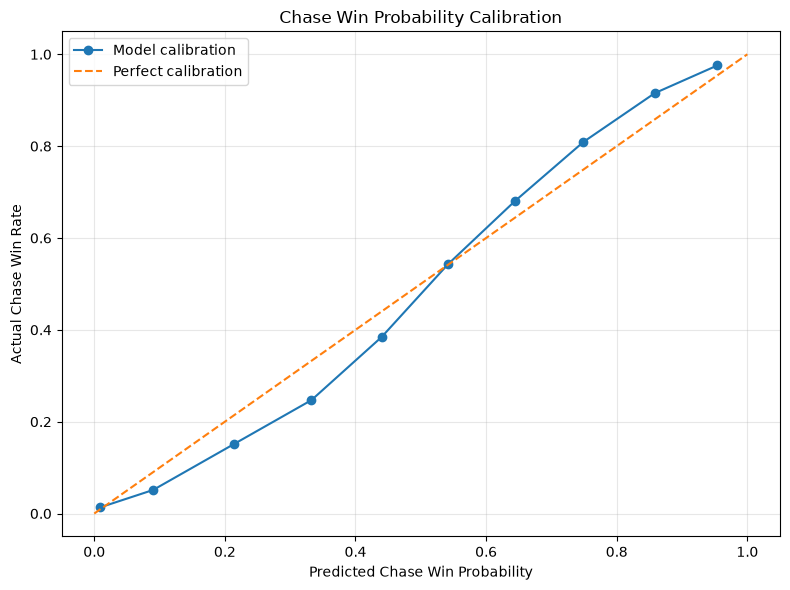

In [48]:
# STEP 35: Plot calibration curve

plt.figure(figsize=(8, 6))

plt.plot(
    calibration_table["predicted_win_probability"],
    calibration_table["actual_win_rate"],
    marker="o",
    label="Model calibration"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.xlabel("Predicted Chase Win Probability")
plt.ylabel("Actual Chase Win Rate")
plt.title("Chase Win Probability Calibration")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [49]:
# STEP 36: Check calibration separately by format

calibration_data = chase_model_data.copy()

# Create probability groups separately for each format
calibration_data["probability_bin"] = np.nan

for fmt, indexes in calibration_data.groupby("match_format").groups.items():

    calibration_data.loc[indexes, "probability_bin"] = pd.qcut(
        calibration_data.loc[indexes, "chase_win_probability"],
        q=10,
        labels=False,
        duplicates="drop"
    )

# Compare predicted probability with actual win rate
format_calibration = (
    calibration_data.groupby(
        ["match_format", "probability_bin"]
    )
    .agg(
        deliveries=("match_id", "size"),
        matches=("match_id", "nunique"),
        predicted_probability=("chase_win_probability", "mean"),
        actual_win_rate=("chase_won", "mean")
    )
    .reset_index()
)

format_calibration["calibration_error"] = (
    format_calibration["actual_win_rate"]
    - format_calibration["predicted_probability"]
)

print("FORMAT-WISE CHASE MODEL CALIBRATION")

display(format_calibration.round(3))

print("\nMean absolute calibration error by format:")

display(
    format_calibration.groupby("match_format")
    ["calibration_error"]
    .apply(lambda x: x.abs().mean())
    .round(3)
    .to_frame("mean_absolute_calibration_error")
)

FORMAT-WISE CHASE MODEL CALIBRATION


,match_format,probability_bin,deliveries,matches,predicted_probability,actual_win_rate,calibration_error
0,T20,0.0,4206,180,0.013,0.020,0.007
1,T20,1.0,4206,199,0.115,0.084,-0.032
2,T20,2.0,4204,208,0.251,0.174,-0.077
3,T20,3.0,4205,226,0.363,0.290,-0.073
4,T20,4.0,4205,238,0.465,0.436,-0.029
5,T20,5.0,4205,242,0.571,0.596,0.025
6,T20,6.0,4205,241,0.669,0.697,0.028
7,T20,7.0,4205,218,0.769,0.806,0.037
8,T20,8.0,4205,193,0.868,0.908,0.040
9,T20,9.0,4206,175,0.956,0.971,0.015



Mean absolute calibration error by format:


,mean_absolute_calibration_error
match_format,
T20,0.036
T20I,0.051


In [50]:
# STEP 37: Evaluate chase model separately by format

from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    brier_score_loss,
    log_loss
)

format_metrics = []

for fmt, group in chase_model_data.groupby("match_format"):

    actual = group["chase_won"]
    predicted = group["chase_win_probability"]

    format_metrics.append({
        "Format": fmt,
        "Deliveries": len(group),
        "Matches": group["match_id"].nunique(),
        "ROC_AUC": roc_auc_score(actual, predicted),
        "Accuracy": accuracy_score(actual, predicted >= 0.5),
        "Brier_Score": brier_score_loss(actual, predicted),
        "Log_Loss": log_loss(actual, predicted)
    })

format_metrics = pd.DataFrame(format_metrics)

print("CHASE MODEL PERFORMANCE BY FORMAT")

display(format_metrics.round(4))

CHASE MODEL PERFORMANCE BY FORMAT


,Format,Deliveries,Matches,ROC_AUC,Accuracy,Brier_Score,Log_Loss
0,T20,42052,362,0.8808,0.7991,0.1420,0.4387
1,T20I,49739,450,0.9035,0.8169,0.1288,0.4009


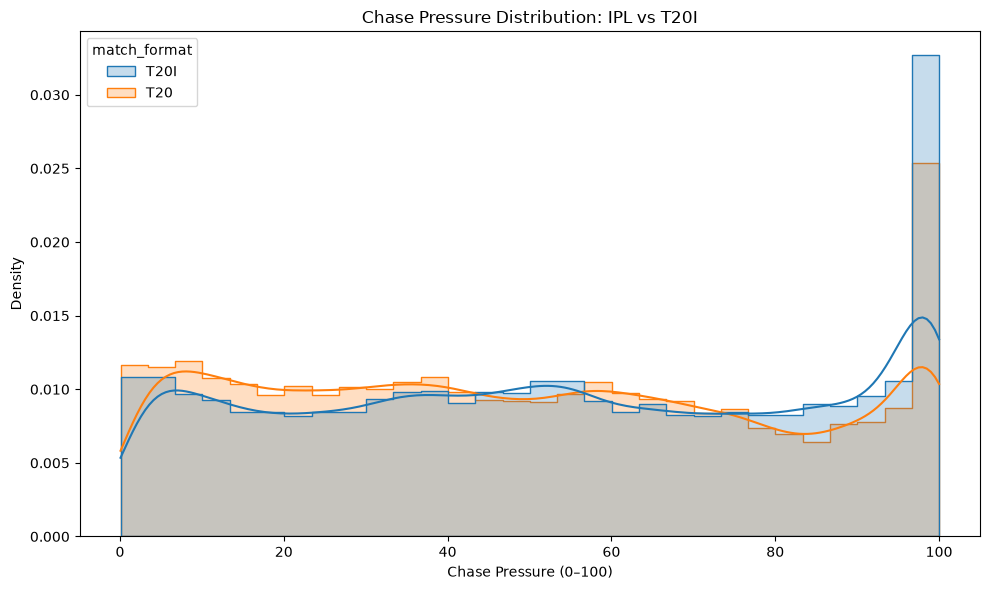

In [51]:
# STEP 38: Compare chase pressure across formats

plt.figure(figsize=(10, 6))

sns.histplot(
    data=chase_model_data,
    x="chase_pressure",
    hue="match_format",
    bins=30,
    kde=True,
    stat="density",
    common_norm=False,
    element="step"
)

plt.title("Chase Pressure Distribution: IPL vs T20I")
plt.xlabel("Chase Pressure (0–100)")
plt.ylabel("Density")

plt.tight_layout()
plt.show()

In [52]:
# STEP 39: Audit player-level columns

print("AVAILABLE PLAYER AND DELIVERY COLUMNS")

player_columns = [
    col for col in analysis.columns
    if any(
        word in col.lower()
        for word in [
            "striker",
            "batter",
            "batsman",
            "bowler",
            "player",
            "runs",
            "dismissal",
            "wicket",
            "extras"
        ]
    )
]

print(player_columns)

print("\nPLAYER IDENTIFIER VALIDATION")

for col in [
    "striker_id",
    "striker_name",
    "non_striker_id",
    "bowler_id",
    "bowler_name"
]:
    if col in analysis.columns:
        print(
            f"{col}:",
            "Missing =", analysis[col].isna().sum(),
            "| Unique =", analysis[col].nunique()
        )

print("\nSAMPLE PLAYER RECORDS")

display(
    analysis[
        [c for c in player_columns if c in analysis.columns]
    ].head(10)
)

AVAILABLE PLAYER AND DELIVERY COLUMNS
['striker_id', 'striker_name', 'non_striker_id', 'non_striker_name', 'bowler_id', 'bowler_name', 'runs', 'is_wicket', 'dismissal_type_id', 'dismissal_type', 'dismissed_player_id', 'extras_type', 'extras1_runs', 'extras_2_runs', 'team_runs', 'uncertain_extras', 'team_wicket', 'bowler_wicket', 'wickets_before', 'wickets_remaining', 'runs_required']

PLAYER IDENTIFIER VALIDATION
striker_id: Missing = 0 | Unique = 824
striker_name: Missing = 0 | Unique = 822
non_striker_id: Missing = 0 | Unique = 805
bowler_id: Missing = 0 | Unique = 595
bowler_name: Missing = 0 | Unique = 595

SAMPLE PLAYER RECORDS


,striker_id,striker_name,non_striker_id,non_striker_name,bowler_id,bowler_name,runs,is_wicket,dismissal_type_id,dismissal_type,...,extras_type,extras1_runs,extras_2_runs,team_runs,uncertain_extras,team_wicket,bowler_wicket,wickets_before,wickets_remaining,runs_required
0,1187,Jason Roy,6273,Tom Banton,1772,Sheldon Cottrell,0,False,NaN,NaN,...,NaN,0,0,0,False,0,0,0,10,NaN
1,1187,Jason Roy,6273,Tom Banton,1772,Sheldon Cottrell,0,False,NaN,NaN,...,NaN,0,0,0,False,0,0,0,10,NaN
2,1187,Jason Roy,6273,Tom Banton,1772,Sheldon Cottrell,0,False,NaN,NaN,...,NaN,0,0,0,False,0,0,0,10,NaN
3,1187,Jason Roy,6273,Tom Banton,1772,Sheldon Cottrell,0,False,NaN,NaN,...,NaN,0,0,0,False,0,0,0,10,NaN
4,1187,Jason Roy,6273,Tom Banton,1772,Sheldon Cottrell,6,False,NaN,NaN,...,NaN,0,0,6,False,0,0,0,10,NaN
5,1187,Jason Roy,6273,Tom Banton,1772,Sheldon Cottrell,0,True,1.0,Bowled,...,NaN,0,0,0,False,1,1,0,10,NaN
6,6273,Tom Banton,1210,James Vince,2633,Jason Holder,0,False,NaN,NaN,...,NaN,0,0,0,False,0,0,1,9,NaN
7,6273,Tom Banton,1210,James Vince,2633,Jason Holder,0,False,NaN,NaN,...,NaN,0,0,0,False,0,0,1,9,NaN
8,6273,Tom Banton,1210,James Vince,2633,Jason Holder,0,False,NaN,NaN,...,NaN,0,0,0,False,0,0,1,9,NaN
9,6273,Tom Banton,1210,James Vince,2633,Jason Holder,4,False,NaN,NaN,...,NaN,0,0,4,False,0,0,1,9,NaN


In [53]:
# STEP 40: Inspect player participation

if "striker_id" in analysis.columns:
    print("TOP 15 BATTERS BY DELIVERY COUNT")

    display(
        analysis.groupby(
            ["striker_id", "striker_name"]
        )
        .agg(
            deliveries=("match_id", "size"),
            matches=("match_id", "nunique")
        )
        .sort_values("deliveries", ascending=False)
        .head(15)
    )

if "bowler_id" in analysis.columns:
    print("\nTOP 15 BOWLERS BY DELIVERY COUNT")

    display(
        analysis.groupby("bowler_id")
        .agg(
            deliveries=("match_id", "size"),
            matches=("match_id", "nunique")
        )
        .sort_values("deliveries", ascending=False)
        .head(15)
    )

TOP 15 BATTERS BY DELIVERY COUNT


,,deliveries,matches
striker_id,striker_name,,
813,Jos Buttler,2894,120
1699,Suryakumar Yadav,2821,138
6288,Shubman Gill,2768,110
47,Virat Kohli,2545,92
7897,Namboori Tilak Varma,2507,121
4117,Ishan Kishan,2483,119
6281,Abhishek Sharma,2314,126
2258,Sanju Samson,2289,122
953,Lokesh Rahul,2069,73



TOP 15 BOWLERS BY DELIVERY COUNT


,deliveries,matches
bowler_id,,
6464,3410,146
4722,2778,122
2876,2693,135
7503,2429,109
360,2313,101
19316,2296,98
1612,2218,98
6256,2182,95
4900,2053,91


In [54]:
# STEP 41: Inspect delivery identifiers

print("ANALYSIS DATAFRAME INDEX")
print("Unique index:", analysis.index.is_unique)

print("\nAVAILABLE IDENTIFIER COLUMNS")

id_columns = [
    col for col in analysis.columns
    if any(
        word in col.lower()
        for word in [
            "delivery",
            "ball_id",
            "match_id",
            "innings",
            "over",
            "ball"
        ]
    )
]

print(id_columns)

print("\nDUPLICATE INDEX CHECK")
print("Duplicate index values:", analysis.index.duplicated().sum())

print("\nSAMPLE DELIVERY IDENTIFIERS")

display(
    analysis[id_columns].head(10)
)

ANALYSIS DATAFRAME INDEX
Unique index: True

AVAILABLE IDENTIFIER COLUMNS
['match_id', 'innings', 'overid', 'over_ball_num', 'innings_ball_num', 'delivery_style', 'over_or_around', 'delivery_ist_time', 'first_inn_revised_overs', 'second_inn_revised_overs', 'is_no_ball', 'legal_ball', 'legal_balls_before', 'max_legal_balls', 'balls_remaining', 'first_innings_total', 'overs_completed', 'innings_progress', 'innings_phase']

DUPLICATE INDEX CHECK
Duplicate index values: 0

SAMPLE DELIVERY IDENTIFIERS


,match_id,innings,overid,over_ball_num,innings_ball_num,delivery_style,over_or_around,delivery_ist_time,first_inn_revised_overs,second_inn_revised_overs,is_no_ball,legal_ball,legal_balls_before,max_legal_balls,balls_remaining,first_innings_total,overs_completed,innings_progress,innings_phase
0,13511,1,1,1,1,Inswing,Over,2022-01-23 00:00:00 UTC,NaN,NaN,False,True,0,120.0,120.0,103,0,0.000000,Powerplay
1,13511,1,1,2,2,Inswing,Over,2022-01-23 00:00:00 UTC,NaN,NaN,False,True,1,120.0,119.0,103,0,0.008333,Powerplay
2,13511,1,1,3,3,Inswing,Over,2022-01-23 00:00:00 UTC,NaN,NaN,False,True,2,120.0,118.0,103,0,0.016667,Powerplay
3,13511,1,1,4,4,Inswing,Over,2022-01-23 00:00:00 UTC,NaN,NaN,False,True,3,120.0,117.0,103,0,0.025000,Powerplay
4,13511,1,1,5,5,Seamed In,Over,2022-01-23 00:00:00 UTC,NaN,NaN,False,True,4,120.0,116.0,103,0,0.033333,Powerplay
5,13511,1,1,6,6,Full Toss,Over,2022-01-23 00:00:00 UTC,NaN,NaN,False,True,5,120.0,115.0,103,0,0.041667,Powerplay
6,13511,1,2,1,7,Out Swing,Over,2022-01-23 00:00:00 UTC,NaN,NaN,False,True,6,120.0,114.0,103,1,0.050000,Powerplay
7,13511,1,2,2,8,Out Swing,Over,2022-01-23 00:00:00 UTC,NaN,NaN,False,True,7,120.0,113.0,103,1,0.058333,Powerplay
8,13511,1,2,3,9,Out Swing,Over,2022-01-23 00:00:00 UTC,NaN,NaN,False,True,8,120.0,112.0,103,1,0.066667,Powerplay
9,13511,1,2,4,10,NaN,Over,2022-01-23 00:00:00 UTC,NaN,NaN,False,True,9,120.0,111.0,103,1,0.075000,Powerplay


In [55]:
# STEP 42: Batter and bowler participation with names

print("TOP 15 BATTERS")

batter_participation = (
    analysis.groupby(["striker_id", "striker_name"])
    .agg(
        deliveries=("match_id", "size"),
        matches=("match_id", "nunique")
    )
    .sort_values("deliveries", ascending=False)
    .head(15)
)

display(batter_participation)

print("\nTOP 15 BOWLERS")

bowler_participation = (
    analysis.groupby(["bowler_id", "bowler_name"])
    .agg(
        deliveries=("match_id", "size"),
        matches=("match_id", "nunique")
    )
    .sort_values("deliveries", ascending=False)
    .head(15)
)

display(bowler_participation)

TOP 15 BATTERS


,,deliveries,matches
striker_id,striker_name,,
813,Jos Buttler,2894,120
1699,Suryakumar Yadav,2821,138
6288,Shubman Gill,2768,110
47,Virat Kohli,2545,92
7897,Namboori Tilak Varma,2507,121
4117,Ishan Kishan,2483,119
6281,Abhishek Sharma,2314,126
2258,Sanju Samson,2289,122
953,Lokesh Rahul,2069,73



TOP 15 BOWLERS


,,deliveries,matches
bowler_id,bowler_name,,
6464,Arshdeep Singh,3410,146
4722,Rashid Khan,2778,122
2876,Axar Patel,2693,135
7503,Ravi Bishnoi,2429,109
360,Bhuvneshwar Kumar,2313,101
19316,Maheesh Theekshana,2296,98
1612,Yuzvendra Chahal,2218,98
6256,Varun Chakravarthy,2182,95
4900,Wanindu Hasaranga,2053,91


In [56]:
# STEP 43: Validate unique delivery identifiers

delivery_key = [
    "match_id",
    "innings",
    "innings_ball_num"
]

print("DELIVERY KEY VALIDATION")

print("Total deliveries:", len(analysis))

print(
    "Unique delivery combinations:",
    analysis[delivery_key].drop_duplicates().shape[0]
)

print(
    "Duplicate delivery combinations:",
    analysis.duplicated(delivery_key).sum()
)

assert analysis.duplicated(delivery_key).sum() == 0, (
    "Duplicate delivery identifiers found!"
)

print("\nDelivery key is unique.")

DELIVERY KEY VALIDATION
Total deliveries: 192270
Unique delivery combinations: 192270
Duplicate delivery combinations: 0

Delivery key is unique.


In [57]:
# STEP 44: Combine pressure scores with delivery data

delivery_key = [
    "match_id",
    "innings",
    "innings_ball_num"
]

# First-innings pressure
first_pressure = first[
    delivery_key + ["pressure_z", "scoring_deficit"]
].copy()

first_pressure = first_pressure.rename(columns={
    "pressure_z": "first_innings_pressure",
    "scoring_deficit": "first_innings_deficit"
})

# Second-innings chase pressure
chase_pressure_data = chase_model_data[
    delivery_key + ["chase_pressure", "chase_win_probability"]
].copy()

# Combine the two pressure datasets
pressure_scores = pd.concat(
    [
        first_pressure.rename(columns={
            "first_innings_pressure": "pressure_score",
            "first_innings_deficit": "pressure_deficit"
        }),
        chase_pressure_data.rename(columns={
            "chase_pressure": "pressure_score",
            "chase_win_probability": "chase_win_probability"
        })
    ],
    ignore_index=True
)

# Merge pressure scores with original delivery data
player_pressure_data = analysis.merge(
    pressure_scores,
    on=delivery_key,
    how="left",
    validate="one_to_one"
)

print("COMBINED PLAYER PRESSURE DATA")

print("Total deliveries:", len(player_pressure_data))

print(
    "Deliveries with pressure scores:",
    player_pressure_data["pressure_score"].notna().sum()
)

print(
    "Missing pressure scores:",
    player_pressure_data["pressure_score"].isna().sum()
)

print("\nPressure availability by innings:")

display(
    player_pressure_data.groupby("innings")
    .agg(
        deliveries=("match_id", "size"),
        pressure_available=("pressure_score", "count")
    )
)

display(
    player_pressure_data[
        [
            "match_id",
            "innings",
            "innings_ball_num",
            "striker_name",
            "bowler_name",
            "pressure_score"
        ]
    ].head(15)
)

COMBINED PLAYER PRESSURE DATA
Total deliveries: 192270
Deliveries with pressure scores: 192182
Missing pressure scores: 88

Pressure availability by innings:


,deliveries,pressure_available
innings,,
1,100391,100391
2,91879,91791


,match_id,innings,innings_ball_num,striker_name,bowler_name,pressure_score
0,13511,1,1,Jason Roy,Sheldon Cottrell,0.016033
1,13511,1,2,Jason Roy,Sheldon Cottrell,0.250575
2,13511,1,3,Jason Roy,Sheldon Cottrell,0.553621
3,13511,1,4,Jason Roy,Sheldon Cottrell,0.872840
4,13511,1,5,Jason Roy,Sheldon Cottrell,1.228576
5,13511,1,6,Jason Roy,Sheldon Cottrell,-0.045932
6,13511,1,7,Tom Banton,Jason Holder,-0.225246
7,13511,1,8,Tom Banton,Jason Holder,0.075142
8,13511,1,9,Tom Banton,Jason Holder,0.442150
9,13511,1,10,Tom Banton,Jason Holder,0.676277


In [60]:
# STEP 45: Correct pressure delivery classification

player_pressure_data["pressure_type"] = np.where(
    player_pressure_data["innings"] == 1,
    "First Innings",
    "Chase"
)

# Start with missing classifications
player_pressure_data["is_pressure_delivery"] = pd.Series(
    pd.NA,
    index=player_pressure_data.index,
    dtype="boolean"
)

# First innings: standardized deficit >= 1
first_mask = (
    (player_pressure_data["innings"] == 1)
    & player_pressure_data["pressure_score"].notna()
)

player_pressure_data.loc[
    first_mask, "is_pressure_delivery"
] = (
    player_pressure_data.loc[first_mask, "pressure_score"] >= 1
)

# Chase: predicted win probability <= 20%
chase_mask = (
    (player_pressure_data["innings"] == 2)
    & player_pressure_data["chase_win_probability"].notna()
)

player_pressure_data.loc[
    chase_mask, "is_pressure_delivery"
] = (
    player_pressure_data.loc[
        chase_mask, "chase_win_probability"
    ] <= 0.20
)

print("CORRECTED PRESSURE CLASSIFICATION")

display(
    player_pressure_data.groupby(
        ["pressure_type", "is_pressure_delivery"],
        dropna=False
    )
    .agg(
        deliveries=("match_id", "size"),
        matches=("match_id", "nunique")
    )
    .reset_index()
)

CORRECTED PRESSURE CLASSIFICATION


,pressure_type,is_pressure_delivery,deliveries,matches
0,Chase,False,69893,796
1,Chase,True,21898,461
2,Chase,<NA>,88,3
3,First Innings,False,86159,815
4,First Innings,True,14232,508


In [61]:
# STEP 46: Validate corrected pressure classifications

print("MISSING PRESSURE CLASSIFICATIONS:")

print(
    player_pressure_data["is_pressure_delivery"].isna().sum()
)

print("\nClassification by innings:")

display(
    player_pressure_data.groupby(
        ["innings", "is_pressure_delivery"],
        dropna=False
    )
    .agg(
        deliveries=("match_id", "size"),
        matches=("match_id", "nunique")
    )
)

MISSING PRESSURE CLASSIFICATIONS:
88

Classification by innings:


deliveries  matches
innings is_pressure_delivery                     
1       False                      86159      815
        True                       14232      508
2       False                      69893      796
        True                       21898      461
        <NA>                          88        3

In [62]:
# STEP 47: Prepare batter performance dataset

batter_data = player_pressure_data[
    player_pressure_data["is_pressure_delivery"].notna()
].copy()

# Batter runs scored
batter_data["batter_runs"] = batter_data["runs"]

# Identify dot balls
batter_data["is_dot_ball"] = (
    batter_data["batter_runs"] == 0
)

# Identify boundaries
batter_data["is_boundary"] = (
    batter_data["batter_runs"].isin([4, 6])
)

# Identify dismissals of the striker
batter_data["is_striker_out"] = (
    batter_data["dismissed_player_id"]
    == batter_data["striker_id"]
)

print("BATTER DATASET")

print("Total deliveries:", len(batter_data))

print("Unique batters:", batter_data["striker_id"].nunique())

print("Unique matches:", batter_data["match_id"].nunique())

print("\nPressure distribution:")

display(
    batter_data.groupby("is_pressure_delivery")
    .agg(
        deliveries=("match_id", "size"),
        batters=("striker_id", "nunique"),
        matches=("match_id", "nunique"),
        batter_runs=("batter_runs", "sum")
    )
)

BATTER DATASET
Total deliveries: 192182
Unique batters: 824
Unique matches: 815

Pressure distribution:


,deliveries,batters,matches,batter_runs
is_pressure_delivery,,,,
False,156052,760,815,210455
True,36130,711,708,48223


In [63]:
# STEP 48: Aggregate batter performance

batter_performance = (
    batter_data.groupby(
        [
            "striker_id",
            "striker_name",
            "is_pressure_delivery"
        ]
    )
    .agg(
        runs=("batter_runs", "sum"),
        balls=("legal_ball", "sum"),
        dot_balls=("is_dot_ball", "sum"),
        boundaries=("is_boundary", "sum"),
        dismissals=("is_striker_out", "sum"),
        matches=("match_id", "nunique")
    )
    .reset_index()
)

# Calculate batting metrics
batter_performance["strike_rate"] = (
    batter_performance["runs"]
    / batter_performance["balls"].replace(0, np.nan)
) * 100

batter_performance["dot_ball_pct"] = (
    batter_performance["dot_balls"]
    / batter_performance["balls"].replace(0, np.nan)
) * 100

batter_performance["boundary_pct"] = (
    batter_performance["boundaries"]
    / batter_performance["balls"].replace(0, np.nan)
) * 100

print("BATTER PERFORMANCE SUMMARY")

display(
    batter_performance.sort_values(
        ["striker_id", "is_pressure_delivery"]
    ).head(20).round(2)
)

BATTER PERFORMANCE SUMMARY


,striker_id,striker_name,is_pressure_delivery,runs,balls,dot_balls,boundaries,dismissals,matches,strike_rate,dot_ball_pct,boundary_pct
0,8,Mahendra Singh Dhoni,False,319,221,103,44,10,33,144.34,46.61,19.91
1,8,Mahendra Singh Dhoni,True,366,234,99,51,11,22,156.41,42.31,21.79
2,23,Piyush Chawla,False,10,15,5,0,1,4,66.67,33.33,0.00
3,23,Piyush Chawla,True,30,22,11,4,5,6,136.36,50.00,18.18
4,28,Ishant Sharma,False,1,1,0,0,0,1,100.00,0.00,0.00
5,28,Ishant Sharma,True,1,7,7,0,0,2,14.29,100.00,0.00
6,47,Virat Kohli,False,3220,2238,755,422,69,91,143.88,33.74,18.86
7,47,Virat Kohli,True,347,217,63,46,6,24,159.91,29.03,21.20
8,88,Faf du Plessis,False,1446,1027,389,202,42,53,140.80,37.88,19.67
9,88,Faf du Plessis,True,389,238,73,50,8,20,163.45,30.67,21.01


In [64]:
# STEP 49: Correct batter delivery statistics

batter_data = player_pressure_data[
    player_pressure_data["is_pressure_delivery"].notna()
].copy()

# Batter runs
batter_data["batter_runs"] = batter_data["runs"]

# A ball faced excludes wides, but includes no-balls
batter_data["ball_faced"] = (
    batter_data["extras_type"] != "wide"
)

# Dot ball: faced delivery with zero batter runs,
# excluding no-ball deliveries
batter_data["is_dot_ball"] = (
    batter_data["ball_faced"]
    & batter_data["legal_ball"]
    & (batter_data["batter_runs"] == 0)
)

# Boundaries
batter_data["is_boundary"] = (
    batter_data["batter_runs"].isin([4, 6])
)

# Striker dismissed
batter_data["is_striker_out"] = (
    batter_data["dismissed_player_id"]
    == batter_data["striker_id"]
)

print("CORRECTED BATTER DATA")

print("Total deliveries:", len(batter_data))
print("Balls faced:", batter_data["ball_faced"].sum())
print("Dot balls:", batter_data["is_dot_ball"].sum())
print("Boundaries:", batter_data["is_boundary"].sum())
print("Striker dismissals:", batter_data["is_striker_out"].sum())

CORRECTED BATTER DATA
Total deliveries: 192182
Balls faced: 184772
Dot balls: 68112
Boundaries: 34779
Striker dismissals: 10115


In [65]:
# STEP 50: Recalculate batter performance

batter_performance = (
    batter_data.groupby(
        [
            "striker_id",
            "striker_name",
            "is_pressure_delivery"
        ]
    )
    .agg(
        runs=("batter_runs", "sum"),
        balls=("ball_faced", "sum"),
        dot_balls=("is_dot_ball", "sum"),
        boundaries=("is_boundary", "sum"),
        dismissals=("is_striker_out", "sum"),
        matches=("match_id", "nunique")
    )
    .reset_index()
)

# Strike rate
batter_performance["strike_rate"] = (
    batter_performance["runs"]
    / batter_performance["balls"].replace(0, np.nan)
) * 100

# Dot ball percentage
batter_performance["dot_ball_pct"] = (
    batter_performance["dot_balls"]
    / batter_performance["balls"].replace(0, np.nan)
) * 100

# Boundary percentage
batter_performance["boundary_pct"] = (
    batter_performance["boundaries"]
    / batter_performance["balls"].replace(0, np.nan)
) * 100

print("CORRECTED BATTER PERFORMANCE")

display(
    batter_performance.sort_values(
        ["striker_id", "is_pressure_delivery"]
    ).head(20).round(2)
)

CORRECTED BATTER PERFORMANCE


,striker_id,striker_name,is_pressure_delivery,runs,balls,dot_balls,boundaries,dismissals,matches,strike_rate,dot_ball_pct,boundary_pct
0,8,Mahendra Singh Dhoni,False,319,221,86,44,10,33,144.34,38.91,19.91
1,8,Mahendra Singh Dhoni,True,366,236,82,51,11,22,155.08,34.75,21.61
2,23,Piyush Chawla,False,10,15,5,0,1,4,66.67,33.33,0.00
3,23,Piyush Chawla,True,30,22,11,4,5,6,136.36,50.00,18.18
4,28,Ishant Sharma,False,1,1,0,0,0,1,100.00,0.00,0.00
5,28,Ishant Sharma,True,1,7,6,0,0,2,14.29,85.71,0.00
6,47,Virat Kohli,False,3220,2239,672,422,69,91,143.81,30.01,18.85
7,47,Virat Kohli,True,347,217,57,46,6,24,159.91,26.27,21.20
8,88,Faf du Plessis,False,1446,1030,371,202,42,53,140.39,36.02,19.61
9,88,Faf du Plessis,True,389,238,62,50,8,20,163.45,26.05,21.01


In [66]:
# STEP 51: Audit batter dismissal types

print("DISMISSAL TYPE DISTRIBUTION")

display(
    batter_data[
        batter_data["is_striker_out"]
    ]["dismissal_type"]
    .value_counts(dropna=False)
    .to_frame("count")
)

DISMISSAL TYPE DISTRIBUTION


,count
dismissal_type,
Caught,7254
Bowled,1672
LBW,663
RunOut,298
Stump,198
Hit Wicket,17
NaN,8
Retire Out,3
Obstracting the field,1


In [67]:
# STEP 52: Validate batter dismissals

print("DISMISSAL VALIDATION")

dismissal_audit = (
    batter_data[
        batter_data["is_striker_out"]
    ]
    .groupby("dismissal_type", dropna=False)
    .agg(
        dismissals=("striker_id", "size"),
        batters=("striker_id", "nunique"),
        matches=("match_id", "nunique")
    )
    .reset_index()
)

display(dismissal_audit)

print("\nTotal striker dismissals:")
print(batter_data["is_striker_out"].sum())

print("\nDismissals with missing dismissal type:")
print(
    batter_data[
        batter_data["is_striker_out"]
        & batter_data["dismissal_type"].isna()
    ].shape[0]
)

DISMISSAL VALIDATION


,dismissal_type,dismissals,batters,matches
0,Bowled,1672,465,694
1,Caught,7254,676,814
2,Hit Wicket,17,14,17
3,LBW,663,320,419
4,Obstracting the field,1,1,1
5,Obstructing the field,1,1,1
6,Retire Out,3,3,3
7,RunOut,298,201,249
8,Stump,198,144,171
9,NaN,8,8,8



Total striker dismissals:
10115

Dismissals with missing dismissal type:
8


In [68]:
# STEP 53: Validate balls faced and dot balls

print("BALLS FACED AND DOT BALL VALIDATION")

print(
    "Wide deliveries:",
    (batter_data["extras_type"] == "wide").sum()
)

print(
    "No-ball deliveries:",
    (batter_data["is_no_ball"]).sum()
)

print(
    "Balls faced:",
    batter_data["ball_faced"].sum()
)

print(
    "Dot balls:",
    batter_data["is_dot_ball"].sum()
)

print(
    "Dot ball percentage:",
    round(
        batter_data["is_dot_ball"].sum()
        / batter_data["ball_faced"].sum() * 100,
        2
    )
)

print("\nPressure vs non-pressure dot-ball percentage:")

display(
    batter_data.groupby("is_pressure_delivery")
    .agg(
        balls_faced=("ball_faced", "sum"),
        dot_balls=("is_dot_ball", "sum")
    )
    .assign(
        dot_ball_pct=lambda x:
        x["dot_balls"] / x["balls_faced"] * 100
    )
    .round(2)
)

BALLS FACED AND DOT BALL VALIDATION
Wide deliveries: 7410
No-ball deliveries: 556
Balls faced: 184772
Dot balls: 68112
Dot ball percentage: 36.86

Pressure vs non-pressure dot-ball percentage:


,balls_faced,dot_balls,dot_ball_pct
is_pressure_delivery,,,
False,150142,55020,36.65
True,34630,13092,37.81


In [69]:
# STEP 54: Create batter comparison table

batter_comparison = batter_performance.pivot(
    index=["striker_id", "striker_name"],
    columns="is_pressure_delivery",
    values=[
        "runs",
        "balls",
        "strike_rate",
        "dot_ball_pct",
        "boundary_pct",
        "dismissals",
        "matches"
    ]
)

# Flatten column names
batter_comparison.columns = [
    f"{metric}_{'pressure' if pressure else 'normal'}"
    for metric, pressure in batter_comparison.columns
]

batter_comparison = batter_comparison.reset_index()

print("BATTER PRESSURE VS NORMAL PERFORMANCE")

display(
    batter_comparison.head(15).round(2)
)

print("\nTotal unique batters:", len(batter_comparison))

BATTER PRESSURE VS NORMAL PERFORMANCE


,striker_id,striker_name,runs_normal,runs_pressure,balls_normal,balls_pressure,strike_rate_normal,strike_rate_pressure,dot_ball_pct_normal,dot_ball_pct_pressure,boundary_pct_normal,boundary_pct_pressure,dismissals_normal,dismissals_pressure,matches_normal,matches_pressure
0,8,Mahendra Singh Dhoni,319.0,366.0,221.0,236.0,144.34,155.08,38.91,34.75,19.91,21.61,10.0,11.0,33.0,22.0
1,23,Piyush Chawla,10.0,30.0,15.0,22.0,66.67,136.36,33.33,50.00,0.00,18.18,1.0,5.0,4.0,6.0
2,28,Ishant Sharma,1.0,1.0,1.0,7.0,100.00,14.29,0.00,85.71,0.00,0.00,0.0,0.0,1.0,2.0
3,47,Virat Kohli,3220.0,347.0,2239.0,217.0,143.81,159.91,30.01,26.27,18.85,21.20,69.0,6.0,91.0,24.0
4,88,Faf du Plessis,1446.0,389.0,1030.0,238.0,140.39,163.45,36.02,26.05,19.61,21.01,42.0,8.0,53.0,20.0
5,109,Wriddhiman Saha,754.0,70.0,607.0,54.0,124.22,129.63,41.35,38.89,18.62,18.52,31.0,3.0,37.0,7.0
6,126,Rohit Sharma,2168.0,161.0,1519.0,100.0,142.73,161.00,42.59,47.00,21.99,28.00,82.0,4.0,91.0,19.0
7,142,Shikhar Dhawan,874.0,111.0,675.0,82.0,129.48,135.37,40.59,29.27,18.96,17.07,24.0,2.0,29.0,6.0
8,143,Dinesh Karthik,734.0,329.0,463.0,174.0,158.53,189.08,31.97,31.61,22.68,29.31,22.0,12.0,50.0,18.0
9,147,Pradeep Sangwan,2.0,0.0,4.0,1.0,50.00,0.00,50.00,100.00,0.00,0.00,0.0,1.0,1.0,1.0



Total unique batters: 824


In [70]:
# STEP 55: Calculate pressure performance differences

batter_comparison["strike_rate_difference"] = (
    batter_comparison["strike_rate_pressure"]
    - batter_comparison["strike_rate_normal"]
)

batter_comparison["dot_ball_difference"] = (
    batter_comparison["dot_ball_pct_normal"]
    - batter_comparison["dot_ball_pct_pressure"]
)

batter_comparison["boundary_difference"] = (
    batter_comparison["boundary_pct_pressure"]
    - batter_comparison["boundary_pct_normal"]
)

print("PRESSURE PERFORMANCE DIFFERENCES")

display(
    batter_comparison[
        [
            "striker_name",
            "strike_rate_pressure",
            "strike_rate_normal",
            "strike_rate_difference",
            "dot_ball_difference",
            "boundary_difference"
        ]
    ]
    .sort_values("strike_rate_difference", ascending=False)
    .head(20)
    .round(2)
)

PRESSURE PERFORMANCE DIFFERENCES


,striker_name,strike_rate_pressure,strike_rate_normal,strike_rate_difference,dot_ball_difference,boundary_difference
767,Jewel Andrew,600.00,97.89,502.11,55.79,88.42
800,Sahil Parakh,600.00,125.00,475.00,43.75,81.25
540,Monank Patel,400.00,105.56,294.44,72.22,77.78
18,Tom Cooper,400.00,114.29,285.71,38.10,90.48
64,Mandeep Singh,300.00,70.27,229.73,14.86,39.19
737,Saiteja Mukkamalla,400.00,171.43,228.57,38.10,71.43
722,Kamil Pooran,300.00,106.25,193.75,15.62,34.38
574,Jayden Seales,175.00,0.00,175.00,75.00,25.00
778,Noah Croes,240.00,69.77,170.23,34.19,37.67
675,Umran Malik,164.71,0.00,164.71,58.82,23.53


In [71]:
# STEP 56: Pressure sample size analysis

print("BATTER PRESSURE SAMPLE SIZES")

display(
    batter_comparison[
        [
            "striker_name",
            "runs_pressure",
            "balls_pressure",
            "matches_pressure",
            "strike_rate_pressure"
        ]
    ]
    .sort_values("balls_pressure", ascending=False)
    .head(20)
    .round(2)
)

BATTER PRESSURE SAMPLE SIZES


,striker_name,runs_pressure,balls_pressure,matches_pressure,strike_rate_pressure
353,Rovman Powell,651.0,424.0,40.0,153.54
532,Namboori Tilak Varma,603.0,392.0,31.0,153.83
96,Suryakumar Yadav,635.0,369.0,30.0,172.09
68,David Miller,581.0,368.0,35.0,157.88
194,Shimron Hetmyer,565.0,364.0,33.0,155.22
52,Jos Buttler,561.0,352.0,34.0,159.38
199,Hardik Pandya,469.0,325.0,29.0,144.31
184,Nicholas Pooran,510.0,313.0,36.0,162.94
416,Ibrahim Zadran,403.0,308.0,19.0,130.84
310,Shivam Dube,508.0,304.0,29.0,167.11


In [72]:
# STEP 57: Identify eligible batters

eligible_batters = batter_comparison[
    (batter_comparison["balls_pressure"] >= 100)
    & (batter_comparison["matches_pressure"] >= 10)
    & (batter_comparison["balls_normal"] >= 100)
    & (batter_comparison["matches_normal"] >= 10)
].copy()

print("BATTER ELIGIBILITY")

print("Total batters:", len(batter_comparison))
print("Eligible batters:", len(eligible_batters))
print(
    "Excluded batters:",
    len(batter_comparison) - len(eligible_batters)
)

print("\nELIGIBLE BATTER LIST")

display(
    eligible_batters[
        [
            "striker_name",
            "runs_pressure",
            "balls_pressure",
            "matches_pressure",
            "strike_rate_pressure",
            "strike_rate_normal",
            "strike_rate_difference"
        ]
    ]
    .sort_values("strike_rate_pressure", ascending=False)
    .head(30)
    .round(2)
)

BATTER ELIGIBILITY
Total batters: 824
Eligible batters: 98
Excluded batters: 726

ELIGIBLE BATTER LIST


,striker_name,runs_pressure,balls_pressure,matches_pressure,strike_rate_pressure,strike_rate_normal,strike_rate_difference
409,Tim David,451.0,228.0,25.0,197.81,172.10,25.70
766,Naman Dhir,207.0,106.0,12.0,195.28,161.94,33.34
560,Ashutosh Sharma,263.0,138.0,15.0,190.58,153.25,37.33
306,Rinku Singh,421.0,222.0,17.0,189.64,143.99,45.65
8,Dinesh Karthik,329.0,174.0,18.0,189.08,158.53,30.55
452,Sherfane Rutherford,320.0,172.0,20.0,186.05,139.84,46.20
217,Aiden Markram,518.0,294.0,33.0,176.19,136.24,39.95
57,Glenn Maxwell,365.0,208.0,21.0,175.48,157.76,17.72
132,Kyle Mayers,192.0,111.0,12.0,172.97,135.67,37.30
82,Andre Russell,285.0,165.0,18.0,172.73,170.60,2.13


In [73]:
# STEP 58: Compare eligible batter performance

print("TOP 20 ELIGIBLE BATTERS BY PRESSURE STRIKE RATE")

display(
    eligible_batters[
        [
            "striker_name",
            "runs_pressure",
            "balls_pressure",
            "matches_pressure",
            "strike_rate_pressure",
            "dot_ball_pct_pressure",
            "boundary_pct_pressure",
            "strike_rate_difference"
        ]
    ]
    .sort_values(
        "strike_rate_pressure",
        ascending=False
    )
    .head(20)
    .round(2)
)

TOP 20 ELIGIBLE BATTERS BY PRESSURE STRIKE RATE


,striker_name,runs_pressure,balls_pressure,matches_pressure,strike_rate_pressure,dot_ball_pct_pressure,boundary_pct_pressure,strike_rate_difference
409,Tim David,451.0,228.0,25.0,197.81,28.07,29.39,25.70
766,Naman Dhir,207.0,106.0,12.0,195.28,26.42,29.25,33.34
560,Ashutosh Sharma,263.0,138.0,15.0,190.58,31.16,28.26,37.33
306,Rinku Singh,421.0,222.0,17.0,189.64,29.73,28.38,45.65
8,Dinesh Karthik,329.0,174.0,18.0,189.08,31.61,29.31,30.55
452,Sherfane Rutherford,320.0,172.0,20.0,186.05,34.30,27.33,46.20
217,Aiden Markram,518.0,294.0,33.0,176.19,30.95,26.19,39.95
57,Glenn Maxwell,365.0,208.0,21.0,175.48,30.29,25.96,17.72
132,Kyle Mayers,192.0,111.0,12.0,172.97,40.54,27.03,37.30
82,Andre Russell,285.0,165.0,18.0,172.73,40.61,25.45,2.13


In [74]:
# STEP 59: Reliability-adjusted batting strike rate

baseline_sr = (
    eligible_batters["runs_pressure"].sum()
    / eligible_batters["balls_pressure"].sum()
) * 100

print("Eligible batter baseline pressure SR:", round(baseline_sr, 2))

for k in [50, 100, 150]:

    weight = (
        eligible_batters["balls_pressure"]
        / (eligible_batters["balls_pressure"] + k)
    )

    eligible_batters[f"adjusted_sr_k{k}"] = (
        weight * eligible_batters["strike_rate_pressure"]
        + (1 - weight) * baseline_sr
    )

display(
    eligible_batters[
        [
            "striker_name",
            "balls_pressure",
            "matches_pressure",
            "strike_rate_pressure",
            "adjusted_sr_k50",
            "adjusted_sr_k100",
            "adjusted_sr_k150"
        ]
    ]
    .sort_values("adjusted_sr_k100", ascending=False)
    .head(20)
    .round(2)
)

Eligible batter baseline pressure SR: 152.02


,striker_name,balls_pressure,matches_pressure,strike_rate_pressure,adjusted_sr_k50,adjusted_sr_k100,adjusted_sr_k150
409,Tim David,228.0,25.0,197.81,189.57,183.85,179.64
306,Rinku Singh,222.0,17.0,189.64,182.72,177.96,174.47
8,Dinesh Karthik,174.0,18.0,189.08,180.81,175.55,171.92
560,Ashutosh Sharma,138.0,15.0,190.58,180.32,174.38,170.50
766,Naman Dhir,106.0,12.0,195.28,181.42,174.28,169.93
452,Sherfane Rutherford,172.0,20.0,186.05,178.38,173.54,170.20
217,Aiden Markram,294.0,33.0,176.19,172.68,170.06,168.02
57,Glenn Maxwell,208.0,21.0,175.48,170.93,167.86,165.65
96,Suryakumar Yadav,369.0,30.0,172.09,169.69,167.81,166.29
82,Andre Russell,165.0,18.0,172.73,167.91,164.91,162.87


In [75]:
# STEP 60: Compare rankings under different shrinkage strengths

ranking_sensitivity = eligible_batters[
    [
        "striker_name",
        "adjusted_sr_k50",
        "adjusted_sr_k100",
        "adjusted_sr_k150"
    ]
].copy()

for k in [50, 100, 150]:
    ranking_sensitivity[f"rank_k{k}"] = (
        ranking_sensitivity[f"adjusted_sr_k{k}"]
        .rank(ascending=False, method="min")
    )

print("RANKING SENSITIVITY ANALYSIS")

display(
    ranking_sensitivity.sort_values("rank_k100")
    .head(20)
    .round(2)
)

RANKING SENSITIVITY ANALYSIS


,striker_name,adjusted_sr_k50,adjusted_sr_k100,adjusted_sr_k150,rank_k50,rank_k100,rank_k150
409,Tim David,189.57,183.85,179.64,1.0,1.0,1.0
306,Rinku Singh,182.72,177.96,174.47,2.0,2.0,2.0
8,Dinesh Karthik,180.81,175.55,171.92,4.0,3.0,3.0
560,Ashutosh Sharma,180.32,174.38,170.50,5.0,4.0,4.0
766,Naman Dhir,181.42,174.28,169.93,3.0,5.0,6.0
452,Sherfane Rutherford,178.38,173.54,170.20,6.0,6.0,5.0
217,Aiden Markram,172.68,170.06,168.02,7.0,7.0,7.0
57,Glenn Maxwell,170.93,167.86,165.65,8.0,8.0,9.0
96,Suryakumar Yadav,169.69,167.81,166.29,9.0,9.0,8.0
82,Andre Russell,167.91,164.91,162.87,10.0,10.0,11.0


In [76]:
# STEP 61: Batter match-level pressure performance

pressure_batter_deliveries = batter_data[
    batter_data["is_pressure_delivery"] == True
].copy()

batter_match_performance = (
    pressure_batter_deliveries
    .groupby(["striker_id", "striker_name", "match_id"])
    .agg(
        runs=("batter_runs", "sum"),
        balls=("ball_faced", "sum"),
        dot_balls=("is_dot_ball", "sum"),
        boundaries=("is_boundary", "sum"),
        dismissals=("is_striker_out", "sum")
    )
    .reset_index()
)

batter_match_performance["match_strike_rate"] = (
    batter_match_performance["runs"]
    / batter_match_performance["balls"].replace(0, np.nan)
) * 100

batter_match_performance["match_dot_pct"] = (
    batter_match_performance["dot_balls"]
    / batter_match_performance["balls"].replace(0, np.nan)
) * 100

print("MATCH-LEVEL PRESSURE PERFORMANCE")

display(
    batter_match_performance.head(15).round(2)
)

MATCH-LEVEL PRESSURE PERFORMANCE


,striker_id,striker_name,match_id,runs,balls,dot_balls,boundaries,dismissals,match_strike_rate,match_dot_pct
0,8,Mahendra Singh Dhoni,14094,50,38,16,8,0,131.58,42.11
1,8,Mahendra Singh Dhoni,14104,23,28,13,2,1,82.14,46.43
2,8,Mahendra Singh Dhoni,14110,0,2,2,0,1,0.00,100.00
3,8,Mahendra Singh Dhoni,14126,24,9,0,4,0,266.67,0.00
4,8,Mahendra Singh Dhoni,14131,12,8,4,2,1,150.00,50.00
5,8,Mahendra Singh Dhoni,14143,1,2,1,0,1,50.00,50.00
6,8,Mahendra Singh Dhoni,14153,0,0,0,0,0,NaN,NaN
7,8,Mahendra Singh Dhoni,14156,7,10,5,0,1,70.00,50.00
8,8,Mahendra Singh Dhoni,14162,11,5,1,1,1,220.00,20.00
9,8,Mahendra Singh Dhoni,20197,32,17,3,4,0,188.24,17.65


In [77]:
# STEP 62: Calculate batter consistency metrics

batter_consistency = (
    batter_match_performance
    .groupby(["striker_id", "striker_name"])
    .agg(
        pressure_matches=("match_id", "nunique"),
        average_match_runs=("runs", "mean"),
        median_match_runs=("runs", "median"),
        average_match_sr=("match_strike_rate", "mean"),
        median_match_sr=("match_strike_rate", "median"),
        sr_volatility=("match_strike_rate", "std"),
        average_match_dot_pct=("match_dot_pct", "mean")
    )
    .reset_index()
)

batter_consistency["sr_volatility"] = (
    batter_consistency["sr_volatility"].fillna(0)
)

print("BATTER CONSISTENCY SUMMARY")

display(
    batter_consistency.sort_values(
        "average_match_sr",
        ascending=False
    ).head(20).round(2)
)

BATTER CONSISTENCY SUMMARY


,striker_id,striker_name,pressure_matches,average_match_runs,median_match_runs,average_match_sr,median_match_sr,sr_volatility,average_match_dot_pct
694,48575,Sahil Parakh,1,6.00,6.0,600.00,600.00,0.00,0.00
666,37201,Jewel Andrew,1,6.00,6.0,600.00,600.00,0.00,0.00
475,7710,Brandon Glover,1,4.00,4.0,400.00,400.00,0.00,0.00
647,30927,Saiteja Mukkamalla,1,4.00,4.0,400.00,400.00,0.00,0.00
125,2439,Akila Dananjaya,1,4.00,4.0,400.00,400.00,0.00,0.00
489,7915,Monank Patel,1,4.00,4.0,400.00,400.00,0.00,0.00
18,232,Tom Cooper,1,4.00,4.0,400.00,400.00,0.00,0.00
650,32401,Akhil Kumar,2,6.50,6.5,358.33,358.33,341.77,25.00
285,4793,Dean Foxcroft,2,4.00,4.0,333.33,333.33,377.12,33.33
580,22187,Ryan Klein,3,9.00,10.0,316.67,183.33,245.52,11.11


In [78]:
# STEP 63: Combine batter performance and consistency

batter_final_candidates = eligible_batters.merge(
    batter_consistency,
    on=["striker_id", "striker_name"],
    how="left",
    validate="one_to_one"
)

print("COMBINED BATTER PERFORMANCE")

display(
    batter_final_candidates[
        [
            "striker_name",
            "runs_pressure",
            "balls_pressure",
            "matches_pressure",
            "strike_rate_pressure",
            "adjusted_sr_k100",
            "average_match_runs",
            "average_match_sr",
            "sr_volatility"
        ]
    ]
    .sort_values("adjusted_sr_k100", ascending=False)
    .head(20)
    .round(2)
)

COMBINED BATTER PERFORMANCE


,striker_name,runs_pressure,balls_pressure,matches_pressure,strike_rate_pressure,adjusted_sr_k100,average_match_runs,average_match_sr,sr_volatility
76,Tim David,451.0,228.0,25.0,197.81,183.85,18.04,179.83,118.00
59,Rinku Singh,421.0,222.0,17.0,189.64,177.96,24.76,171.49,91.76
4,Dinesh Karthik,329.0,174.0,18.0,189.08,175.55,18.28,179.87,110.65
92,Ashutosh Sharma,263.0,138.0,15.0,190.58,174.38,17.53,213.85,113.24
97,Naman Dhir,207.0,106.0,12.0,195.28,174.28,17.25,169.96,108.27
83,Sherfane Rutherford,320.0,172.0,20.0,186.05,173.54,16.00,132.21,105.84
41,Aiden Markram,518.0,294.0,33.0,176.19,170.06,15.70,191.66,128.22
11,Glenn Maxwell,365.0,208.0,21.0,175.48,167.86,17.38,187.69,125.25
18,Suryakumar Yadav,635.0,369.0,30.0,172.09,167.81,21.17,172.36,85.49
16,Andre Russell,285.0,165.0,18.0,172.73,164.91,15.83,165.43,138.80


In [79]:
# STEP 64: Correct match-level consistency calculations

# Only matches in which the batter faced at least one ball
valid_match_performance = batter_match_performance[
    batter_match_performance["balls"] > 0
].copy()

batter_consistency = (
    valid_match_performance
    .groupby(["striker_id", "striker_name"])
    .agg(
        valid_pressure_matches=("match_id", "nunique"),
        average_match_runs=("runs", "mean"),
        median_match_runs=("runs", "median"),
        average_match_sr=("match_strike_rate", "mean"),
        median_match_sr=("match_strike_rate", "median"),
        sr_volatility=("match_strike_rate", "std"),
        average_match_dot_pct=("match_dot_pct", "mean")
    )
    .reset_index()
)

print("CORRECTED MATCH-LEVEL CONSISTENCY")

display(
    batter_consistency.sort_values(
        "valid_pressure_matches",
        ascending=False
    ).head(20).round(2)
)

print("\nPlayers with insufficient matches to calculate volatility:")

print(
    batter_consistency["sr_volatility"].isna().sum()
)

CORRECTED MATCH-LEVEL CONSISTENCY


,striker_id,striker_name,valid_pressure_matches,average_match_runs,median_match_runs,average_match_sr,median_match_sr,sr_volatility,average_match_dot_pct
319,4986,Rovman Powell,40,16.27,10.5,136.77,141.88,78.46,37.87
150,2876,Axar Patel,36,11.39,8.5,110.37,102.63,77.33,44.52
170,3125,Nicholas Pooran,36,14.17,8.0,149.82,125.66,140.02,47.24
64,1077,David Miller,35,16.60,10.0,170.82,137.50,138.59,30.91
50,813,Jos Buttler,34,16.50,7.5,203.53,175.34,128.46,28.48
200,3605,Aiden Markram,33,15.70,8.0,191.66,181.82,128.22,36.46
106,2258,Sanju Samson,33,12.45,6.0,154.04,150.00,123.19,45.28
180,3297,Shimron Hetmyer,33,17.12,13.0,159.30,151.72,126.45,43.41
481,7897,Namboori Tilak Varma,31,19.45,11.0,132.99,140.74,82.34,35.45
90,1699,Suryakumar Yadav,30,21.17,11.5,172.36,179.17,85.49,37.20



Players with insufficient matches to calculate volatility:
178


In [80]:
# STEP 65: Compare recorded and valid pressure match counts

batter_final_candidates = eligible_batters.merge(
    batter_consistency,
    on=["striker_id", "striker_name"],
    how="left",
    validate="one_to_one"
)

batter_final_candidates["match_coverage"] = (
    batter_final_candidates["valid_pressure_matches"]
    / batter_final_candidates["matches_pressure"]
)

print("PRESSURE MATCH COVERAGE")

display(
    batter_final_candidates[
        [
            "striker_name",
            "matches_pressure",
            "valid_pressure_matches",
            "match_coverage",
            "average_match_runs",
            "average_match_sr",
            "sr_volatility"
        ]
    ]
    .sort_values("valid_pressure_matches", ascending=False)
    .head(20)
    .round(3)
)

PRESSURE MATCH COVERAGE


,striker_name,matches_pressure,valid_pressure_matches,match_coverage,average_match_runs,average_match_sr,sr_volatility
68,Rovman Powell,40.0,40,1.000,16.275,136.771,78.460
36,Nicholas Pooran,36.0,36,1.000,14.167,149.818,140.015
31,Axar Patel,36.0,36,1.000,11.389,110.369,77.332
13,David Miller,35.0,35,1.000,16.600,170.816,138.588
10,Jos Buttler,34.0,34,1.000,16.500,203.534,128.456
37,Shimron Hetmyer,33.0,33,1.000,17.121,159.298,126.446
41,Aiden Markram,33.0,33,1.000,15.697,191.659,128.225
21,Sanju Samson,33.0,33,1.000,12.455,154.038,123.188
91,Namboori Tilak Varma,31.0,31,1.000,19.452,132.986,82.340
18,Suryakumar Yadav,30.0,30,1.000,21.167,172.355,85.490


In [81]:
# STEP 66: Prepare eligible batter scoring metrics

scoring_data = batter_final_candidates.copy()

# Ensure required metrics are numeric
score_columns = [
    "adjusted_sr_k100",
    "strike_rate_difference",
    "dot_ball_difference",
    "boundary_difference",
    "balls_pressure",
    "valid_pressure_matches"
]

print("MISSING SCORING VALUES")

display(scoring_data[score_columns].isna().sum())

print("\nELIGIBLE BATTER COUNT:", len(scoring_data))

MISSING SCORING VALUES


adjusted_sr_k100          0
strike_rate_difference    0
dot_ball_difference       0
boundary_difference       0
balls_pressure            0
valid_pressure_matches    0
dtype: int64


ELIGIBLE BATTER COUNT: 98


In [82]:
# STEP 67: Normalize batter performance components

scoring_data["sr_score"] = (
    scoring_data["adjusted_sr_k100"].rank(pct=True) * 100
)

scoring_data["improvement_score"] = (
    scoring_data["strike_rate_difference"].rank(pct=True) * 100
)

scoring_data["dot_avoidance_score"] = (
    scoring_data["dot_ball_difference"].rank(pct=True) * 100
)

scoring_data["boundary_score"] = (
    scoring_data["boundary_difference"].rank(pct=True) * 100
)

print("NORMALIZED BATTER COMPONENTS")

display(
    scoring_data[
        [
            "striker_name",
            "sr_score",
            "improvement_score",
            "dot_avoidance_score",
            "boundary_score"
        ]
    ].head(15).round(2)
)

NORMALIZED BATTER COMPONENTS


,striker_name,sr_score,improvement_score,dot_avoidance_score,boundary_score
0,Mahendra Singh Dhoni,56.12,47.96,73.47,48.98
1,Virat Kohli,74.49,63.27,70.41,59.18
2,Faf du Plessis,82.65,79.59,95.92,42.86
3,Rohit Sharma,65.31,69.39,17.35,90.82
4,Dinesh Karthik,97.96,89.80,51.02,91.84
5,Ravindra Jadeja,53.06,84.69,63.27,85.71
6,David Warner,41.84,32.65,84.69,8.16
7,Ravichandran Ashwin,28.57,50.00,94.90,25.51
8,Reeza Hendricks,30.61,18.37,27.55,19.39
9,Matthew Wade,78.57,92.86,96.94,74.49


In [83]:
# STEP 68: Calculate composite batter score

scoring_data["batter_score"] = (
    0.40 * scoring_data["sr_score"]
    + 0.25 * scoring_data["improvement_score"]
    + 0.20 * scoring_data["dot_avoidance_score"]
    + 0.15 * scoring_data["boundary_score"]
)

print("INITIAL BATTER RANKINGS")

display(
    scoring_data[
        [
            "striker_name",
            "runs_pressure",
            "balls_pressure",
            "valid_pressure_matches",
            "adjusted_sr_k100",
            "strike_rate_difference",
            "batter_score"
        ]
    ]
    .sort_values("batter_score", ascending=False)
    .head(20)
    .round(2)
)

INITIAL BATTER RANKINGS


,striker_name,runs_pressure,balls_pressure,valid_pressure_matches,adjusted_sr_k100,strike_rate_difference,batter_score
83,Sherfane Rutherford,320.0,172.0,20,173.54,46.20,93.47
59,Rinku Singh,421.0,222.0,17,177.96,45.65,91.63
22,Kyle Mayers,192.0,111.0,12,163.04,37.30,90.97
97,Naman Dhir,207.0,106.0,12,174.28,33.34,90.10
92,Ashutosh Sharma,263.0,138.0,15,174.38,37.33,88.88
53,Nitish Rana,222.0,130.0,13,162.62,29.05,88.11
76,Tim David,451.0,228.0,24,183.85,25.70,87.14
41,Aiden Markram,518.0,294.0,33,170.06,39.95,86.33
4,Dinesh Karthik,329.0,174.0,18,175.55,30.55,85.61
9,Matthew Wade,175.0,107.0,11,157.98,33.24,85.20


In [84]:
# STEP 69: Compare batter pressure performance by format

format_batter_data = batter_data[
    batter_data["is_pressure_delivery"] == True
].copy()

format_batter_data["ball_faced"] = (
    format_batter_data["extras_type"] != "wide"
)

format_batter_data["batter_runs"] = format_batter_data["runs"]

format_batter_summary = (
    format_batter_data
    .groupby(
        ["striker_id", "striker_name", "match_format"]
    )
    .agg(
        pressure_runs=("batter_runs", "sum"),
        pressure_balls=("ball_faced", "sum"),
        pressure_matches=("match_id", "nunique")
    )
    .reset_index()
)

format_batter_summary["pressure_sr"] = (
    format_batter_summary["pressure_runs"]
    / format_batter_summary["pressure_balls"] * 100
)

print("PRESSURE PERFORMANCE BY FORMAT")

display(
    format_batter_summary
    .sort_values(
        ["striker_name", "match_format"]
    )
    .head(30)
    .round(2)
)

PRESSURE PERFORMANCE BY FORMAT


,striker_id,striker_name,match_format,pressure_runs,pressure_balls,pressure_matches,pressure_sr
788,29075,Aadil Ansari,T20I,0,1,1,0.00
691,19145,Aamer Jamal,T20I,23,15,2,153.33
409,4880,Aarif Sheikh,T20I,6,3,1,200.00
23,250,Aaron Finch,T20,2,3,1,66.67
24,250,Aaron Finch,T20I,28,18,4,155.56
600,7634,Aaron Jones,T20I,34,18,1,188.89
704,20163,Aasif Sheikh,T20I,34,18,2,188.89
769,27464,Aayan Afzal Khan,T20I,66,52,3,126.92
604,7699,Abbas Afridi,T20I,55,48,9,114.58
711,20802,Abdul Basith,T20,1,1,1,100.00


In [85]:
# STEP 70: Format representation of initial top 20 batters

top20_names = (
    scoring_data
    .nlargest(20, "batter_score")["striker_name"]
    .unique()
)

display(
    format_batter_summary[
        format_batter_summary["striker_name"].isin(top20_names)
    ]
    .sort_values(
        ["striker_name", "match_format"]
    )
    .round(2)
)

,striker_id,striker_name,match_format,pressure_runs,pressure_balls,pressure_matches,pressure_sr
263,3605,Aiden Markram,T20,246,144,19,170.83
264,3605,Aiden Markram,T20I,272,150,14,181.33
642,8101,Ashutosh Sharma,T20,263,138,15,190.58
496,6460,Ayush Badoni,T20,288,180,16,160.00
728,24017,Brian Bennett,T20I,182,117,13,155.56
570,7260,Dhruv Jurel,T20,272,160,14,170.00
571,7260,Dhruv Jurel,T20I,2,4,1,50.00
10,143,Dinesh Karthik,T20,222,124,14,179.03
11,143,Dinesh Karthik,T20I,107,50,4,214.00
5,88,Faf du Plessis,T20,389,238,20,163.45


In [86]:
# STEP 71: Calculate format-specific batter pressure baselines

eligible_ids = eligible_batters["striker_id"].unique()

format_eligible = format_batter_summary[
    format_batter_summary["striker_id"].isin(eligible_ids)
].copy()

format_baselines = (
    format_eligible
    .groupby("match_format")
    .agg(
        eligible_batters=("striker_id", "nunique"),
        total_pressure_runs=("pressure_runs", "sum"),
        total_pressure_balls=("pressure_balls", "sum"),
        total_pressure_matches=("pressure_matches", "sum"),
        average_pressure_sr=("pressure_sr", "mean")
    )
    .reset_index()
)

format_baselines["weighted_pressure_sr"] = (
    format_baselines["total_pressure_runs"]
    / format_baselines["total_pressure_balls"] * 100
)

print("FORMAT-SPECIFIC PRESSURE BASELINES")

display(format_baselines.round(2))

FORMAT-SPECIFIC PRESSURE BASELINES


,match_format,eligible_batters,total_pressure_runs,total_pressure_balls,total_pressure_matches,average_pressure_sr,weighted_pressure_sr
0,T20,76,15183,9630,1012,157.66,157.66
1,T20I,83,13091,8969,932,147.87,145.96


In [87]:
# STEP 72: Format coverage of eligible batters

format_coverage = (
    format_eligible
    .pivot_table(
        index=["striker_id", "striker_name"],
        columns="match_format",
        values="pressure_balls",
        aggfunc="sum",
        fill_value=0
    )
    .reset_index()
)

print("FORMAT COVERAGE")

display(
    format_coverage
    .sort_values(
        by=list(format_coverage.columns[2:]),
        ascending=False
    )
    .head(30)
)

FORMAT COVERAGE


match_format,striker_id,striker_name,T20,T20I
10,813,Jos Buttler,271,81
61,4755,Shivam Dube,251,53
5,152,Ravindra Jadeja,243,4
2,88,Faf du Plessis,238,0
0,8,Mahendra Singh Dhoni,236,0
12,953,Lokesh Rahul,228,25
54,4260,Heinrich Klaasen,224,67
38,3330,Hardik Pandya,221,104
37,3297,Shimron Hetmyer,218,146
77,6423,Riyan Parag,218,0


In [88]:
# STEP 73: Merge format-specific baselines with player performance

format_scoring = format_eligible.merge(
    format_baselines[
        ["match_format", "weighted_pressure_sr"]
    ],
    on="match_format",
    how="left"
)

print("FORMAT SCORING DATA")

display(
    format_scoring[
        [
            "striker_name",
            "match_format",
            "pressure_runs",
            "pressure_balls",
            "pressure_matches",
            "pressure_sr",
            "weighted_pressure_sr"
        ]
    ].head(20).round(2)
)

FORMAT SCORING DATA


,striker_name,match_format,pressure_runs,pressure_balls,pressure_matches,pressure_sr,weighted_pressure_sr
0,Mahendra Singh Dhoni,T20,366,236,22,155.08,157.66
1,Virat Kohli,T20,280,176,20,159.09,157.66
2,Virat Kohli,T20I,67,41,4,163.41,145.96
3,Faf du Plessis,T20,389,238,20,163.45,157.66
4,Rohit Sharma,T20,124,79,12,156.96,157.66
5,Rohit Sharma,T20I,37,21,7,176.19,145.96
6,Dinesh Karthik,T20,222,124,14,179.03,157.66
7,Dinesh Karthik,T20I,107,50,4,214.00,145.96
8,Ravindra Jadeja,T20,375,243,23,154.32,157.66
9,Ravindra Jadeja,T20I,7,4,1,175.00,145.96


In [89]:
# STEP 74: Calculate format-adjusted pressure strike rate

k = 100

format_scoring["format_adjusted_sr"] = (
    (format_scoring["pressure_balls"] /
     (format_scoring["pressure_balls"] + k))
    * format_scoring["pressure_sr"]
    +
    (k /
     (format_scoring["pressure_balls"] + k))
    * format_scoring["weighted_pressure_sr"]
)

# Relative performance against the format baseline

format_scoring["format_relative_score"] = (
    format_scoring["format_adjusted_sr"]
    / format_scoring["weighted_pressure_sr"]
) * 100

print("FORMAT-ADJUSTED BATTER PERFORMANCE")

display(
    format_scoring.sort_values(
        "format_relative_score",
        ascending=False
    )[
        [
            "striker_name",
            "match_format",
            "pressure_balls",
            "pressure_sr",
            "weighted_pressure_sr",
            "format_adjusted_sr",
            "format_relative_score"
        ]
    ].head(25).round(2)
)

FORMAT-ADJUSTED BATTER PERFORMANCE


,striker_name,match_format,pressure_balls,pressure_sr,weighted_pressure_sr,format_adjusted_sr,format_relative_score
125,Tim David,T20I,67,220.90,145.96,176.02,120.60
97,Rinku Singh,T20,191,200.52,157.66,185.80,117.84
7,Dinesh Karthik,T20I,50,214.00,145.96,168.64,115.54
134,Sherfane Rutherford,T20,63,217.46,157.66,180.78,114.66
68,Aiden Markram,T20I,150,181.33,145.96,167.18,114.54
32,Suryakumar Yadav,T20I,158,180.38,145.96,167.04,114.44
102,Shivam Dube,T20I,53,205.66,145.96,166.64,114.17
152,Nitish Reddy,T20I,41,207.32,145.96,163.80,112.22
150,Ashutosh Sharma,T20,138,190.58,157.66,176.75,112.11
124,Tim David,T20,161,188.20,157.66,176.50,111.95


In [100]:
# STEP 75: Combine format-adjusted scores for each batter

player_format_score = (
    format_scoring
    .groupby(["striker_id", "striker_name"])
    .apply(
        lambda x: pd.Series({
            "format_adjusted_score": np.average(
                x["format_relative_score"],
                weights=x["pressure_balls"]
            ),
            "format_pressure_balls": x["pressure_balls"].sum(),
            "formats_played": x["match_format"].nunique()
        }),
        include_groups=False
    )
    .reset_index()
)

print("COMBINED FORMAT-ADJUSTED SCORES")

display(
    player_format_score
    .sort_values("format_adjusted_score", ascending=False)
    .head(20)
    .round(2)
)

COMBINED FORMAT-ADJUSTED SCORES


,striker_id,striker_name,format_adjusted_score,format_pressure_balls,formats_played
59,4708,Rinku Singh,114.82,222.0,2.0
76,6396,Tim David,114.49,228.0,2.0
92,8101,Ashutosh Sharma,112.11,138.0,1.0
83,6725,Sherfane Rutherford,110.34,172.0,2.0
41,3605,Aiden Markram,109.83,294.0,2.0
4,143,Dinesh Karthik,109.81,174.0,2.0
97,37052,Naman Dhir,109.73,106.0,2.0
18,1699,Suryakumar Yadav,108.20,369.0,2.0
11,838,Glenn Maxwell,107.18,208.0,2.0
9,796,Matthew Wade,106.45,107.0,2.0


In [103]:
# STEP 76: Calculate format-adjusted composite batter score

# Rebuild the scoring dataframe to avoid duplicate columns
scoring_data = batter_final_candidates.copy()

# Recalculate percentile scores
scoring_data["sr_score"] = (
    scoring_data["adjusted_sr_k100"].rank(pct=True) * 100
)

scoring_data["improvement_score"] = (
    scoring_data["strike_rate_difference"].rank(pct=True) * 100
)

scoring_data["dot_avoidance_score"] = (
    scoring_data["dot_ball_difference"].rank(pct=True) * 100
)

scoring_data["boundary_score"] = (
    scoring_data["boundary_difference"].rank(pct=True) * 100
)

# Merge format-adjusted scores
scoring_data = scoring_data.merge(
    player_format_score[
        [
            "striker_id",
            "format_adjusted_score",
            "format_pressure_balls",
            "formats_played"
        ]
    ],
    on="striker_id",
    how="left",
    validate="one_to_one"
)

# Convert format-adjusted performance into percentile score
scoring_data["format_sr_score"] = (
    scoring_data["format_adjusted_score"].rank(pct=True) * 100
)

# Calculate final composite score
scoring_data["final_batter_score"] = (
    0.40 * scoring_data["format_sr_score"]
    + 0.25 * scoring_data["improvement_score"]
    + 0.20 * scoring_data["dot_avoidance_score"]
    + 0.15 * scoring_data["boundary_score"]
)

# Generate ranking
final_batter_ranking = (
    scoring_data
    .sort_values(
        ["final_batter_score", "striker_name"],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)

final_batter_ranking["rank"] = (
    final_batter_ranking.index + 1
)

print("FORMAT-ADJUSTED TOP 20 BATTERS")

display(
    final_batter_ranking[
        [
            "rank",
            "striker_name",
            "final_batter_score",
            "format_adjusted_score",
            "format_pressure_balls",
            "formats_played",
            "adjusted_sr_k100",
            "strike_rate_difference",
            "dot_ball_difference",
            "boundary_difference"
        ]
    ].head(20).round(2)
)

print("Total eligible batters:", len(final_batter_ranking))
print("Missing final scores:",
      final_batter_ranking["final_batter_score"].isna().sum())

FORMAT-ADJUSTED TOP 20 BATTERS


,rank,striker_name,final_batter_score,format_adjusted_score,format_pressure_balls,formats_played,adjusted_sr_k100,strike_rate_difference,dot_ball_difference,boundary_difference
0,1,Sherfane Rutherford,94.29,110.34,172.0,2.0,173.54,46.20,4.92,7.79
1,2,Rinku Singh,92.04,114.82,222.0,2.0,177.96,45.65,1.87,9.84
2,3,Kyle Mayers,90.15,104.77,111.0,2.0,163.04,37.30,8.66,5.69
3,4,Matthew Wade,90.10,106.45,107.0,2.0,157.98,33.24,10.40,4.31
4,5,Jason Holder,89.39,106.44,196.0,2.0,157.44,31.92,11.79,4.07
5,6,Ashutosh Sharma,89.29,112.11,138.0,1.0,174.38,37.33,1.38,7.55
6,7,Naman Dhir,89.29,109.73,106.0,2.0,174.28,33.34,4.43,5.61
7,8,Nitish Rana,87.30,104.70,130.0,1.0,162.62,29.05,6.46,6.76
8,9,Aiden Markram,87.14,109.83,294.0,2.0,170.06,39.95,0.13,9.78
9,10,Tim David,86.73,114.49,228.0,2.0,183.85,25.70,3.55,5.22


Total eligible batters: 98
Missing final scores: 0


In [104]:
# STEP 77: Compare original and format-adjusted rankings

ranking_comparison = scoring_data[
    [
        "striker_id",
        "striker_name",
        "final_batter_score"
    ]
].copy()

# Reconstruct original composite score
ranking_comparison["original_score"] = (
    0.40 * scoring_data["sr_score"]
    + 0.25 * scoring_data["improvement_score"]
    + 0.20 * scoring_data["dot_avoidance_score"]
    + 0.15 * scoring_data["boundary_score"]
)

ranking_comparison["old_rank"] = (
    ranking_comparison["original_score"]
    .rank(ascending=False, method="min")
)

ranking_comparison["new_rank"] = (
    ranking_comparison["final_batter_score"]
    .rank(ascending=False, method="min")
)

ranking_comparison["rank_change"] = (
    ranking_comparison["old_rank"]
    - ranking_comparison["new_rank"]
)

display(
    ranking_comparison
    .sort_values("new_rank")
    .head(20)
    .round(2)
)

,striker_id,striker_name,final_batter_score,original_score,old_rank,new_rank,rank_change
83,6725,Sherfane Rutherford,94.29,93.47,1.0,1.0,0.0
59,4708,Rinku Singh,92.04,91.63,2.0,2.0,0.0
22,2416,Kyle Mayers,90.15,90.97,3.0,3.0,0.0
9,796,Matthew Wade,90.10,85.20,10.0,4.0,6.0
27,2633,Jason Holder,89.39,83.67,11.0,5.0,6.0
97,37052,Naman Dhir,89.29,90.10,4.0,6.0,-2.0
92,8101,Ashutosh Sharma,89.29,88.88,5.0,6.0,-1.0
53,4246,Nitish Rana,87.30,88.11,6.0,8.0,-2.0
41,3605,Aiden Markram,87.14,86.33,8.0,9.0,-1.0
76,6396,Tim David,86.73,87.14,7.0,10.0,-3.0


In [107]:
# STEP 78: Shrinkage sensitivity analysis

sensitivity_results = []

for k in [50, 100, 150, 200]:

    temp = format_eligible.merge(
        format_baselines[
            ["match_format", "weighted_pressure_sr"]
        ],
        on="match_format",
        how="left",
        validate="many_to_one"
    )

    temp["adjusted_sr"] = (
        (temp["pressure_balls"] /
         (temp["pressure_balls"] + k))
        * temp["pressure_sr"]
        +
        (k /
         (temp["pressure_balls"] + k))
        * temp["weighted_pressure_sr"]
    )

    temp["relative_score"] = (
        temp["adjusted_sr"]
        / temp["weighted_pressure_sr"]
    ) * 100

    combined = (
        temp.groupby("striker_id")
        .apply(
            lambda x: np.average(
                x["relative_score"],
                weights=x["pressure_balls"]
            ),
            include_groups=False
        )
        .rename("format_adjusted_score")
        .reset_index()
    )

    combined["format_sr_score"] = (
        combined["format_adjusted_score"].rank(pct=True) * 100
    )

    test = scoring_data[
        [
            "striker_id",
            "striker_name",
            "improvement_score",
            "dot_avoidance_score",
            "boundary_score"
        ]
    ].merge(
        combined,
        on="striker_id",
        how="left",
        validate="one_to_one"
    )

    test["score"] = (
        0.40 * test["format_sr_score"]
        + 0.25 * test["improvement_score"]
        + 0.20 * test["dot_avoidance_score"]
        + 0.15 * test["boundary_score"]
    )

    test["rank"] = test["score"].rank(
        ascending=False,
        method="min"
    )

    test["shrinkage_k"] = k

    sensitivity_results.append(test)

sensitivity_df = pd.concat(
    sensitivity_results,
    ignore_index=True
)

print("SHRINKAGE SENSITIVITY RESULTS")

display(
    sensitivity_df[
        sensitivity_df["rank"] <= 10
    ].sort_values(
        ["shrinkage_k", "rank"]
    )[
        ["shrinkage_k", "rank", "striker_name", "score"]
    ].round(2)
)

SHRINKAGE SENSITIVITY RESULTS


,shrinkage_k,rank,striker_name,score
83,50,1.0,Sherfane Rutherford,94.29
59,50,2.0,Rinku Singh,91.63
22,50,3.0,Kyle Mayers,90.56
9,50,4.0,Matthew Wade,90.10
97,50,4.0,Naman Dhir,90.10
27,50,6.0,Jason Holder,89.39
92,50,7.0,Ashutosh Sharma,89.29
53,50,8.0,Nitish Rana,87.30
76,50,9.0,Tim David,87.14
41,50,10.0,Aiden Markram,86.33


In [108]:
# STEP 79: Compare top 10 across shrinkage values

top10_stability = (
    sensitivity_df[sensitivity_df["rank"] <= 10]
    .groupby("striker_name")
    .agg(
        appearances_in_top10=("shrinkage_k", "count"),
        best_rank=("rank", "min"),
        worst_rank=("rank", "max")
    )
    .reset_index()
    .sort_values(
        ["appearances_in_top10", "best_rank"],
        ascending=[False, True]
    )
)

print("TOP 10 STABILITY ACROSS SHRINKAGE VALUES")

display(top10_stability)

print(
    "Players appearing in top 10 for all four settings:",
    (top10_stability["appearances_in_top10"] == 4).sum()
)

TOP 10 STABILITY ACROSS SHRINKAGE VALUES


,striker_name,appearances_in_top10,best_rank,worst_rank
8,Sherfane Rutherford,4,1.0,1.0
7,Rinku Singh,4,2.0,2.0
2,Jason Holder,4,3.0,6.0
3,Kyle Mayers,4,3.0,7.0
1,Ashutosh Sharma,4,4.0,7.0
4,Matthew Wade,4,4.0,4.0
5,Naman Dhir,4,4.0,6.0
0,Aiden Markram,4,8.0,10.0
6,Nitish Rana,4,8.0,9.0
9,Tim David,4,9.0,10.0


Players appearing in top 10 for all four settings: 10


In [109]:
# STEP 80: Component weight sensitivity analysis

weight_scenarios = {
    "Current": (0.40, 0.25, 0.20, 0.15),
    "Strike Rate Focus": (0.50, 0.20, 0.15, 0.15),
    "Consistency Focus": (0.30, 0.35, 0.20, 0.15),
    "Dot Ball Focus": (0.35, 0.20, 0.30, 0.15),
    "Boundary Focus": (0.35, 0.20, 0.15, 0.30)
}

weight_results = []

for scenario, weights in weight_scenarios.items():

    sr_w, improvement_w, dot_w, boundary_w = weights

    temp = scoring_data.copy()

    temp["scenario_score"] = (
        sr_w * temp["format_sr_score"]
        + improvement_w * temp["improvement_score"]
        + dot_w * temp["dot_avoidance_score"]
        + boundary_w * temp["boundary_score"]
    )

    temp["scenario_rank"] = temp["scenario_score"].rank(
        ascending=False,
        method="min"
    )

    temp["scenario"] = scenario

    weight_results.append(
        temp[
            [
                "striker_name",
                "scenario",
                "scenario_score",
                "scenario_rank"
            ]
        ]
    )

weight_sensitivity = pd.concat(
    weight_results,
    ignore_index=True
)

display(
    weight_sensitivity[
        weight_sensitivity["scenario_rank"] <= 10
    ].sort_values(
        ["scenario", "scenario_rank"]
    ).round(2)
)

,striker_name,scenario,scenario_score,scenario_rank
475,Sherfane Rutherford,Boundary Focus,94.80,1.0
451,Rinku Singh,Boundary Focus,93.83,2.0
484,Ashutosh Sharma,Boundary Focus,90.87,3.0
414,Kyle Mayers,Boundary Focus,89.74,4.0
433,Aiden Markram,Boundary Focus,89.74,4.0
489,Naman Dhir,Boundary Focus,89.29,6.0
445,Nitish Rana,Boundary Focus,88.21,7.0
401,Matthew Wade,Boundary Focus,87.24,8.0
468,Tim David,Boundary Focus,86.73,9.0
396,Dinesh Karthik,Boundary Focus,86.38,10.0


In [110]:
# STEP 81: Top 10 stability across weight scenarios

weight_stability = (
    weight_sensitivity[
        weight_sensitivity["scenario_rank"] <= 10
    ]
    .groupby("striker_name")
    .agg(
        top10_appearances=("scenario", "count"),
        best_rank=("scenario_rank", "min"),
        worst_rank=("scenario_rank", "max")
    )
    .reset_index()
    .sort_values(
        ["top10_appearances", "best_rank"],
        ascending=[False, True]
    )
)

display(weight_stability)

print(
    "Players appearing in top 10 across every scenario:",
    (weight_stability["top10_appearances"] == 5).sum()
)

,striker_name,top10_appearances,best_rank,worst_rank
10,Sherfane Rutherford,5,1.0,1.0
6,Matthew Wade,5,2.0,8.0
9,Rinku Singh,5,2.0,5.0
1,Ashutosh Sharma,5,3.0,8.0
5,Kyle Mayers,5,3.0,7.0
7,Naman Dhir,5,4.0,6.0
8,Nitish Rana,5,6.0,10.0
11,Tim David,5,8.0,10.0
0,Aiden Markram,4,4.0,9.0
4,Jason Holder,4,4.0,9.0


Players appearing in top 10 across every scenario: 8


In [111]:
# STEP 82: Audit bowling-related delivery variables

print("AVAILABLE BOWLING COLUMNS")

bowling_columns = [
    "bowler_id",
    "bowler_name",
    "runs",
    "team_runs",
    "extras_type",
    "extras1_runs",
    "extras_2_runs",
    "legal_ball",
    "is_wicket",
    "bowler_wicket",
    "dismissal_type",
    "is_pressure_delivery",
    "match_format"
]

display(
    player_pressure_data[
        [c for c in bowling_columns
         if c in player_pressure_data.columns]
    ].head(20)
)

print("\nEXTRAS TYPE DISTRIBUTION")

display(
    player_pressure_data["extras_type"]
    .value_counts(dropna=False)
    .to_frame("delivery_count")
)

print("\nEXTRAS TOTALS BY TYPE")

display(
    player_pressure_data
    .groupby("extras_type", dropna=False)
    .agg(
        deliveries=("match_id", "size"),
        extras1_total=("extras1_runs", "sum"),
        extras2_total=("extras_2_runs", "sum"),
        batter_runs=("runs", "sum"),
        team_runs=("team_runs", "sum")
    )
    .reset_index()
)

AVAILABLE BOWLING COLUMNS


,bowler_id,bowler_name,runs,team_runs,extras_type,extras1_runs,extras_2_runs,legal_ball,is_wicket,bowler_wicket,dismissal_type,is_pressure_delivery,match_format
0,1772,Sheldon Cottrell,0,0,NaN,0,0,True,False,0,NaN,False,T20I
1,1772,Sheldon Cottrell,0,0,NaN,0,0,True,False,0,NaN,False,T20I
2,1772,Sheldon Cottrell,0,0,NaN,0,0,True,False,0,NaN,False,T20I
3,1772,Sheldon Cottrell,0,0,NaN,0,0,True,False,0,NaN,False,T20I
4,1772,Sheldon Cottrell,6,6,NaN,0,0,True,False,0,NaN,True,T20I
5,1772,Sheldon Cottrell,0,0,NaN,0,0,True,True,1,Bowled,False,T20I
6,2633,Jason Holder,0,0,NaN,0,0,True,False,0,NaN,False,T20I
7,2633,Jason Holder,0,0,NaN,0,0,True,False,0,NaN,False,T20I
8,2633,Jason Holder,0,0,NaN,0,0,True,False,0,NaN,False,T20I
9,2633,Jason Holder,4,4,NaN,0,0,True,False,0,NaN,False,T20I



EXTRAS TYPE DISTRIBUTION


,delivery_count
extras_type,
NaN,180908
wide,7415
legbyes,2637
Overstep,556
byes,500
other,253
Penalty,1



EXTRAS TOTALS BY TYPE


,extras_type,deliveries,extras1_total,extras2_total,batter_runs,team_runs
0,Overstep,556,556,48,821,1425
1,Penalty,1,5,0,0,5
2,byes,500,954,0,0,954
3,legbyes,2637,3469,0,0,3469
4,other,253,253,33,402,688
5,wide,7415,8799,0,0,8799
6,NaN,180908,1,1,257556,257558


In [112]:
# STEP 83: Audit dismissal types and bowler-credited wickets

display(
    player_pressure_data
    .groupby(
        ["dismissal_type", "bowler_wicket"],
        dropna=False
    )
    .size()
    .reset_index(name="delivery_count")
    .sort_values("delivery_count", ascending=False)
)

,dismissal_type,bowler_wicket,delivery_count
9,NaN,0,181898
1,Caught,1,7261
0,Bowled,1,1672
3,LBW,1,663
7,RunOut,0,553
8,Stump,1,198
2,Hit Wicket,1,17
6,Retire Out,0,6
4,Obstracting the field,0,1
5,Obstructing the field,0,1


In [113]:
# STEP 84: Inspect deliveries with secondary extras

extra2_records = player_pressure_data[
    player_pressure_data["extras_2_runs"] > 0
].copy()

print("Number of deliveries with extras_2_runs > 0:",
      len(extra2_records))

display(
    extra2_records[
        [
            "match_id",
            "innings",
            "innings_ball_num",
            "bowler_name",
            "runs",
            "extras_type",
            "extras1_runs",
            "extras_2_runs",
            "team_runs",
            "dismissal_type"
        ]
    ].sort_values(
        ["extras_type", "extras_2_runs"],
        ascending=[True, False]
    )
)

Number of deliveries with extras_2_runs > 0: 34


,match_id,innings,innings_ball_num,bowler_name,runs,extras_type,extras1_runs,extras_2_runs,team_runs,dismissal_type
1483,13523,1,4,Akeal Hosein,0,Overstep,1,4,5,NaN
7601,14112,1,66,Varun Chakravarthy,0,Overstep,1,4,5,NaN
27882,16424,2,33,Tanaka Chivanga,0,Overstep,1,4,5,NaN
50784,20201,1,66,Sikandar Raza,0,Overstep,1,4,5,NaN
83542,30071,2,91,Varun Chakravarthy,0,Overstep,1,4,5,NaN
84899,30341,1,123,Mustafizur Rahman,0,Overstep,1,4,5,NaN
89720,31254,1,101,Yash Dayal,0,Overstep,1,4,5,NaN
95490,31278,2,14,Vaibhav Arora,0,Overstep,1,4,5,NaN
112717,37894,1,106,Matheesha Pathirana,0,Overstep,1,4,5,NaN
24329,15796,2,88,Umran Malik,0,Overstep,1,1,2,NaN


In [114]:
# STEP 85: Inspect unusual extras categories

unusual_extras = player_pressure_data[
    player_pressure_data["extras_type"].isin(
        ["Overstep", "other", "Penalty"]
    )
].copy()

display(
    unusual_extras[
        [
            "match_id",
            "innings",
            "innings_ball_num",
            "bowler_name",
            "runs",
            "extras_type",
            "extras1_runs",
            "extras_2_runs",
            "team_runs",
            "legal_ball",
            "is_pressure_delivery"
        ]
    ].head(100)
)

,match_id,innings,innings_ball_num,bowler_name,runs,extras_type,extras1_runs,extras_2_runs,team_runs,legal_ball,is_pressure_delivery
495,13513,1,20,George Garton,0,Overstep,1,0,1,False,False
532,13513,1,57,Tymal Mills,0,other,1,0,1,True,False
1078,13515,1,99,Saqib Mahmood,0,other,1,0,1,True,True
1224,13515,2,119,Sheldon Cottrell,2,other,1,0,3,True,True
1227,13515,2,122,Jason Holder,1,Overstep,1,0,2,False,True
...,...,...,...,...,...,...,...,...,...,...,...
24290,15796,2,49,Ravi Bishnoi,0,Overstep,1,0,1,False,False
24329,15796,2,88,Umran Malik,0,Overstep,1,1,2,False,False
24368,15796,2,127,Umran Malik,0,other,1,0,1,True,True
24916,16042,1,67,Ravi Bishnoi,4,Overstep,1,0,5,False,False


In [115]:
# STEP 86: Bowler wicket distribution by format

display(
    player_pressure_data
    .groupby(["match_format", "bowler_wicket"])
    .agg(
        deliveries=("match_id", "size"),
        wickets=("bowler_wicket", "sum")
    )
    .reset_index()
)

,match_format,bowler_wicket,deliveries,wickets
0,T20,0,83082,0
1,T20,1,4176,4176
2,T20I,0,99377,0
3,T20I,1,5635,5635


In [116]:
# STEP 87: Inspect all extras-related columns

extras_columns = [
    col for col in player_pressure_data.columns
    if "extra" in col.lower()
    or "penalty" in col.lower()
    or "run" in col.lower()
]

print("EXTRAS-RELATED COLUMNS:")
print(extras_columns)

display(
    player_pressure_data[extras_columns].head(30)
)

EXTRAS-RELATED COLUMNS:
['runs', 'extras_type', 'extras1_runs', 'extras_2_runs', 'team_runs', 'uncertain_extras', 'runs_required', 'required_run_rate']


,runs,extras_type,extras1_runs,extras_2_runs,team_runs,uncertain_extras,runs_required,required_run_rate
0,0,NaN,0,0,0,False,NaN,NaN
1,0,NaN,0,0,0,False,NaN,NaN
2,0,NaN,0,0,0,False,NaN,NaN
3,0,NaN,0,0,0,False,NaN,NaN
4,6,NaN,0,0,6,False,NaN,NaN
5,0,NaN,0,0,0,False,NaN,NaN
6,0,NaN,0,0,0,False,NaN,NaN
7,0,NaN,0,0,0,False,NaN,NaN
8,0,NaN,0,0,0,False,NaN,NaN
9,4,NaN,0,0,4,False,NaN,NaN


In [117]:
# STEP 88: Detailed audit of secondary extras

extra2_records = player_pressure_data[
    player_pressure_data["extras_2_runs"] > 0
].copy()

audit_columns = [
    "match_id",
    "innings",
    "innings_ball_num",
    "bowler_id",
    "bowler_name",
    "runs",
    "extras_type",
    "extras1_runs",
    "extras_2_runs",
    "team_runs",
    "uncertain_extras",
    "legal_ball",
    "is_pressure_delivery"
]

audit_columns = [
    col for col in audit_columns
    if col in extra2_records.columns
]

display(
    extra2_records[audit_columns]
    .sort_values(
        ["extras_type", "extras_2_runs"],
        ascending=[True, False]
    )
)

,match_id,innings,innings_ball_num,bowler_id,bowler_name,runs,extras_type,extras1_runs,extras_2_runs,team_runs,uncertain_extras,legal_ball,is_pressure_delivery
1483,13523,1,4,2417,Akeal Hosein,0,Overstep,1,4,5,False,False,False
7601,14112,1,66,6256,Varun Chakravarthy,0,Overstep,1,4,5,False,False,False
27882,16424,2,33,21786,Tanaka Chivanga,0,Overstep,1,4,5,False,False,False
50784,20201,1,66,2984,Sikandar Raza,0,Overstep,1,4,5,False,False,True
83542,30071,2,91,6256,Varun Chakravarthy,0,Overstep,1,4,5,False,False,True
84899,30341,1,123,4373,Mustafizur Rahman,0,Overstep,1,4,5,False,False,False
89720,31254,1,101,7322,Yash Dayal,0,Overstep,1,4,5,False,False,False
95490,31278,2,14,8746,Vaibhav Arora,0,Overstep,1,4,5,False,False,False
112717,37894,1,106,8661,Matheesha Pathirana,0,Overstep,1,4,5,False,False,False
24329,15796,2,88,25048,Umran Malik,0,Overstep,1,1,2,False,False,False


In [118]:
# STEP 89: Quantify uncertain extras in the full dataset

print("Uncertain extras deliveries:",
      player_pressure_data["uncertain_extras"].sum())

print("\nUncertain extras by category:")

display(
    player_pressure_data[
        player_pressure_data["uncertain_extras"]
    ]
    .groupby("extras_type", dropna=False)
    .agg(
        deliveries=("match_id", "size"),
        extras1_runs=("extras1_runs", "sum"),
        extras2_runs=("extras_2_runs", "sum"),
        total_team_runs=("team_runs", "sum")
    )
    .reset_index()
)

Uncertain extras deliveries: 256

Uncertain extras by category:


,extras_type,deliveries,extras1_runs,extras2_runs,total_team_runs
0,Penalty,1,5,0,5
1,other,253,253,33,688
2,NaN,2,1,1,2


In [119]:
# STEP 90: Create explicit bowling extras audit flags

bowling_audit = player_pressure_data.copy()

bowling_audit["has_secondary_extras"] = (
    bowling_audit["extras_2_runs"] > 0
)

bowling_audit["bowling_extras_uncertain"] = (
    bowling_audit["uncertain_extras"]
    | bowling_audit["has_secondary_extras"]
)

print("Bowling extras audit summary")

print("Total deliveries:", len(bowling_audit))

print(
    "Uncertain bowling-extras deliveries:",
    bowling_audit["bowling_extras_uncertain"].sum()
)

display(
    bowling_audit.groupby(
        ["extras_type", "bowling_extras_uncertain"],
        dropna=False
    )
    .agg(
        deliveries=("match_id", "size"),
        batter_runs=("runs", "sum"),
        extras1_runs=("extras1_runs", "sum"),
        extras2_runs=("extras_2_runs", "sum"),
        team_runs=("team_runs", "sum")
    )
    .reset_index()
)

Bowling extras audit summary
Total deliveries: 192270
Uncertain bowling-extras deliveries: 277


,extras_type,bowling_extras_uncertain,deliveries,batter_runs,extras1_runs,extras2_runs,team_runs
0,Overstep,False,535,821,535,0,1356
1,Overstep,True,21,0,21,48,69
2,Penalty,True,1,0,5,0,5
3,byes,False,500,0,954,0,954
4,legbyes,False,2637,0,3469,0,3469
5,other,True,253,402,253,33,688
6,wide,False,7415,0,8799,0,8799
7,NaN,False,180906,257556,0,0,257556
8,NaN,True,2,0,1,1,2


In [120]:
# STEP 91: Examine uncertain extras under pressure

display(
    bowling_audit[
        bowling_audit["bowling_extras_uncertain"]
    ]
    .groupby(
        ["extras_type", "is_pressure_delivery"],
        dropna=False
    )
    .agg(
        deliveries=("match_id", "size"),
        extras1_runs=("extras1_runs", "sum"),
        extras2_runs=("extras_2_runs", "sum"),
        team_runs=("team_runs", "sum")
    )
    .reset_index()
)

,extras_type,is_pressure_delivery,deliveries,extras1_runs,extras2_runs,team_runs
0,Overstep,False,17,17,38,55
1,Overstep,True,4,4,10,14
2,Penalty,False,1,5,0,5
3,other,False,193,193,29,542
4,other,True,60,60,4,146
5,NaN,False,2,1,1,2


In [121]:
# STEP 92: Inspect a sample of uncertain 'other' deliveries

other_records = bowling_audit[
    bowling_audit["extras_type"] == "other"
].copy()

display(
    other_records[
        [
            "match_id",
            "innings",
            "innings_ball_num",
            "bowler_name",
            "runs",
            "extras1_runs",
            "extras_2_runs",
            "team_runs",
            "is_pressure_delivery",
            "bowling_extras_uncertain"
        ]
    ].head(30)
)

,match_id,innings,innings_ball_num,bowler_name,runs,extras1_runs,extras_2_runs,team_runs,is_pressure_delivery,bowling_extras_uncertain
532,13513,1,57,Tymal Mills,0,1,0,1,False,True
1078,13515,1,99,Saqib Mahmood,0,1,0,1,True,True
1224,13515,2,119,Sheldon Cottrell,2,1,0,3,True,True
2586,13614,1,111,Mitchell Starc,0,1,4,5,True,True
2606,13614,2,7,Nuwan Thushara,0,1,0,1,False,True
3306,14094,1,119,Shivam Mavi,6,1,0,7,True,True
4409,14098,2,119,Nathan Coulter Nile,0,1,0,1,True,True
5007,14101,1,105,Tim Southee,0,1,0,1,False,True
5360,14102,2,122,Prasidh Krishna,0,1,0,1,True,True
6569,14107,2,95,Daniel Sams,2,1,0,3,False,True


In [123]:
# STEP 93: Calculate reliable bowler runs conceded

bowling_data = bowling_audit.copy()

# Start with batter runs
bowling_data["bowler_runs_conceded"] = bowling_data["runs"].fillna(0)

# Add wides and no-ball extras
bowling_data.loc[
    bowling_data["extras_type"].isin(["wide", "Overstep"]),
    "bowler_runs_conceded"
] += bowling_data.loc[
    bowling_data["extras_type"].isin(["wide", "Overstep"]),
    "extras1_runs"
].fillna(0)

# Mark whether the bowler-runs figure is reliable
bowling_data["valid_bowler_runs"] = (
    ~bowling_data["bowling_extras_uncertain"]
)

# Exclude uncertain deliveries from primary economy calculations
bowling_data.loc[
    ~bowling_data["valid_bowler_runs"],
    "bowler_runs_conceded"
] = np.nan

print("BOWLER RUNS AUDIT")

print(
    "Reliable deliveries:",
    bowling_data["valid_bowler_runs"].sum()
)

print(
    "Excluded uncertain deliveries:",
    (~bowling_data["valid_bowler_runs"]).sum()
)

print(
    "Reliable bowler runs:",
    bowling_data["bowler_runs_conceded"].sum()
)

display(
    bowling_data.groupby("extras_type", dropna=False)
    .agg(
        deliveries=("match_id", "size"),
        valid_deliveries=("valid_bowler_runs", "sum"),
        bowler_runs=("bowler_runs_conceded", "sum"),
        team_runs=("team_runs", "sum")
    )
    .reset_index()
)

BOWLER RUNS AUDIT
Reliable deliveries: 191993
Excluded uncertain deliveries: 277
Reliable bowler runs: 267711.0


,extras_type,deliveries,valid_deliveries,bowler_runs,team_runs
0,Overstep,556,535,1356.0,1425
1,Penalty,1,0,0.0,5
2,byes,500,500,0.0,954
3,legbyes,2637,2637,0.0,3469
4,other,253,0,0.0,688
5,wide,7415,7415,8799.0,8799
6,NaN,180908,180906,257556.0,257558


In [124]:
# STEP 94: Validate bowler runs conceded by extras category

display(
    bowling_data[
        bowling_data["valid_bowler_runs"]
    ]
    .groupby("extras_type", dropna=False)
    .agg(
        deliveries=("match_id", "size"),
        batter_runs=("runs", "sum"),
        bowler_runs=("bowler_runs_conceded", "sum"),
        team_runs=("team_runs", "sum")
    )
    .reset_index()
)

,extras_type,deliveries,batter_runs,bowler_runs,team_runs
0,Overstep,535,821,1356.0,1356
1,byes,500,0,0.0,954
2,legbyes,2637,0,0.0,3469
3,wide,7415,0,8799.0,8799
4,NaN,180906,257556,257556.0,257556


In [125]:
# STEP 95: Check reliable deliveries by pressure status

display(
    bowling_data
    .groupby("is_pressure_delivery", dropna=False)
    .agg(
        total_deliveries=("match_id", "size"),
        valid_deliveries=("valid_bowler_runs", "sum"),
        excluded_deliveries=("bowling_extras_uncertain",
                             "sum"),
        reliable_bowler_runs=("bowler_runs_conceded", "sum")
    )
    .reset_index()
)

,is_pressure_delivery,total_deliveries,valid_deliveries,excluded_deliveries,reliable_bowler_runs
0,False,156052,155839,213,217605.0
1,True,36130,36066,64,50000.0
2,<NA>,88,88,0,106.0


In [126]:
# STEP 96: Prepare reliable bowling analysis dataset

bowler_analysis = bowling_data[
    bowling_data["valid_bowler_runs"]
    & bowling_data["is_pressure_delivery"].notna()
].copy()

# Keep pressure classification as Boolean
bowler_analysis["is_pressure_delivery"] = (
    bowler_analysis["is_pressure_delivery"].astype(bool)
)

print("Bowling analysis rows:", len(bowler_analysis))
print("Unique bowlers:", bowler_analysis["bowler_id"].nunique())

print("\nPressure classification:")
display(
    bowler_analysis["is_pressure_delivery"]
    .value_counts()
    .to_frame("deliveries")
)

Bowling analysis rows: 191905
Unique bowlers: 595

Pressure classification:


,deliveries
is_pressure_delivery,
False,155839
True,36066


In [127]:
# STEP 97: Calculate pressure and normal bowling metrics

# A dot ball means zero total team runs on a legal delivery
bowler_analysis["bowler_dot_ball"] = (
    bowler_analysis["legal_ball"]
    & (bowler_analysis["team_runs"] == 0)
)

# Boundary conceded off the bat
bowler_analysis["boundary_conceded"] = (
    bowler_analysis["runs"].isin([4, 6])
)

bowler_performance = (
    bowler_analysis
    .groupby(
        ["bowler_id", "bowler_name", "is_pressure_delivery"]
    )
    .agg(
        runs_conceded=("bowler_runs_conceded", "sum"),
        legal_balls=("legal_ball", "sum"),
        wickets=("bowler_wicket", "sum"),
        dot_balls=("bowler_dot_ball", "sum"),
        boundaries_conceded=("boundary_conceded", "sum"),
        matches=("match_id", "nunique")
    )
    .reset_index()
)

bowler_performance["overs"] = (
    bowler_performance["legal_balls"] / 6
)

bowler_performance["economy"] = (
    bowler_performance["runs_conceded"]
    / bowler_performance["overs"].replace(0, np.nan)
)

bowler_performance["wicket_rate"] = (
    bowler_performance["wickets"]
    / bowler_performance["legal_balls"].replace(0, np.nan)
    * 100
)

bowler_performance["dot_ball_pct"] = (
    bowler_performance["dot_balls"]
    / bowler_performance["legal_balls"].replace(0, np.nan)
    * 100
)

bowler_performance["boundary_pct"] = (
    bowler_performance["boundaries_conceded"]
    / bowler_performance["legal_balls"].replace(0, np.nan)
    * 100
)

print("BOWLER PERFORMANCE SUMMARY")

display(
    bowler_performance.head(20).round(2)
)

BOWLER PERFORMANCE SUMMARY


,bowler_id,bowler_name,is_pressure_delivery,runs_conceded,legal_balls,wickets,dot_balls,boundaries_conceded,matches,overs,economy,wicket_rate,dot_ball_pct,boundary_pct
0,23,Piyush Chawla,False,749.0,539,32,173,87,26,89.83,8.34,5.94,32.10,16.14
1,23,Piyush Chawla,True,58.0,37,3,12,8,6,6.17,9.41,8.11,32.43,21.62
2,28,Ishant Sharma,False,603.0,380,21,142,93,24,63.33,9.52,5.53,37.37,24.47
3,28,Ishant Sharma,True,65.0,39,2,13,9,9,6.50,10.00,5.13,33.33,23.08
4,47,Virat Kohli,True,6.0,6,0,1,0,1,1.00,6.00,0.00,16.67,0.00
5,143,Dinesh Karthik,True,18.0,6,0,1,2,1,1.00,18.00,0.00,16.67,33.33
6,147,Pradeep Sangwan,False,49.0,40,2,16,7,3,6.67,7.35,5.00,40.00,17.50
7,147,Pradeep Sangwan,True,16.0,14,1,5,2,1,2.33,6.86,7.14,35.71,14.29
8,152,Ravindra Jadeja,False,1453.0,1119,43,339,149,64,186.50,7.79,3.84,30.29,13.32
9,152,Ravindra Jadeja,True,373.0,259,14,73,41,22,43.17,8.64,5.41,28.19,15.83


In [128]:
# STEP 98: Create pressure vs normal bowling comparison

bowler_pivot = bowler_performance.pivot(
    index=["bowler_id", "bowler_name"],
    columns="is_pressure_delivery",
    values=[
        "runs_conceded",
        "legal_balls",
        "wickets",
        "matches",
        "economy",
        "wicket_rate",
        "dot_ball_pct",
        "boundary_pct"
    ]
)

bowler_pivot.columns = [
    f"{metric}_{'pressure' if pressure else 'normal'}"
    for metric, pressure in bowler_pivot.columns
]

bowler_pivot = bowler_pivot.reset_index()

print("PRESSURE VS NORMAL BOWLING COMPARISON")

display(bowler_pivot.head(20).round(2))

PRESSURE VS NORMAL BOWLING COMPARISON


,bowler_id,bowler_name,runs_conceded_normal,runs_conceded_pressure,legal_balls_normal,legal_balls_pressure,wickets_normal,wickets_pressure,matches_normal,matches_pressure,economy_normal,economy_pressure,wicket_rate_normal,wicket_rate_pressure,dot_ball_pct_normal,dot_ball_pct_pressure,boundary_pct_normal,boundary_pct_pressure
0,23,Piyush Chawla,749.0,58.0,539.0,37.0,32.0,3.0,26.0,6.0,8.34,9.41,5.94,8.11,32.10,32.43,16.14,21.62
1,28,Ishant Sharma,603.0,65.0,380.0,39.0,21.0,2.0,24.0,9.0,9.52,10.00,5.53,5.13,37.37,33.33,24.47,23.08
2,47,Virat Kohli,NaN,6.0,NaN,6.0,NaN,0.0,NaN,1.0,NaN,6.00,NaN,0.00,NaN,16.67,NaN,0.00
3,143,Dinesh Karthik,NaN,18.0,NaN,6.0,NaN,0.0,NaN,1.0,NaN,18.00,NaN,0.00,NaN,16.67,NaN,33.33
4,147,Pradeep Sangwan,49.0,16.0,40.0,14.0,2.0,1.0,3.0,1.0,7.35,6.86,5.00,7.14,40.00,35.71,17.50,14.29
5,152,Ravindra Jadeja,1453.0,373.0,1119.0,259.0,43.0,14.0,64.0,22.0,7.79,8.64,3.84,5.41,30.29,28.19,13.32,15.83
6,158,Amit Mishra,78.0,91.0,52.0,74.0,3.0,5.0,4.0,5.0,9.00,7.38,5.77,6.76,30.77,25.68,19.23,12.16
7,161,Dwayne Bravo,199.0,87.0,141.0,62.0,10.0,6.0,8.0,6.0,8.47,8.42,7.09,9.68,33.33,30.65,17.02,14.52
8,232,Tom Cooper,9.0,4.0,9.0,3.0,0.0,0.0,2.0,1.0,6.00,8.00,0.00,0.00,33.33,0.00,11.11,0.00
9,278,Tim Southee,796.0,322.0,586.0,221.0,34.0,19.0,34.0,22.0,8.15,8.74,5.80,8.60,41.47,29.41,18.43,17.65


In [129]:
# STEP 99: Analyze bowler participation

bowler_volume = bowler_performance.pivot(
    index=["bowler_id", "bowler_name"],
    columns="is_pressure_delivery",
    values=["legal_balls", "matches", "wickets"]
)

bowler_volume.columns = [
    f"{metric}_{'pressure' if pressure else 'normal'}"
    for metric, pressure in bowler_volume.columns
]

bowler_volume = bowler_volume.reset_index()

display(
    bowler_volume.sort_values(
        "legal_balls_pressure",
        ascending=False
    ).head(30)
)

,bowler_id,bowler_name,legal_balls_normal,legal_balls_pressure,matches_normal,matches_pressure,wickets_normal,wickets_pressure
300,6464,Arshdeep Singh,2518.0,669.0,139.0,78.0,144.0,48.0
361,7503,Ravi Bishnoi,1703.0,624.0,91.0,49.0,80.0,44.0
206,4722,Rashid Khan,2150.0,595.0,114.0,55.0,108.0,44.0
99,2876,Axar Patel,2139.0,517.0,124.0,56.0,102.0,18.0
279,6256,Varun Chakravarthy,1622.0,506.0,85.0,39.0,96.0,39.0
87,2633,Jason Holder,1500.0,427.0,83.0,44.0,74.0,35.0
151,3653,Avesh Khan,1246.0,425.0,75.0,46.0,62.0,24.0
442,19316,Maheesh Theekshana,1814.0,425.0,92.0,42.0,73.0,18.0
14,360,Bhuvneshwar Kumar,1821.0,399.0,98.0,50.0,90.0,25.0
127,3330,Hardik Pandya,1435.0,388.0,105.0,41.0,59.0,25.0


In [130]:
# STEP 100: Compare different bowler eligibility thresholds

thresholds = [
    (30, 5, 60, 10),
    (60, 8, 60, 10),
    (60, 10, 60, 10),
    (90, 10, 90, 10),
    (120, 15, 120, 15)
]

eligibility_results = []

for p_balls, p_matches, n_balls, n_matches in thresholds:

    eligible = bowler_volume[
        (bowler_volume["legal_balls_pressure"] >= p_balls)
        & (bowler_volume["matches_pressure"] >= p_matches)
        & (bowler_volume["legal_balls_normal"] >= n_balls)
        & (bowler_volume["matches_normal"] >= n_matches)
    ]

    eligibility_results.append({
        "pressure_balls_min": p_balls,
        "pressure_matches_min": p_matches,
        "normal_balls_min": n_balls,
        "normal_matches_min": n_matches,
        "eligible_bowlers": len(eligible)
    })

eligibility_table = pd.DataFrame(eligibility_results)

display(eligibility_table)

,pressure_balls_min,pressure_matches_min,normal_balls_min,normal_matches_min,eligible_bowlers
0,30,5,60,10,185
1,60,8,60,10,146
2,60,10,60,10,135
3,90,10,90,10,126
4,120,15,120,15,79


In [131]:
# STEP 101: Top bowlers by pressure legal balls

display(
    bowler_volume.sort_values(
        "legal_balls_pressure",
        ascending=False
    )[
        [
            "bowler_name",
            "legal_balls_pressure",
            "matches_pressure",
            "wickets_pressure",
            "legal_balls_normal",
            "matches_normal"
        ]
    ].head(25)
)

,bowler_name,legal_balls_pressure,matches_pressure,wickets_pressure,legal_balls_normal,matches_normal
300,Arshdeep Singh,669.0,78.0,48.0,2518.0,139.0
361,Ravi Bishnoi,624.0,49.0,44.0,1703.0,91.0
206,Rashid Khan,595.0,55.0,44.0,2150.0,114.0
99,Axar Patel,517.0,56.0,18.0,2139.0,124.0
279,Varun Chakravarthy,506.0,39.0,39.0,1622.0,85.0
87,Jason Holder,427.0,44.0,35.0,1500.0,83.0
151,Avesh Khan,425.0,46.0,24.0,1246.0,75.0
442,Maheesh Theekshana,425.0,42.0,18.0,1814.0,92.0
14,Bhuvneshwar Kumar,399.0,50.0,25.0,1821.0,98.0
127,Hardik Pandya,388.0,41.0,25.0,1435.0,105.0


In [132]:
# STEP 102: Apply primary bowling eligibility criteria

eligible_bowler_ids = bowler_volume[
    (bowler_volume["legal_balls_pressure"] >= 60)
    & (bowler_volume["matches_pressure"] >= 10)
    & (bowler_volume["legal_balls_normal"] >= 60)
    & (bowler_volume["matches_normal"] >= 10)
]["bowler_id"]

eligible_bowlers = bowler_pivot[
    bowler_pivot["bowler_id"].isin(eligible_bowler_ids)
].copy()

print("Eligible bowlers:", len(eligible_bowlers))

display(
    eligible_bowlers[
        [
            "bowler_id",
            "bowler_name",
            "legal_balls_pressure",
            "matches_pressure",
            "legal_balls_normal",
            "matches_normal"
        ]
    ].sort_values(
        "legal_balls_pressure",
        ascending=False
    ).head(25)
)

Eligible bowlers: 135


,bowler_id,bowler_name,legal_balls_pressure,matches_pressure,legal_balls_normal,matches_normal
300,6464,Arshdeep Singh,669.0,78.0,2518.0,139.0
361,7503,Ravi Bishnoi,624.0,49.0,1703.0,91.0
206,4722,Rashid Khan,595.0,55.0,2150.0,114.0
99,2876,Axar Patel,517.0,56.0,2139.0,124.0
279,6256,Varun Chakravarthy,506.0,39.0,1622.0,85.0
87,2633,Jason Holder,427.0,44.0,1500.0,83.0
442,19316,Maheesh Theekshana,425.0,42.0,1814.0,92.0
151,3653,Avesh Khan,425.0,46.0,1246.0,75.0
14,360,Bhuvneshwar Kumar,399.0,50.0,1821.0,98.0
127,3330,Hardik Pandya,388.0,41.0,1435.0,105.0


In [133]:
# STEP 103: Calculate pressure vs normal differences

eligible_bowlers["economy_improvement"] = (
    eligible_bowlers["economy_normal"]
    - eligible_bowlers["economy_pressure"]
)

eligible_bowlers["wicket_rate_difference"] = (
    eligible_bowlers["wicket_rate_pressure"]
    - eligible_bowlers["wicket_rate_normal"]
)

eligible_bowlers["dot_ball_difference"] = (
    eligible_bowlers["dot_ball_pct_pressure"]
    - eligible_bowlers["dot_ball_pct_normal"]
)

eligible_bowlers["boundary_reduction"] = (
    eligible_bowlers["boundary_pct_normal"]
    - eligible_bowlers["boundary_pct_pressure"]
)

print("BOWLING PERFORMANCE DIFFERENCES")

display(
    eligible_bowlers[
        [
            "bowler_name",
            "economy_pressure",
            "economy_normal",
            "economy_improvement",
            "wicket_rate_pressure",
            "wicket_rate_difference",
            "dot_ball_difference",
            "boundary_reduction"
        ]
    ].sort_values(
        "economy_improvement",
        ascending=False
    ).head(25).round(2)
)

BOWLING PERFORMANCE DIFFERENCES


,bowler_name,economy_pressure,economy_normal,economy_improvement,wicket_rate_pressure,wicket_rate_difference,dot_ball_difference,boundary_reduction
158,Kyle Jamieson,7.01,10.63,3.62,7.48,2.30,8.73,15.39
400,Nitish Reddy,8.32,10.94,2.63,8.23,5.00,6.22,8.36
312,Gerald Coetzee,7.48,9.89,2.41,16.92,12.36,7.94,7.62
240,Shadab Khan,6.09,8.49,2.40,9.55,6.78,16.27,5.40
268,Abrar Ahmed,4.71,7.07,2.36,8.73,3.24,14.47,3.02
305,Michael Bracewell,6.44,8.37,1.93,8.94,3.92,14.94,2.63
95,Shardul Thakur,9.03,10.64,1.61,6.25,0.82,5.26,4.26
253,Sai Kishore,7.73,9.30,1.56,8.89,2.22,-1.82,6.44
272,Rahul Chahar,6.97,8.39,1.42,6.92,3.46,3.59,4.43
529,Harshit Rana,8.31,9.71,1.40,7.38,1.34,9.62,5.23


In [134]:
# STEP 104: Top eligible bowlers by pressure wickets

display(
    eligible_bowlers.sort_values(
        "wickets_pressure",
        ascending=False
    )[
        [
            "bowler_name",
            "wickets_pressure",
            "legal_balls_pressure",
            "matches_pressure",
            "economy_pressure",
            "wicket_rate_pressure",
            "dot_ball_pct_pressure",
            "boundary_pct_pressure"
        ]
    ].head(25).round(2)
)

,bowler_name,wickets_pressure,legal_balls_pressure,matches_pressure,economy_pressure,wicket_rate_pressure,dot_ball_pct_pressure,boundary_pct_pressure
300,Arshdeep Singh,48.0,669.0,78.0,9.10,7.17,35.58,21.67
361,Ravi Bishnoi,44.0,624.0,49.0,8.32,7.05,39.10,16.83
206,Rashid Khan,44.0,595.0,55.0,7.39,7.39,36.30,12.94
279,Varun Chakravarthy,39.0,506.0,39.0,8.24,7.71,41.30,17.00
148,Kuldeep Yadav,35.0,344.0,34.0,7.74,10.17,36.05,14.24
87,Jason Holder,35.0,427.0,44.0,9.50,8.20,33.49,20.84
236,Wanindu Hasaranga,31.0,323.0,32.0,8.21,9.60,37.77,16.72
50,Yuzvendra Chahal,30.0,379.0,43.0,8.41,7.92,32.45,14.51
30,Josh Hazlewood,27.0,333.0,37.0,8.09,8.11,44.44,19.82
418,Matheesha Pathirana,26.0,297.0,21.0,8.28,8.75,38.05,13.80


In [135]:
# STEP 105: Bowling performance by format and pressure status

eligible_ids = eligible_bowlers["bowler_id"].unique()

format_bowling_data = bowler_analysis[
    bowler_analysis["bowler_id"].isin(eligible_ids)
].copy()

format_bowling_performance = (
    format_bowling_data
    .groupby(
        [
            "bowler_id",
            "bowler_name",
            "match_format",
            "is_pressure_delivery"
        ]
    )
    .agg(
        runs_conceded=("bowler_runs_conceded", "sum"),
        legal_balls=("legal_ball", "sum"),
        wickets=("bowler_wicket", "sum"),
        dot_balls=("bowler_dot_ball", "sum"),
        boundaries=("boundary_conceded", "sum"),
        matches=("match_id", "nunique")
    )
    .reset_index()
)

format_bowling_performance["economy"] = (
    format_bowling_performance["runs_conceded"]
    / (format_bowling_performance["legal_balls"] / 6)
)

format_bowling_performance["wicket_rate"] = (
    format_bowling_performance["wickets"]
    / format_bowling_performance["legal_balls"] * 100
)

format_bowling_performance["dot_pct"] = (
    format_bowling_performance["dot_balls"]
    / format_bowling_performance["legal_balls"] * 100
)

format_bowling_performance["boundary_pct"] = (
    format_bowling_performance["boundaries"]
    / format_bowling_performance["legal_balls"] * 100
)

display(format_bowling_performance.head(30).round(2))

,bowler_id,bowler_name,match_format,is_pressure_delivery,runs_conceded,legal_balls,wickets,dot_balls,boundaries,matches,economy,wicket_rate,dot_pct,boundary_pct
0,152,Ravindra Jadeja,T20,False,1324.0,1017,40,303,135,58,7.81,3.93,29.79,13.27
1,152,Ravindra Jadeja,T20,True,314.0,212,12,58,34,18,8.89,5.66,27.36,16.04
2,152,Ravindra Jadeja,T20I,False,129.0,102,3,36,14,6,7.59,2.94,35.29,13.73
3,152,Ravindra Jadeja,T20I,True,59.0,47,2,15,7,4,7.53,4.26,31.91,14.89
4,278,Tim Southee,T20,False,249.0,181,12,79,36,10,8.25,6.63,43.65,19.89
5,278,Tim Southee,T20,True,104.0,64,4,16,12,6,9.75,6.25,25.00,18.75
6,278,Tim Southee,T20I,False,547.0,405,22,164,72,24,8.10,5.43,40.49,17.78
7,278,Tim Southee,T20I,True,218.0,157,15,49,27,16,8.33,9.55,31.21,17.20
8,295,Wayne Parnell,T20,False,172.0,107,7,37,25,7,9.64,6.54,34.58,23.36
9,295,Wayne Parnell,T20,True,63.0,44,2,18,10,5,8.59,4.55,40.91,22.73


In [136]:
# STEP 106: Calculate format-specific bowling baselines

format_bowling_baselines = (
    format_bowling_data
    .groupby(["match_format", "is_pressure_delivery"])
    .agg(
        total_runs=("bowler_runs_conceded", "sum"),
        legal_balls=("legal_ball", "sum"),
        total_wickets=("bowler_wicket", "sum"),
        total_dots=("bowler_dot_ball", "sum"),
        total_boundaries=("boundary_conceded", "sum")
    )
    .reset_index()
)

format_bowling_baselines["economy_baseline"] = (
    format_bowling_baselines["total_runs"]
    / (format_bowling_baselines["legal_balls"] / 6)
)

format_bowling_baselines["wicket_rate_baseline"] = (
    format_bowling_baselines["total_wickets"]
    / format_bowling_baselines["legal_balls"] * 100
)

format_bowling_baselines["dot_pct_baseline"] = (
    format_bowling_baselines["total_dots"]
    / format_bowling_baselines["legal_balls"] * 100
)

format_bowling_baselines["boundary_pct_baseline"] = (
    format_bowling_baselines["total_boundaries"]
    / format_bowling_baselines["legal_balls"] * 100
)

display(format_bowling_baselines.round(2))

,match_format,is_pressure_delivery,total_runs,legal_balls,total_wickets,total_dots,total_boundaries,economy_baseline,wicket_rate_baseline,dot_pct_baseline,boundary_pct_baseline
0,T20,False,80757.0,54079,2580,18565,10808,8.96,4.77,34.33,19.99
1,T20,True,18034.0,11804,741,4026,2354,9.17,6.28,34.11,19.94
2,T20I,False,72096.0,52348,2751,19288,9099,8.26,5.26,36.85,17.38
3,T20I,True,19508.0,14256,1044,5477,2451,8.21,7.32,38.42,17.19


In [137]:
# STEP 107: Compare pressure and normal format baselines

baseline_pivot = format_bowling_baselines.pivot(
    index="match_format",
    columns="is_pressure_delivery",
    values=[
        "economy_baseline",
        "wicket_rate_baseline",
        "dot_pct_baseline",
        "boundary_pct_baseline"
    ]
)

baseline_pivot.columns = [
    f"{metric}_{'pressure' if pressure else 'normal'}"
    for metric, pressure in baseline_pivot.columns
]

display(baseline_pivot.reset_index().round(2))

,match_format,economy_baseline_normal,economy_baseline_pressure,wicket_rate_baseline_normal,wicket_rate_baseline_pressure,dot_pct_baseline_normal,dot_pct_baseline_pressure,boundary_pct_baseline_normal,boundary_pct_baseline_pressure
0,T20,8.96,9.17,4.77,6.28,34.33,34.11,19.99,19.94
1,T20I,8.26,8.21,5.26,7.32,36.85,38.42,17.38,17.19


In [138]:
# STEP 108: Merge format-specific baselines with bowler performance

bowler_format_scoring = format_bowling_performance.copy()

bowler_format_scoring = bowler_format_scoring.merge(
    format_bowling_baselines[
        [
            "match_format",
            "is_pressure_delivery",
            "economy_baseline",
            "wicket_rate_baseline",
            "dot_pct_baseline",
            "boundary_pct_baseline"
        ]
    ],
    on=["match_format", "is_pressure_delivery"],
    how="left",
    validate="many_to_one"
)

print("Missing baseline values:")
display(
    bowler_format_scoring[
        [
            "economy_baseline",
            "wicket_rate_baseline",
            "dot_pct_baseline",
            "boundary_pct_baseline"
        ]
    ].isna().sum()
)

display(bowler_format_scoring.head(20).round(2))

Missing baseline values:


economy_baseline         0
wicket_rate_baseline     0
dot_pct_baseline         0
boundary_pct_baseline    0
dtype: int64

,bowler_id,bowler_name,match_format,is_pressure_delivery,runs_conceded,legal_balls,wickets,dot_balls,boundaries,matches,economy,wicket_rate,dot_pct,boundary_pct,economy_baseline,wicket_rate_baseline,dot_pct_baseline,boundary_pct_baseline
0,152,Ravindra Jadeja,T20,False,1324.0,1017,40,303,135,58,7.81,3.93,29.79,13.27,8.96,4.77,34.33,19.99
1,152,Ravindra Jadeja,T20,True,314.0,212,12,58,34,18,8.89,5.66,27.36,16.04,9.17,6.28,34.11,19.94
2,152,Ravindra Jadeja,T20I,False,129.0,102,3,36,14,6,7.59,2.94,35.29,13.73,8.26,5.26,36.85,17.38
3,152,Ravindra Jadeja,T20I,True,59.0,47,2,15,7,4,7.53,4.26,31.91,14.89,8.21,7.32,38.42,17.19
4,278,Tim Southee,T20,False,249.0,181,12,79,36,10,8.25,6.63,43.65,19.89,8.96,4.77,34.33,19.99
5,278,Tim Southee,T20,True,104.0,64,4,16,12,6,9.75,6.25,25.00,18.75,9.17,6.28,34.11,19.94
6,278,Tim Southee,T20I,False,547.0,405,22,164,72,24,8.10,5.43,40.49,17.78,8.26,5.26,36.85,17.38
7,278,Tim Southee,T20I,True,218.0,157,15,49,27,16,8.33,9.55,31.21,17.20,8.21,7.32,38.42,17.19
8,295,Wayne Parnell,T20,False,172.0,107,7,37,25,7,9.64,6.54,34.58,23.36,8.96,4.77,34.33,19.99
9,295,Wayne Parnell,T20,True,63.0,44,2,18,10,5,8.59,4.55,40.91,22.73,9.17,6.28,34.11,19.94


In [139]:
# STEP 109: Shrink bowler metrics toward format baselines

k = 100

bowler_format_scoring["adjusted_economy"] = (
    (bowler_format_scoring["legal_balls"] /
     (bowler_format_scoring["legal_balls"] + k))
    * bowler_format_scoring["economy"]
    +
    (k /
     (bowler_format_scoring["legal_balls"] + k))
    * bowler_format_scoring["economy_baseline"]
)

bowler_format_scoring["adjusted_wicket_rate"] = (
    (bowler_format_scoring["legal_balls"] /
     (bowler_format_scoring["legal_balls"] + k))
    * bowler_format_scoring["wicket_rate"]
    +
    (k /
     (bowler_format_scoring["legal_balls"] + k))
    * bowler_format_scoring["wicket_rate_baseline"]
)

bowler_format_scoring["adjusted_dot_pct"] = (
    (bowler_format_scoring["legal_balls"] /
     (bowler_format_scoring["legal_balls"] + k))
    * bowler_format_scoring["dot_pct"]
    +
    (k /
     (bowler_format_scoring["legal_balls"] + k))
    * bowler_format_scoring["dot_pct_baseline"]
)

bowler_format_scoring["adjusted_boundary_pct"] = (
    (bowler_format_scoring["legal_balls"] /
     (bowler_format_scoring["legal_balls"] + k))
    * bowler_format_scoring["boundary_pct"]
    +
    (k /
     (bowler_format_scoring["legal_balls"] + k))
    * bowler_format_scoring["boundary_pct_baseline"]
)

display(
    bowler_format_scoring[
        [
            "bowler_name",
            "match_format",
            "is_pressure_delivery",
            "legal_balls",
            "economy",
            "adjusted_economy",
            "wicket_rate",
            "adjusted_wicket_rate",
            "dot_pct",
            "adjusted_dot_pct"
        ]
    ].head(30).round(2)
)

,bowler_name,match_format,is_pressure_delivery,legal_balls,economy,adjusted_economy,wicket_rate,adjusted_wicket_rate,dot_pct,adjusted_dot_pct
0,Ravindra Jadeja,T20,False,1017,7.81,7.91,3.93,4.01,29.79,30.20
1,Ravindra Jadeja,T20,True,212,8.89,8.98,5.66,5.86,27.36,29.52
2,Ravindra Jadeja,T20I,False,102,7.59,7.92,2.94,4.09,35.29,36.06
3,Ravindra Jadeja,T20I,True,47,7.53,7.99,4.26,6.34,31.91,36.34
4,Tim Southee,T20,False,181,8.25,8.51,6.63,5.97,43.65,40.33
5,Tim Southee,T20,True,64,9.75,9.39,6.25,6.27,25.00,30.55
6,Tim Southee,T20I,False,405,8.10,8.14,5.43,5.40,40.49,39.77
7,Tim Southee,T20I,True,157,8.33,8.28,9.55,8.69,31.21,34.02
8,Wayne Parnell,T20,False,107,9.64,9.31,6.54,5.69,34.58,34.46
9,Wayne Parnell,T20,True,44,8.59,8.99,4.55,5.75,40.91,36.19


In [140]:
# STEP 110: Calculate pressure performance relative to format baseline

pressure_rows = bowler_format_scoring[
    bowler_format_scoring["is_pressure_delivery"] == True
].copy()

pressure_rows["economy_score"] = (
    pressure_rows["economy_baseline"]
    / pressure_rows["adjusted_economy"] * 100
)

pressure_rows["wicket_score"] = (
    pressure_rows["adjusted_wicket_rate"]
    / pressure_rows["wicket_rate_baseline"] * 100
)

pressure_rows["dot_score"] = (
    pressure_rows["adjusted_dot_pct"]
    / pressure_rows["dot_pct_baseline"] * 100
)

pressure_rows["boundary_score"] = (
    pressure_rows["boundary_pct_baseline"]
    / pressure_rows["adjusted_boundary_pct"] * 100
)

print("FORMAT-ADJUSTED PRESSURE BOWLING SCORES")

display(
    pressure_rows[
        [
            "bowler_name",
            "match_format",
            "legal_balls",
            "economy_score",
            "wicket_score",
            "dot_score",
            "boundary_score"
        ]
    ].sort_values(
        "wicket_score",
        ascending=False
    ).head(30).round(2)
)

FORMAT-ADJUSTED PRESSURE BOWLING SCORES


,bowler_name,match_format,legal_balls,economy_score,wicket_score,dot_score,boundary_score
185,Kuldeep Yadav,T20I,131,115.01,161.52,113.15,123.37
330,Gerald Coetzee,T20,30,100.42,150.45,101.73,99.93
148,Mohit Sharma,T20,177,102.52,145.37,97.49,110.61
336,Mohsin Khan,T20,98,107.74,139.00,106.77,109.86
41,Josh Hazlewood,T20,191,105.41,138.37,122.02,93.69
250,Obed McCoy,T20,31,98.21,137.14,100.96,100.70
134,Marcus Stoinis,T20I,75,98.21,135.17,109.20,90.64
306,Yash Thakur,T20,105,95.55,134.26,104.56,93.04
438,Eshan Malinga,T20,130,101.92,133.52,103.39,102.06
59,Andre Russell,T20,143,94.52,132.93,96.65,91.53


In [141]:
# STEP 111: Combine format-specific scores per bowler

bowler_combined = (
    pressure_rows
    .groupby(["bowler_id", "bowler_name"])
    .apply(
        lambda x: pd.Series({
            "pressure_balls": x["legal_balls"].sum(),
            "formats_played": x["match_format"].nunique(),

            "economy_score": np.average(
                x["economy_score"],
                weights=x["legal_balls"]
            ),

            "wicket_score": np.average(
                x["wicket_score"],
                weights=x["legal_balls"]
            ),

            "dot_score": np.average(
                x["dot_score"],
                weights=x["legal_balls"]
            ),

            "boundary_score": np.average(
                x["boundary_score"],
                weights=x["legal_balls"]
            )
        }),
        include_groups=False
    )
    .reset_index()
)

print("COMBINED FORMAT-ADJUSTED BOWLER SCORES")

display(
    bowler_combined
    .sort_values("wicket_score", ascending=False)
    .head(25)
    .round(2)
)

COMBINED FORMAT-ADJUSTED BOWLER SCORES


,bowler_id,bowler_name,pressure_balls,formats_played,economy_score,wicket_score,dot_score,boundary_score
42,2878,Mohit Sharma,177.0,1.0,102.52,145.37,97.49,110.61
99,6669,Mohsin Khan,98.0,1.0,107.74,139.00,106.77,109.86
97,6628,Gerald Coetzee,65.0,2.0,103.90,136.55,106.56,105.10
96,6523,Blessing Muzarabani,111.0,1.0,109.85,131.52,110.31,106.09
73,4856,Benjamin Sears,80.0,1.0,102.27,131.42,100.38,102.50
52,3644,Kuldeep Yadav,344.0,2.0,108.34,128.56,98.83,118.63
17,1318,Andre Russell,159.0,2.0,93.84,128.23,96.28,90.62
33,2490,Mohammad Nawaz,193.0,1.0,111.73,127.34,102.53,131.90
133,39657,Eshan Malinga,152.0,2.0,99.70,126.06,101.53,98.88
90,6287,Yash Thakur,136.0,2.0,95.29,125.81,103.11,92.21


In [142]:
# STEP 112: Calculate composite bowling score

bowler_combined["economy_component"] = (
    bowler_combined["economy_score"].rank(pct=True) * 100
)

bowler_combined["wicket_component"] = (
    bowler_combined["wicket_score"].rank(pct=True) * 100
)

bowler_combined["dot_component"] = (
    bowler_combined["dot_score"].rank(pct=True) * 100
)

bowler_combined["boundary_component"] = (
    bowler_combined["boundary_score"].rank(pct=True) * 100
)

bowler_combined["bowler_score"] = (
    0.30 * bowler_combined["economy_component"]
    + 0.35 * bowler_combined["wicket_component"]
    + 0.20 * bowler_combined["dot_component"]
    + 0.15 * bowler_combined["boundary_component"]
)

bowler_ranking = (
    bowler_combined
    .sort_values(
        ["bowler_score", "wicket_score"],
        ascending=[False, False]
    )
    .reset_index(drop=True)
)

bowler_ranking["rank"] = bowler_ranking.index + 1

print("PRELIMINARY TOP 20 BOWLERS")

display(
    bowler_ranking[
        [
            "rank",
            "bowler_name",
            "bowler_score",
            "pressure_balls",
            "formats_played",
            "economy_score",
            "wicket_score",
            "dot_score",
            "boundary_score"
        ]
    ].head(20).round(2)
)

PRELIMINARY TOP 20 BOWLERS


,rank,bowler_name,bowler_score,pressure_balls,formats_played,economy_score,wicket_score,dot_score,boundary_score
0,1,Shadab Khan,93.96,199.0,1.0,120.75,120.22,110.92,138.22
1,2,Abrar Ahmed,91.67,126.0,1.0,131.13,110.71,122.56,133.10
2,3,Blessing Muzarabani,90.33,111.0,1.0,109.85,131.52,110.31,106.09
3,4,Mohammad Nawaz,88.93,193.0,1.0,111.73,127.34,102.53,131.90
4,5,Mohsin Khan,88.85,98.0,1.0,107.74,139.00,106.77,109.86
5,6,Matheesha Pathirana,85.30,297.0,2.0,105.76,120.62,105.08,121.70
6,7,Michael Bracewell,84.48,123.0,2.0,110.59,109.44,109.31,114.73
7,8,Gerald Coetzee,84.00,65.0,2.0,103.90,136.55,106.56,105.10
8,9,Kuldeep Yadav,82.30,344.0,2.0,108.34,128.56,98.83,118.63
9,10,Jasprit Bumrah,81.63,306.0,2.0,110.11,107.64,110.58,108.19


In [143]:
# STEP 113: Validate combined bowling ranking

print("Eligible bowlers:", len(eligible_bowlers))
print("Ranked bowlers:", len(bowler_ranking))

print(
    "Missing scores:",
    bowler_ranking["bowler_score"].isna().sum()
)

print(
    "Duplicate bowler IDs:",
    bowler_ranking["bowler_id"].duplicated().sum()
)

print("\nFormat participation:")

display(
    bowler_ranking["formats_played"]
    .value_counts()
    .sort_index()
    .to_frame("bowlers")
)

Eligible bowlers: 135
Ranked bowlers: 135
Missing scores: 0
Duplicate bowler IDs: 0

Format participation:


,bowlers
formats_played,
1.0,52
2.0,83


In [144]:
# STEP 114: Bowling component weight sensitivity

bowler_weight_scenarios = {
    "Current": (0.30, 0.35, 0.20, 0.15),
    "Economy Focus": (0.40, 0.30, 0.15, 0.15),
    "Wicket Focus": (0.25, 0.45, 0.15, 0.15),
    "Dot Ball Focus": (0.25, 0.30, 0.30, 0.15),
    "Boundary Control": (0.25, 0.30, 0.15, 0.30)
}

bowler_weight_results = []

for scenario, weights in bowler_weight_scenarios.items():

    economy_w, wicket_w, dot_w, boundary_w = weights

    temp = bowler_combined.copy()

    temp["scenario_score"] = (
        economy_w * temp["economy_component"]
        + wicket_w * temp["wicket_component"]
        + dot_w * temp["dot_component"]
        + boundary_w * temp["boundary_component"]
    )

    temp["scenario_rank"] = temp["scenario_score"].rank(
        ascending=False,
        method="min"
    )

    temp["scenario"] = scenario

    bowler_weight_results.append(
        temp[
            [
                "bowler_id",
                "bowler_name",
                "scenario",
                "scenario_score",
                "scenario_rank"
            ]
        ]
    )

bowler_weight_sensitivity = pd.concat(
    bowler_weight_results,
    ignore_index=True
)

display(
    bowler_weight_sensitivity[
        bowler_weight_sensitivity["scenario_rank"] <= 10
    ].sort_values(
        ["scenario", "scenario_rank"]
    ).round(2)
)

,bowler_id,bowler_name,scenario,scenario_score,scenario_rank
616,4926,Shadab Khan,Boundary Control,94.85,1.0
626,5979,Abrar Ahmed,Boundary Control,92.48,2.0
573,2490,Mohammad Nawaz,Boundary Control,90.81,3.0
660,8661,Matheesha Pathirana,Boundary Control,86.85,4.0
639,6669,Mohsin Khan,Boundary Control,86.81,5.0
636,6523,Blessing Muzarabani,Boundary Control,86.63,6.0
592,3644,Kuldeep Yadav,Boundary Control,84.22,7.0
635,6512,Michael Bracewell,Boundary Control,84.19,8.0
637,6628,Gerald Coetzee,Boundary Control,80.96,9.0
632,6355,Shaheen Afridi,Boundary Control,80.89,10.0


In [145]:
# STEP 115: Calculate bowling top-10 stability

bowler_weight_stability = (
    bowler_weight_sensitivity[
        bowler_weight_sensitivity["scenario_rank"] <= 10
    ]
    .groupby("bowler_name")
    .agg(
        top10_appearances=("scenario", "count"),
        best_rank=("scenario_rank", "min"),
        worst_rank=("scenario_rank", "max")
    )
    .reset_index()
    .sort_values(
        ["top10_appearances", "best_rank"],
        ascending=[False, True]
    )
)

display(bowler_weight_stability)

print(
    "Players appearing in top 10 across all scenarios:",
    (bowler_weight_stability["top10_appearances"] == 5).sum()
)

,bowler_name,top10_appearances,best_rank,worst_rank
10,Shadab Khan,5,1.0,1.0
0,Abrar Ahmed,5,2.0,5.0
1,Blessing Muzarabani,5,2.0,6.0
7,Mohammad Nawaz,5,3.0,5.0
5,Matheesha Pathirana,5,4.0,7.0
8,Mohsin Khan,5,4.0,5.0
6,Michael Bracewell,5,6.0,9.0
2,Gerald Coetzee,5,7.0,10.0
4,Kuldeep Yadav,4,7.0,9.0
3,Jasprit Bumrah,3,9.0,10.0


Players appearing in top 10 across all scenarios: 8


In [146]:
# STEP 116: Test stricter bowling eligibility

strict_bowler_ids = bowler_volume[
    (bowler_volume["legal_balls_pressure"] >= 90)
    & (bowler_volume["matches_pressure"] >= 10)
    & (bowler_volume["legal_balls_normal"] >= 90)
    & (bowler_volume["matches_normal"] >= 10)
]["bowler_id"]

strict_bowler_ranking = bowler_ranking[
    bowler_ranking["bowler_id"].isin(strict_bowler_ids)
].copy()

strict_bowler_ranking = strict_bowler_ranking.sort_values(
    "bowler_score",
    ascending=False
).reset_index(drop=True)

strict_bowler_ranking["strict_rank"] = (
    strict_bowler_ranking.index + 1
)

print("Strictly eligible bowlers:", len(strict_bowler_ranking))

display(
    strict_bowler_ranking[
        [
            "strict_rank",
            "bowler_name",
            "bowler_score",
            "pressure_balls",
            "formats_played"
        ]
    ].head(15).round(2)
)

Strictly eligible bowlers: 126


,strict_rank,bowler_name,bowler_score,pressure_balls,formats_played
0,1,Shadab Khan,93.96,199.0,1.0
1,2,Abrar Ahmed,91.67,126.0,1.0
2,3,Blessing Muzarabani,90.33,111.0,1.0
3,4,Mohammad Nawaz,88.93,193.0,1.0
4,5,Mohsin Khan,88.85,98.0,1.0
5,6,Matheesha Pathirana,85.30,297.0,2.0
6,7,Michael Bracewell,84.48,123.0,2.0
7,8,Kuldeep Yadav,82.30,344.0,2.0
8,9,Jasprit Bumrah,81.63,306.0,2.0
9,10,Shaheen Afridi,79.52,141.0,1.0


In [147]:
# STEP 117: Recalculate bowling scores within strict eligible pool

strict_scoring = bowler_combined[
    bowler_combined["bowler_id"].isin(strict_bowler_ids)
].copy()

strict_scoring["economy_component"] = (
    strict_scoring["economy_score"].rank(pct=True) * 100
)

strict_scoring["wicket_component"] = (
    strict_scoring["wicket_score"].rank(pct=True) * 100
)

strict_scoring["dot_component"] = (
    strict_scoring["dot_score"].rank(pct=True) * 100
)

strict_scoring["boundary_component"] = (
    strict_scoring["boundary_score"].rank(pct=True) * 100
)

strict_scoring["strict_bowler_score"] = (
    0.30 * strict_scoring["economy_component"]
    + 0.35 * strict_scoring["wicket_component"]
    + 0.20 * strict_scoring["dot_component"]
    + 0.15 * strict_scoring["boundary_component"]
)

strict_scoring = strict_scoring.sort_values(
    "strict_bowler_score",
    ascending=False
).reset_index(drop=True)

strict_scoring["strict_rank"] = (
    strict_scoring.index + 1
)

display(
    strict_scoring[
        [
            "strict_rank",
            "bowler_name",
            "strict_bowler_score",
            "pressure_balls",
            "formats_played"
        ]
    ].head(15).round(2)
)

,strict_rank,bowler_name,strict_bowler_score,pressure_balls,formats_played
0,1,Shadab Khan,94.37,199.0,1.0
1,2,Abrar Ahmed,91.90,126.0,1.0
2,3,Blessing Muzarabani,90.04,111.0,1.0
3,4,Mohammad Nawaz,89.17,193.0,1.0
4,5,Mohsin Khan,88.21,98.0,1.0
5,6,Matheesha Pathirana,85.40,297.0,2.0
6,7,Michael Bracewell,84.37,123.0,2.0
7,8,Kuldeep Yadav,82.54,344.0,2.0
8,9,Jasprit Bumrah,81.43,306.0,2.0
9,10,Shaheen Afridi,79.37,141.0,1.0


In [148]:
# STEP 118: Compare original and strict rankings

strict_comparison = bowler_ranking[
    ["bowler_id", "bowler_name", "rank", "bowler_score"]
].merge(
    strict_scoring[
        ["bowler_id", "strict_rank", "strict_bowler_score"]
    ],
    on="bowler_id",
    how="inner",
    validate="one_to_one"
)

strict_comparison["rank_change"] = (
    strict_comparison["rank"] -
    strict_comparison["strict_rank"]
)

display(
    strict_comparison.sort_values("strict_rank")
    .head(20).round(2)
)

,bowler_id,bowler_name,rank,bowler_score,strict_rank,strict_bowler_score,rank_change
0,4926,Shadab Khan,1,93.96,1,94.37,0
1,5979,Abrar Ahmed,2,91.67,2,91.90,0
2,6523,Blessing Muzarabani,3,90.33,3,90.04,0
3,2490,Mohammad Nawaz,4,88.93,4,89.17,0
4,6669,Mohsin Khan,5,88.85,5,88.21,0
5,8661,Matheesha Pathirana,6,85.30,6,85.40,0
6,6512,Michael Bracewell,7,84.48,7,84.37,0
7,3644,Kuldeep Yadav,9,82.30,8,82.54,1
8,2933,Jasprit Bumrah,10,81.63,9,81.43,1
9,6355,Shaheen Afridi,11,79.52,10,79.37,1


In [149]:
# STEP 119: Inspect final candidate participation

display(
    strict_scoring[
        [
            "bowler_name",
            "pressure_balls",
            "formats_played",
            "strict_bowler_score"
        ]
    ].head(15).round(2)
)

,bowler_name,pressure_balls,formats_played,strict_bowler_score
0,Shadab Khan,199.0,1.0,94.37
1,Abrar Ahmed,126.0,1.0,91.90
2,Blessing Muzarabani,111.0,1.0,90.04
3,Mohammad Nawaz,193.0,1.0,89.17
4,Mohsin Khan,98.0,1.0,88.21
5,Matheesha Pathirana,297.0,2.0,85.40
6,Michael Bracewell,123.0,2.0,84.37
7,Kuldeep Yadav,344.0,2.0,82.54
8,Jasprit Bumrah,306.0,2.0,81.43
9,Shaheen Afridi,141.0,1.0,79.37


In [150]:
# STEP 120: Match-level pressure bowling performance

pressure_bowling = bowler_analysis[
    bowler_analysis["is_pressure_delivery"] == True
].copy()

bowler_match_performance = (
    pressure_bowling
    .groupby(
        ["bowler_id", "bowler_name", "match_id"]
    )
    .agg(
        runs_conceded=("bowler_runs_conceded", "sum"),
        legal_balls=("legal_ball", "sum"),
        wickets=("bowler_wicket", "sum"),
        dot_balls=("bowler_dot_ball", "sum"),
        boundaries=("boundary_conceded", "sum")
    )
    .reset_index()
)

bowler_match_performance["match_economy"] = (
    bowler_match_performance["runs_conceded"]
    / (bowler_match_performance["legal_balls"] / 6)
).where(bowler_match_performance["legal_balls"] > 0)

bowler_match_performance["match_wicket_rate"] = (
    bowler_match_performance["wickets"]
    / bowler_match_performance["legal_balls"] * 100
).where(bowler_match_performance["legal_balls"] > 0)

display(
    bowler_match_performance.head(20).round(2)
)

,bowler_id,bowler_name,match_id,runs_conceded,legal_balls,wickets,dot_balls,boundaries,match_economy,match_wicket_rate
0,23,Piyush Chawla,20234,4.0,2,0,1,1,12.00,0.00
1,23,Piyush Chawla,20237,36.0,24,2,7,5,9.00,8.33
2,23,Piyush Chawla,20243,0.0,1,1,1,0,0.00,100.00
3,23,Piyush Chawla,21584,4.0,6,0,2,0,4.00,0.00
4,23,Piyush Chawla,30075,8.0,2,0,0,1,24.00,0.00
5,23,Piyush Chawla,31285,6.0,2,0,1,1,18.00,0.00
6,28,Ishant Sharma,20224,3.0,3,1,1,0,6.00,33.33
7,28,Ishant Sharma,20230,7.0,4,0,1,1,10.50,0.00
8,28,Ishant Sharma,20244,10.0,4,0,2,2,15.00,0.00
9,28,Ishant Sharma,30068,10.0,6,0,1,1,10.00,0.00


In [151]:
# STEP 121: Aggregate match-level consistency

bowler_consistency = (
    bowler_match_performance
    .groupby(["bowler_id", "bowler_name"])
    .agg(
        pressure_matches=("match_id", "nunique"),
        average_match_economy=("match_economy", "mean"),
        median_match_economy=("match_economy", "median"),
        economy_volatility=("match_economy", "std"),
        average_match_wickets=("wickets", "mean"),
        matches_with_wickets=("wickets", lambda x: (x > 0).sum()),
        average_match_dot_balls=("dot_balls", "mean")
    )
    .reset_index()
)

bowler_consistency["wicket_match_pct"] = (
    bowler_consistency["matches_with_wickets"]
    / bowler_consistency["pressure_matches"] * 100
)

display(
    bowler_consistency.sort_values(
        "pressure_matches",
        ascending=False
    ).head(25).round(2)
)

,bowler_id,bowler_name,pressure_matches,average_match_economy,median_match_economy,economy_volatility,average_match_wickets,matches_with_wickets,average_match_dot_balls,wicket_match_pct
256,6464,Arshdeep Singh,78,11.31,10.00,7.45,0.62,32,3.05,41.03
90,2876,Axar Patel,56,11.03,8.33,8.56,0.32,14,3.27,25.00
178,4722,Rashid Khan,55,7.55,6.86,4.69,0.80,30,3.93,54.55
14,360,Bhuvneshwar Kumar,50,10.20,8.67,9.17,0.50,17,2.78,34.00
304,7503,Ravi Bishnoi,49,10.15,8.25,7.26,0.90,27,4.98,55.10
132,3653,Avesh Khan,46,10.41,9.43,5.81,0.52,17,3.02,36.96
80,2633,Jason Holder,44,10.96,10.00,7.63,0.80,21,3.25,47.73
47,1612,Yuzvendra Chahal,43,9.97,8.00,8.13,0.70,19,2.86,44.19
370,19316,Maheesh Theekshana,42,9.64,8.00,7.02,0.43,15,3.69,35.71
112,3330,Hardik Pandya,41,8.72,8.43,5.76,0.61,18,3.85,43.90


In [154]:
# STEP 122: Merge match-level consistency with strict ranking

strict_final_candidates = strict_scoring.merge(
    bowler_consistency,
    on=["bowler_id", "bowler_name"],
    how="left",
    validate="one_to_one"
)



display(
    strict_final_candidates[
        [
            "strict_rank",
            "bowler_name",
            "strict_bowler_score",
            "pressure_balls",
            "pressure_matches",
            "average_match_economy",
            "economy_volatility",
            "wicket_match_pct",
            "formats_played"
        ]
    ].head(20).round(2)
)

,strict_rank,bowler_name,strict_bowler_score,pressure_balls,pressure_matches,average_match_economy,economy_volatility,wicket_match_pct,formats_played
0,1,Shadab Khan,94.37,199.0,17,5.84,3.53,70.59,1.0
1,2,Abrar Ahmed,91.90,126.0,13,5.32,6.04,69.23,1.0
2,3,Blessing Muzarabani,90.04,111.0,16,7.90,6.49,50.00,1.0
3,4,Mohammad Nawaz,89.17,193.0,18,11.05,11.86,66.67,1.0
4,5,Mohsin Khan,88.21,98.0,12,8.00,4.32,66.67,1.0
5,6,Matheesha Pathirana,85.40,297.0,21,9.82,4.92,80.95,2.0
6,7,Michael Bracewell,84.37,123.0,13,6.32,4.53,53.85,2.0
7,8,Kuldeep Yadav,82.54,344.0,34,8.42,5.64,50.00,2.0
8,9,Jasprit Bumrah,81.43,306.0,38,8.45,6.31,44.74,2.0
9,10,Shaheen Afridi,79.37,141.0,19,8.03,6.40,57.89,1.0


In [156]:

# STEP 123: Inspect consistency of strict top-10 bowlers

top10_bowler_ids = strict_final_candidates.head(10)["bowler_id"]

top10_consistency = (
    strict_final_candidates[
        strict_final_candidates["bowler_id"].isin(top10_bowler_ids)
    ][
        [
            "strict_rank",
            "bowler_name",
            "strict_bowler_score",
            "pressure_balls",
            "pressure_matches",
            "average_match_economy",
            "median_match_economy",
            "economy_volatility",
            "average_match_wickets",
            "wicket_match_pct",
            "average_match_dot_balls",
            "formats_played"
        ]
    ]
    .sort_values("strict_rank")
)

display(top10_consistency.round(2))


,strict_rank,bowler_name,strict_bowler_score,pressure_balls,pressure_matches,average_match_economy,median_match_economy,economy_volatility,average_match_wickets,wicket_match_pct,average_match_dot_balls,formats_played
0,1,Shadab Khan,94.37,199.0,17,5.84,6.00,3.53,1.12,70.59,5.24,1.0
1,2,Abrar Ahmed,91.90,126.0,13,5.32,4.50,6.04,0.85,69.23,5.23,1.0
2,3,Blessing Muzarabani,90.04,111.0,16,7.90,6.38,6.49,0.81,50.00,3.19,1.0
3,4,Mohammad Nawaz,89.17,193.0,18,11.05,6.18,11.86,1.11,66.67,4.28,1.0
4,5,Mohsin Khan,88.21,98.0,12,8.00,5.20,4.32,0.92,66.67,3.17,1.0
5,6,Matheesha Pathirana,85.40,297.0,21,9.82,8.50,4.92,1.24,80.95,5.38,2.0
6,7,Michael Bracewell,84.37,123.0,13,6.32,6.00,4.53,0.85,53.85,4.46,2.0
7,8,Kuldeep Yadav,82.54,344.0,34,8.42,7.11,5.64,1.03,50.00,3.65,2.0
8,9,Jasprit Bumrah,81.43,306.0,38,8.45,7.71,6.31,0.61,44.74,3.37,2.0
9,10,Shaheen Afridi,79.37,141.0,19,8.03,6.50,6.40,0.63,57.89,3.05,1.0


In [158]:

# STEP 124: Independent pressure-threshold sensitivity analysis

threshold_results = []

# Test first-innings thresholds independently
for threshold in [0.75, 1.00, 1.25]:

    mask = (
        (player_pressure_data["innings"] == 1)
        & player_pressure_data["pressure_score"].notna()
        & (player_pressure_data["pressure_score"] >= threshold)
    )

    selected = player_pressure_data[mask]

    threshold_results.append({
        "innings_type": "First Innings",
        "threshold": threshold,
        "pressure_deliveries": len(selected),
        "pressure_legal_balls": selected["legal_ball"].sum(),
        "pressure_matches": selected["match_id"].nunique()
    })


# Test chase thresholds independently
for threshold in [0.15, 0.20, 0.25]:

    mask = (
        (player_pressure_data["innings"] == 2)
        & player_pressure_data["chase_win_probability"].notna()
        & (
            player_pressure_data["chase_win_probability"]
            <= threshold
        )
    )

    selected = player_pressure_data[mask]

    threshold_results.append({
        "innings_type": "Chase",
        "threshold": threshold,
        "pressure_deliveries": len(selected),
        "pressure_legal_balls": selected["legal_ball"].sum(),
        "pressure_matches": selected["match_id"].nunique()
    })


threshold_sensitivity = pd.DataFrame(threshold_results)

display(threshold_sensitivity.round(2))


,innings_type,threshold,pressure_deliveries,pressure_legal_balls,pressure_matches
0,First Innings,0.75,22416,21564,617
1,First Innings,1.00,14232,13692,508
2,First Innings,1.25,8205,7914,394
3,Chase,0.15,18339,17409,442
4,Chase,0.20,21898,20818,461
5,Chase,0.25,25629,24413,477


In [159]:

# STEP 125: Create reusable pressure classification function

def classify_pressure(data, first_threshold=1.00, chase_threshold=0.20):

    temp = data.copy()

    temp["sensitivity_pressure"] = pd.Series(
        pd.NA,
        index=temp.index,
        dtype="boolean"
    )

    # First innings
    first_mask = (
        (temp["innings"] == 1)
        & temp["pressure_score"].notna()
    )

    temp.loc[first_mask, "sensitivity_pressure"] = (
        temp.loc[first_mask, "pressure_score"]
        >= first_threshold
    )

    # Second innings
    chase_mask = (
        (temp["innings"] == 2)
        & temp["chase_win_probability"].notna()
    )

    temp.loc[chase_mask, "sensitivity_pressure"] = (
        temp.loc[chase_mask, "chase_win_probability"]
        <= chase_threshold
    )

    return temp


# Test the function using current thresholds

test_pressure = classify_pressure(
    player_pressure_data,
    first_threshold=1.00,
    chase_threshold=0.20
)

print("Original pressure deliveries:",
      player_pressure_data["is_pressure_delivery"].sum())

print("Recalculated pressure deliveries:",
      test_pressure["sensitivity_pressure"].sum())

print("Missing classifications:",
      test_pressure["sensitivity_pressure"].isna().sum())


Original pressure deliveries: 36130
Recalculated pressure deliveries: 36130
Missing classifications: 88


In [160]:

# STEP 126: Prepare batter ranking sensitivity analysis

def calculate_batter_sensitivity(data):

    temp = data[
        data["sensitivity_pressure"].notna()
    ].copy()

    temp["is_pressure_delivery"] = (
        temp["sensitivity_pressure"].astype(bool)
    )

    temp["batter_runs"] = temp["runs"]
    temp["ball_faced"] = temp["extras_type"] != "wide"

    temp["is_dot_ball"] = (
        temp["ball_faced"]
        & temp["legal_ball"]
        & (temp["batter_runs"] == 0)
    )

    temp["is_boundary"] = temp["batter_runs"].isin([4, 6])

    temp["is_striker_out"] = (
        temp["dismissed_player_id"] == temp["striker_id"]
    )

    metrics = (
        temp.groupby(
            ["striker_id", "striker_name", "is_pressure_delivery"]
        )
        .agg(
            runs=("batter_runs", "sum"),
            balls=("ball_faced", "sum"),
            dot_balls=("is_dot_ball", "sum"),
            boundaries=("is_boundary", "sum"),
            matches=("match_id", "nunique")
        )
        .reset_index()
    )

    metrics["strike_rate"] = (
        metrics["runs"] / metrics["balls"] * 100
    )

    metrics["dot_ball_pct"] = (
        metrics["dot_balls"] / metrics["balls"] * 100
    )

    metrics["boundary_pct"] = (
        metrics["boundaries"] / metrics["balls"] * 100
    )

    # Separate pressure and normal performance
    pressure = (
        metrics[metrics["is_pressure_delivery"]]
        .drop(columns="is_pressure_delivery")
        .rename(columns={
            "runs": "pressure_runs",
            "balls": "pressure_balls",
            "dot_balls": "pressure_dots",
            "boundaries": "pressure_boundaries",
            "matches": "pressure_matches",
            "strike_rate": "pressure_sr",
            "dot_ball_pct": "pressure_dot_pct",
            "boundary_pct": "pressure_boundary_pct"
        })
    )

    normal = (
        metrics[~metrics["is_pressure_delivery"]]
        .drop(columns="is_pressure_delivery")
        .rename(columns={
            "runs": "normal_runs",
            "balls": "normal_balls",
            "matches": "normal_matches",
            "strike_rate": "normal_sr",
            "dot_ball_pct": "normal_dot_pct",
            "boundary_pct": "normal_boundary_pct"
        })
    )

    result = pressure.merge(
        normal,
        on=["striker_id", "striker_name"],
        how="inner"
    )

    # Same eligibility criteria as original batter analysis
    result = result[
        (result["pressure_balls"] >= 100)
        & (result["pressure_matches"] >= 10)
        & (result["normal_balls"] >= 100)
        & (result["normal_matches"] >= 10)
    ].copy()

    result["sr_difference"] = (
        result["pressure_sr"] - result["normal_sr"]
    )

    result["dot_avoidance"] = (
        result["normal_dot_pct"] - result["pressure_dot_pct"]
    )

    result["boundary_difference"] = (
        result["pressure_boundary_pct"]
        - result["normal_boundary_pct"]
    )

    return result


# Validate current thresholds against original batter metrics

test_batter_sensitivity = calculate_batter_sensitivity(
    classify_pressure(
        player_pressure_data,
        first_threshold=1.00,
        chase_threshold=0.20
    )
)

print("Eligible batters:", len(test_batter_sensitivity))

display(
    test_batter_sensitivity[
        [
            "striker_name",
            "pressure_runs",
            "pressure_balls",
            "pressure_matches",
            "pressure_sr",
            "normal_sr"
        ]
    ].head(10).round(2)
)


Eligible batters: 98


,striker_name,pressure_runs,pressure_balls,pressure_matches,pressure_sr,normal_sr
0,Mahendra Singh Dhoni,366,236,22,155.08,144.34
3,Virat Kohli,347,217,24,159.91,143.81
4,Faf du Plessis,389,238,20,163.45,140.39
6,Rohit Sharma,161,100,19,161.00,142.73
8,Dinesh Karthik,329,174,18,189.08,158.53
10,Ravindra Jadeja,382,247,24,154.66,128.37
16,David Warner,181,123,10,147.15,144.47
23,Ravichandran Ashwin,167,121,13,138.02,127.18
41,Reeza Hendricks,241,171,15,140.94,148.04
47,Matthew Wade,175,107,11,163.55,130.31


In [163]:

# STEP 127: Generate batter rankings for pressure scenarios

def rank_batters_for_scenario(first_threshold, chase_threshold):

    classified = classify_pressure(
        player_pressure_data,
        first_threshold=first_threshold,
        chase_threshold=chase_threshold
    )

    # Create ball_faced in the main classified dataframe
    classified["ball_faced"] = (
        classified["extras_type"] != "wide"
    )

    result = calculate_batter_sensitivity(classified)

    # Format-specific pressure performance
    format_data = classified[
        classified["sensitivity_pressure"].eq(True)
    ].copy()

    format_summary = (
        format_data.groupby(
            ["striker_id", "striker_name", "match_format"]
        )
        .agg(
            pressure_runs=("runs", "sum"),
            pressure_balls=("ball_faced", "sum")
        )
        .reset_index()
    )

    format_summary = format_summary[
        format_summary["pressure_balls"] > 0
    ].copy()

    format_summary["pressure_sr"] = (
        format_summary["pressure_runs"]
        / format_summary["pressure_balls"] * 100
    )

    # Use the eligible batter cohort
    eligible_ids = result["striker_id"].unique()

    format_eligible = format_summary[
        format_summary["striker_id"].isin(eligible_ids)
    ].copy()

    # Format baselines
    format_baselines = (
        format_eligible.groupby("match_format")
        .agg(
            total_runs=("pressure_runs", "sum"),
            total_balls=("pressure_balls", "sum")
        )
        .reset_index()
    )

    format_baselines["baseline_sr"] = (
        format_baselines["total_runs"]
        / format_baselines["total_balls"] * 100
    )

    format_scoring = format_eligible.merge(
        format_baselines[["match_format", "baseline_sr"]],
        on="match_format",
        how="left"
    )

    # Shrinkage adjustment
    k = 100

    format_scoring["adjusted_sr"] = (
        format_scoring["pressure_balls"]
        / (format_scoring["pressure_balls"] + k)
        * format_scoring["pressure_sr"]
        +
        k / (format_scoring["pressure_balls"] + k)
        * format_scoring["baseline_sr"]
    )

    format_scoring["relative_score"] = (
        format_scoring["adjusted_sr"]
        / format_scoring["baseline_sr"] * 100
    )

    # Combine format scores weighted by pressure balls
    format_scoring["weighted_score"] = (
        format_scoring["relative_score"]
        * format_scoring["pressure_balls"]
    )

    player_format_score = (
        format_scoring.groupby("striker_id")
        .agg(
            weighted_score=("weighted_score", "sum"),
            total_format_balls=("pressure_balls", "sum")
        )
        .reset_index()
    )

    player_format_score["format_adjusted_score"] = (
        player_format_score["weighted_score"]
        / player_format_score["total_format_balls"]
    )

    result = result.merge(
        player_format_score[
            ["striker_id", "format_adjusted_score"]
        ],
        on="striker_id",
        how="inner"
    )

    # Percentile scores
    result["format_sr_score"] = (
        result["format_adjusted_score"].rank(pct=True) * 100
    )

    result["improvement_score"] = (
        result["sr_difference"].rank(pct=True) * 100
    )

    result["dot_score"] = (
        result["dot_avoidance"].rank(pct=True) * 100
    )

    result["boundary_score"] = (
        result["boundary_difference"].rank(pct=True) * 100
    )

    # Composite score
    result["final_score"] = (
        0.40 * result["format_sr_score"]
        + 0.25 * result["improvement_score"]
        + 0.20 * result["dot_score"]
        + 0.15 * result["boundary_score"]
    )

    return (
        result.sort_values(
            ["final_score", "striker_name"],
            ascending=[False, True]
        )
        .reset_index(drop=True)
    )


# Run all five scenarios

scenarios = {
    "Current": (1.00, 0.20),
    "First_Lower": (0.75, 0.20),
    "First_Higher": (1.25, 0.20),
    "Chase_Lower": (1.00, 0.15),
    "Chase_Higher": (1.00, 0.25)
}

batter_scenario_rankings = {}

for scenario_name, thresholds in scenarios.items():

    ranking = rank_batters_for_scenario(*thresholds)

    ranking["rank"] = ranking.index + 1

    batter_scenario_rankings[scenario_name] = ranking

    print(
        scenario_name,
        "| Eligible batters:",
        len(ranking)
    )

    display(
        ranking[
            [
                "rank",
                "striker_name",
                "final_score",
                "pressure_balls",
                "pressure_matches"
            ]
        ].head(10).round(2)
    )


Current | Eligible batters: 98


,rank,striker_name,final_score,pressure_balls,pressure_matches
0,1,Sherfane Rutherford,94.29,172,20
1,2,Rinku Singh,92.04,222,17
2,3,Kyle Mayers,90.15,111,12
3,4,Matthew Wade,90.10,107,11
4,5,Jason Holder,89.39,196,24
5,6,Ashutosh Sharma,89.29,138,15
6,7,Naman Dhir,89.29,106,12
7,8,Nitish Rana,87.30,130,13
8,9,Aiden Markram,87.14,294,33
9,10,Tim David,86.73,228,25


First_Lower | Eligible batters: 118


,rank,striker_name,final_score,pressure_balls,pressure_matches
0,1,Matthew Wade,94.24,122,12
1,2,Nitish Rana,93.77,154,16
2,3,Naman Dhir,92.92,122,14
3,4,Rinku Singh,91.82,264,25
4,5,Sherfane Rutherford,90.93,181,23
5,6,Jason Holder,90.85,210,27
6,7,Kyle Mayers,87.12,149,14
7,8,Shivam Dube,86.19,381,38
8,9,Ayush Badoni,85.13,245,26
9,10,Tim David,84.70,240,29


First_Higher | Eligible batters: 73


,rank,striker_name,final_score,pressure_balls,pressure_matches
0,1,Sherfane Rutherford,96.16,166,18
1,2,Ashutosh Sharma,93.70,133,15
2,3,Rinku Singh,92.05,198,15
3,4,Faf du Plessis,91.85,164,17
4,5,Tim David,89.52,216,23
5,6,Naman Dhir,89.04,103,10
6,7,Dasun Shanaka,86.44,179,17
7,8,Matthew Wade,86.16,104,10
8,9,Jason Holder,85.89,188,22
9,10,Marcus Stoinis,85.27,222,23


Chase_Lower | Eligible batters: 87


,rank,striker_name,final_score,pressure_balls,pressure_matches
0,1,Jason Holder,97.13,169,22
1,2,Nitish Reddy,92.47,137,13
2,3,Sherfane Rutherford,91.95,139,18
3,4,Rinku Singh,90.11,204,16
4,5,Aiden Markram,90.00,246,30
5,6,Dinesh Karthik,89.20,164,17
6,7,Kyle Mayers,87.30,110,11
7,8,Tim David,86.90,194,22
8,9,Ayush Badoni,84.08,158,13
9,10,Shai Hope,79.60,128,18


Chase_Higher | Eligible batters: 104


,rank,striker_name,final_score,pressure_balls,pressure_matches
0,1,Ashutosh Sharma,91.97,161,15
1,2,Matthew Wade,91.88,121,12
2,3,Naman Dhir,91.25,115,15
3,4,Tim David,90.87,273,29
4,5,Rinku Singh,88.99,236,17
5,6,Dinesh Karthik,88.85,183,19
6,7,Sherfane Rutherford,85.77,212,20
7,8,Brian Bennett,85.67,130,17
8,9,Aiden Markram,84.33,345,36
9,10,Glenn Maxwell,84.18,233,22


In [164]:

# STEP 128: Batter top-10 ranking stability

scenario_top10 = {}

for scenario_name, ranking in batter_scenario_rankings.items():

    scenario_top10[scenario_name] = (
        ranking.head(10)[
            ["striker_id", "striker_name", "rank"]
        ].copy()
    )


# Combine all top-10 appearances
all_top10 = pd.concat(
    [
        df.assign(scenario=scenario_name)
        for scenario_name, df in scenario_top10.items()
    ],
    ignore_index=True
)


# Count top-10 appearances and calculate average rank
batter_stability = (
    all_top10.groupby(["striker_id", "striker_name"])
    .agg(
        top10_appearances=("scenario", "nunique"),
        average_rank=("rank", "mean"),
        best_rank=("rank", "min"),
        worst_rank=("rank", "max")
    )
    .reset_index()
    .sort_values(
        ["top10_appearances", "average_rank"],
        ascending=[False, True]
    )
)


print("Batter ranking stability across five scenarios")

display(batter_stability.round(2))


# Players appearing in all five top-10 lists
stable_batters = batter_stability[
    batter_stability["top10_appearances"] == 5
]

print("Players appearing in all five scenarios:",
      len(stable_batters))

display(stable_batters.round(2))


Batter ranking stability across five scenarios


,striker_id,striker_name,top10_appearances,average_rank,best_rank,worst_rank
15,6725,Sherfane Rutherford,5,3.40,1,7
11,4708,Rinku Singh,5,3.60,2,5
13,6396,Tim David,5,7.40,4,10
2,796,Matthew Wade,4,3.75,1,8
19,37052,Naman Dhir,4,4.75,3,7
6,2633,Jason Holder,4,5.25,1,9
16,8101,Ashutosh Sharma,3,3.00,1,6
4,2416,Kyle Mayers,3,5.67,3,7
8,3605,Aiden Markram,3,7.67,5,9
9,4246,Nitish Rana,2,5.00,2,8


Players appearing in all five scenarios: 3


,striker_id,striker_name,top10_appearances,average_rank,best_rank,worst_rank
15,6725,Sherfane Rutherford,5,3.4,1,7
11,4708,Rinku Singh,5,3.6,2,5
13,6396,Tim David,5,7.4,4,10


In [167]:

# STEP 129: Corrected reusable bowler sensitivity function

def rank_bowlers_for_scenario(first_threshold, chase_threshold):

    temp = classify_pressure(
        player_pressure_data,
        first_threshold=first_threshold,
        chase_threshold=chase_threshold
    )

    temp["has_secondary_extras"] = (
        temp["extras_2_runs"] > 0
    )

    temp["bowling_extras_uncertain"] = (
        temp["uncertain_extras"]
        | temp["has_secondary_extras"]
    )

    temp["bowler_runs_conceded"] = temp["runs"].fillna(0)

    extra_mask = temp["extras_type"].isin(["wide", "Overstep"])

    temp.loc[extra_mask, "bowler_runs_conceded"] += (
        temp.loc[extra_mask, "extras1_runs"].fillna(0)
    )

    temp.loc[
        temp["bowling_extras_uncertain"],
        "bowler_runs_conceded"
    ] = np.nan

    temp = temp[
        temp["bowler_runs_conceded"].notna()
        & temp["sensitivity_pressure"].notna()
    ].copy()

    temp["is_pressure_delivery"] = (
        temp["sensitivity_pressure"].astype(bool)
    )

    temp["bowler_dot_ball"] = (
        temp["legal_ball"] & (temp["team_runs"] == 0)
    )

    temp["boundary_conceded"] = temp["runs"].isin([4, 6])

    performance = (
        temp.groupby(
            ["bowler_id", "bowler_name", "is_pressure_delivery"]
        )
        .agg(
            runs_conceded=("bowler_runs_conceded", "sum"),
            legal_balls=("legal_ball", "sum"),
            wickets=("bowler_wicket", "sum"),
            dot_balls=("bowler_dot_ball", "sum"),
            boundaries=("boundary_conceded", "sum"),
            matches=("match_id", "nunique")
        )
        .reset_index()
    )

    volume = performance.pivot(
        index=["bowler_id", "bowler_name"],
        columns="is_pressure_delivery",
        values=["legal_balls", "matches"]
    )

    volume.columns = [
        f"{metric}_{'pressure' if status else 'normal'}"
        for metric, status in volume.columns
    ]

    volume = volume.reset_index()

    eligible_ids = volume[
        (volume["legal_balls_pressure"] >= 60)
        & (volume["matches_pressure"] >= 10)
        & (volume["legal_balls_normal"] >= 60)
        & (volume["matches_normal"] >= 10)
    ]["bowler_id"]

    format_data = temp[
        temp["bowler_id"].isin(eligible_ids)
    ].copy()

    fmt = (
        format_data.groupby(
            [
                "bowler_id",
                "bowler_name",
                "match_format",
                "is_pressure_delivery"
            ]
        )
        .agg(
            runs=("bowler_runs_conceded", "sum"),
            balls=("legal_ball", "sum"),
            wickets=("bowler_wicket", "sum"),
            dots=("bowler_dot_ball", "sum"),
            boundaries=("boundary_conceded", "sum")
        )
        .reset_index()
    )

    fmt = fmt[fmt["balls"] > 0].copy()

    fmt["economy"] = fmt["runs"] / (fmt["balls"] / 6)
    fmt["wicket_rate"] = fmt["wickets"] / fmt["balls"] * 100
    fmt["dot_pct"] = fmt["dots"] / fmt["balls"] * 100
    fmt["boundary_pct"] = fmt["boundaries"] / fmt["balls"] * 100

    baselines = (
        fmt.groupby(["match_format", "is_pressure_delivery"])
        .agg(
            total_runs=("runs", "sum"),
            total_balls=("balls", "sum"),
            total_wickets=("wickets", "sum"),
            total_dots=("dots", "sum"),
            total_boundaries=("boundaries", "sum")
        )
        .reset_index()
    )

    baselines["economy_baseline"] = (
        baselines["total_runs"] / (baselines["total_balls"] / 6)
    )

    baselines["wicket_rate_baseline"] = (
        baselines["total_wickets"] / baselines["total_balls"] * 100
    )

    baselines["dot_pct_baseline"] = (
        baselines["total_dots"] / baselines["total_balls"] * 100
    )

    baselines["boundary_pct_baseline"] = (
        baselines["total_boundaries"]
        / baselines["total_balls"] * 100
    )

    # Select only baseline columns to prevent duplicate balls columns
    baseline_columns = [
        "match_format",
        "is_pressure_delivery",
        "economy_baseline",
        "wicket_rate_baseline",
        "dot_pct_baseline",
        "boundary_pct_baseline"
    ]

    fmt = fmt.merge(
        baselines[baseline_columns],
        on=["match_format", "is_pressure_delivery"],
        how="left"
    )

    # Shrinkage
    k = 100
    weight = fmt["balls"] / (fmt["balls"] + k)

    fmt["adjusted_economy"] = (
        weight * fmt["economy"]
        + (1 - weight) * fmt["economy_baseline"]
    )

    fmt["adjusted_wicket_rate"] = (
        weight * fmt["wicket_rate"]
        + (1 - weight) * fmt["wicket_rate_baseline"]
    )

    fmt["adjusted_dot_pct"] = (
        weight * fmt["dot_pct"]
        + (1 - weight) * fmt["dot_pct_baseline"]
    )

    fmt["adjusted_boundary_pct"] = (
        weight * fmt["boundary_pct"]
        + (1 - weight) * fmt["boundary_pct_baseline"]
    )

    pressure = fmt[
        fmt["is_pressure_delivery"]
    ].copy()

    pressure["economy_score"] = (
        pressure["economy_baseline"]
        / pressure["adjusted_economy"] * 100
    )

    pressure["wicket_score"] = (
        pressure["adjusted_wicket_rate"]
        / pressure["wicket_rate_baseline"] * 100
    )

    pressure["dot_score"] = (
        pressure["adjusted_dot_pct"]
        / pressure["dot_pct_baseline"] * 100
    )

    pressure["boundary_score"] = (
        pressure["boundary_pct_baseline"]
        / pressure["adjusted_boundary_pct"] * 100
    )

    # Combine format-specific scores
    for metric in [
        "economy_score",
        "wicket_score",
        "dot_score",
        "boundary_score"
    ]:
        pressure[f"weighted_{metric}"] = (
            pressure[metric] * pressure["balls"]
        )

    combined = (
        pressure.groupby(["bowler_id", "bowler_name"])
        .agg(
            pressure_balls=("balls", "sum"),
            formats_played=("match_format", "nunique"),
            weighted_economy_score=("weighted_economy_score", "sum"),
            weighted_wicket_score=("weighted_wicket_score", "sum"),
            weighted_dot_score=("weighted_dot_score", "sum"),
            weighted_boundary_score=("weighted_boundary_score", "sum")
        )
        .reset_index()
    )

    for metric in [
        "economy",
        "wicket",
        "dot",
        "boundary"
    ]:
        combined[f"{metric}_score"] = (
            combined[f"weighted_{metric}_score"]
            / combined["pressure_balls"]
        )

    # Composite ranking
    combined["economy_component"] = (
        combined["economy_score"].rank(pct=True) * 100
    )

    combined["wicket_component"] = (
        combined["wicket_score"].rank(pct=True) * 100
    )

    combined["dot_component"] = (
        combined["dot_score"].rank(pct=True) * 100
    )

    combined["boundary_component"] = (
        combined["boundary_score"].rank(pct=True) * 100
    )

    combined["final_score"] = (
        0.30 * combined["economy_component"]
        + 0.35 * combined["wicket_component"]
        + 0.20 * combined["dot_component"]
        + 0.15 * combined["boundary_component"]
    )

    return combined.sort_values(
        "final_score", ascending=False
    ).reset_index(drop=True)


print("Corrected bowler sensitivity function created.")


Corrected bowler sensitivity function created.


In [168]:

# STEP 130: Generate bowler rankings for five pressure scenarios

bowler_scenario_rankings = {}

for scenario_name, thresholds in scenarios.items():

    ranking = rank_bowlers_for_scenario(*thresholds)

    ranking["rank"] = ranking.index + 1

    bowler_scenario_rankings[scenario_name] = ranking

    print(
        scenario_name,
        "| Eligible bowlers:",
        len(ranking)
    )

    display(
        ranking[
            [
                "rank",
                "bowler_name",
                "final_score",
                "pressure_balls",
                "formats_played"
            ]
        ].head(10).round(2)
    )


Current | Eligible bowlers: 135


,rank,bowler_name,final_score,pressure_balls,formats_played
0,1,Shadab Khan,93.96,199,1
1,2,Abrar Ahmed,91.67,126,1
2,3,Blessing Muzarabani,90.33,111,1
3,4,Mohammad Nawaz,88.93,193,1
4,5,Mohsin Khan,88.85,98,1
5,6,Matheesha Pathirana,85.30,297,2
6,7,Michael Bracewell,84.48,123,2
7,8,Gerald Coetzee,84.00,65,2
8,9,Kuldeep Yadav,82.30,344,2
9,10,Jasprit Bumrah,81.63,306,2


First_Lower | Eligible bowlers: 146


,rank,bowler_name,final_score,pressure_balls,formats_played
0,1,Shadab Khan,93.77,219,1
1,2,Mohsin Khan,92.98,121,1
2,3,Abrar Ahmed,92.81,148,1
3,4,Michael Bracewell,89.28,150,2
4,5,Shaheen Afridi,89.08,166,1
5,6,Mohammad Nawaz,85.41,230,1
6,7,Harpreet Brar,85.17,106,1
7,8,Jasprit Bumrah,84.21,381,2
8,9,Wanindu Hasaranga,82.71,451,2
9,10,Matheesha Pathirana,81.85,328,2


First_Higher | Eligible bowlers: 117


,rank,bowler_name,final_score,pressure_balls,formats_played
0,1,Mohammad Nawaz,93.93,168,1
1,2,Shadab Khan,93.29,164,1
2,3,Mohsin Khan,92.65,85,1
3,4,Abrar Ahmed,92.31,121,1
4,5,Mohit Sharma,86.41,146,1
5,6,Michael Bracewell,84.91,105,2
6,7,Matheesha Pathirana,82.56,256,2
7,8,Jasprit Bumrah,82.44,262,2
8,9,Prasidh Krishna,81.37,179,2
9,10,Kuldeep Yadav,80.94,258,2


Chase_Lower | Eligible bowlers: 131


,rank,bowler_name,final_score,pressure_balls,formats_played
0,1,Shadab Khan,95.80,171,1
1,2,Blessing Muzarabani,90.95,104,1
2,3,Michael Bracewell,87.71,113,2
3,4,Mohammad Nawaz,86.64,176,1
4,5,Matheesha Pathirana,85.84,280,2
5,6,Gerald Coetzee,85.08,62,2
6,7,Noor Ahmad,84.58,248,2
7,8,Jasprit Bumrah,84.24,274,2
8,9,Abrar Ahmed,82.88,122,1
9,10,Rahul Chahar,82.75,115,1


Chase_Higher | Eligible bowlers: 139


,rank,bowler_name,final_score,pressure_balls,formats_played
0,1,Mohammad Nawaz,91.44,208,1
1,2,Blessing Muzarabani,90.90,113,1
2,3,Shadab Khan,90.86,219,1
3,4,Abrar Ahmed,90.25,146,1
4,5,Mohsin Khan,89.75,102,1
5,6,Jasprit Bumrah,87.45,330,2
6,7,Matheesha Pathirana,83.63,308,2
7,8,Gerald Coetzee,83.60,75,2
8,9,Josh Hazlewood,82.81,370,2
9,10,Kuldeep Yadav,82.23,385,2


In [169]:

# STEP 131: Bowler top-10 ranking stability

bowler_scenario_top10 = {}

for scenario_name, ranking in bowler_scenario_rankings.items():

    bowler_scenario_top10[scenario_name] = (
        ranking.head(10)[
            ["bowler_id", "bowler_name", "rank"]
        ].copy()
    )


# Combine all five top-10 lists

all_bowler_top10 = pd.concat(
    [
        df.assign(scenario=scenario_name)
        for scenario_name, df in bowler_scenario_top10.items()
    ],
    ignore_index=True
)


# Calculate ranking stability

bowler_stability = (
    all_bowler_top10.groupby(
        ["bowler_id", "bowler_name"]
    )
    .agg(
        top10_appearances=("scenario", "nunique"),
        average_rank=("rank", "mean"),
        best_rank=("rank", "min"),
        worst_rank=("rank", "max")
    )
    .reset_index()
    .sort_values(
        ["top10_appearances", "average_rank"],
        ascending=[False, True]
    )
)


print("Bowler ranking stability across five scenarios")

display(bowler_stability.round(2))


# Players appearing in all five scenarios

stable_bowlers = bowler_stability[
    bowler_stability["top10_appearances"] == 5
]

print(
    "Bowlers appearing in all five scenarios:",
    len(stable_bowlers)
)

display(stable_bowlers.round(2))


Bowler ranking stability across five scenarios


,bowler_id,bowler_name,top10_appearances,average_rank,best_rank,worst_rank
7,4926,Shadab Khan,5,1.60,1,3
1,2490,Mohammad Nawaz,5,3.20,1,6
8,5979,Abrar Ahmed,5,4.40,2,9
17,8661,Matheesha Pathirana,5,7.00,5,10
3,2933,Jasprit Bumrah,5,8.00,6,10
14,6669,Mohsin Khan,4,3.75,2,5
11,6512,Michael Bracewell,4,5.00,3,7
12,6523,Blessing Muzarabani,3,2.33,2,3
13,6628,Gerald Coetzee,3,7.33,6,8
4,3644,Kuldeep Yadav,3,9.67,9,10


Bowlers appearing in all five scenarios: 5


,bowler_id,bowler_name,top10_appearances,average_rank,best_rank,worst_rank
7,4926,Shadab Khan,5,1.6,1,3
1,2490,Mohammad Nawaz,5,3.2,1,6
8,5979,Abrar Ahmed,5,4.4,2,9
17,8661,Matheesha Pathirana,5,7.0,5,10
3,2933,Jasprit Bumrah,5,8.0,6,10


In [170]:

# STEP 132: Create combined candidate pool

# Extract stable batters
batter_candidates = stable_batters.copy()

batter_candidates["player_id"] = batter_candidates["striker_id"]
batter_candidates["player_name"] = batter_candidates["striker_name"]
batter_candidates["role"] = "Batter"

batter_candidates = batter_candidates[
    [
        "player_id",
        "player_name",
        "role",
        "top10_appearances",
        "average_rank",
        "best_rank",
        "worst_rank"
    ]
]


# Extract stable bowlers
bowler_candidates = stable_bowlers.copy()

bowler_candidates["player_id"] = bowler_candidates["bowler_id"]
bowler_candidates["player_name"] = bowler_candidates["bowler_name"]
bowler_candidates["role"] = "Bowler"

bowler_candidates = bowler_candidates[
    [
        "player_id",
        "player_name",
        "role",
        "top10_appearances",
        "average_rank",
        "best_rank",
        "worst_rank"
    ]
]


# Combine both groups
candidate_pool = pd.concat(
    [batter_candidates, bowler_candidates],
    ignore_index=True
)

candidate_pool = candidate_pool.sort_values(
    ["top10_appearances", "average_rank"],
    ascending=[False, True]
).reset_index(drop=True)


# Add auction verification fields
candidate_pool["nationality"] = "To Verify"
candidate_pool["ipl_team_status"] = "To Verify"
candidate_pool["auction_registration"] = "To Verify"
candidate_pool["auction_eligibility"] = "Pending Verification"
candidate_pool["verification_source"] = "Pending"
candidate_pool["verification_date"] = pd.NA


print("Total stable candidates:", len(candidate_pool))

display(candidate_pool.round(2))


Total stable candidates: 8


,player_id,player_name,role,top10_appearances,average_rank,best_rank,worst_rank,nationality,ipl_team_status,auction_registration,auction_eligibility,verification_source,verification_date
0,4926,Shadab Khan,Bowler,5,1.6,1,3,To Verify,To Verify,To Verify,Pending Verification,Pending,<NA>
1,2490,Mohammad Nawaz,Bowler,5,3.2,1,6,To Verify,To Verify,To Verify,Pending Verification,Pending,<NA>
2,6725,Sherfane Rutherford,Batter,5,3.4,1,7,To Verify,To Verify,To Verify,Pending Verification,Pending,<NA>
3,4708,Rinku Singh,Batter,5,3.6,2,5,To Verify,To Verify,To Verify,Pending Verification,Pending,<NA>
4,5979,Abrar Ahmed,Bowler,5,4.4,2,9,To Verify,To Verify,To Verify,Pending Verification,Pending,<NA>
5,8661,Matheesha Pathirana,Bowler,5,7.0,5,10,To Verify,To Verify,To Verify,Pending Verification,Pending,<NA>
6,6396,Tim David,Batter,5,7.4,4,10,To Verify,To Verify,To Verify,Pending Verification,Pending,<NA>
7,2933,Jasprit Bumrah,Bowler,5,8.0,6,10,To Verify,To Verify,To Verify,Pending Verification,Pending,<NA>


In [171]:

# STEP 133: Export candidate pool for auction verification

candidate_pool.to_csv(
    "ipl_2027_auction_candidate_pool.csv",
    index=False
)

print("Candidate pool exported successfully.")


Candidate pool exported successfully.


In [172]:

# STEP 134: Build complete candidate pool from all scenarios

candidate_records = []

# Collect batter candidates
for scenario_name, ranking in batter_scenario_rankings.items():

    top10 = ranking.head(10).copy()

    for _, row in top10.iterrows():

        candidate_records.append({
            "player_id": row["striker_id"],
            "player_name": row["striker_name"],
            "role": "Batter",
            "scenario": scenario_name,
            "scenario_rank": row["rank"],
            "scenario_score": row["final_score"],
            "pressure_balls": row["pressure_balls"],
            "pressure_matches": row["pressure_matches"]
        })


# Collect bowler candidates
for scenario_name, ranking in bowler_scenario_rankings.items():

    top10 = ranking.head(10).copy()

    for _, row in top10.iterrows():

        candidate_records.append({
            "player_id": row["bowler_id"],
            "player_name": row["bowler_name"],
            "role": "Bowler",
            "scenario": scenario_name,
            "scenario_rank": row["rank"],
            "scenario_score": row["final_score"],
            "pressure_balls": row["pressure_balls"],
            "pressure_matches": pd.NA
        })


candidate_appearances = pd.DataFrame(candidate_records)


# Calculate stability across scenarios
complete_candidate_pool = (
    candidate_appearances.groupby(
        ["player_id", "player_name", "role"]
    )
    .agg(
        top10_appearances=("scenario", "nunique"),
        average_rank=("scenario_rank", "mean"),
        best_rank=("scenario_rank", "min"),
        worst_rank=("scenario_rank", "max"),
        maximum_pressure_balls=("pressure_balls", "max")
    )
    .reset_index()
)


# Mark stable candidates
complete_candidate_pool["stable_candidate"] = (
    complete_candidate_pool["top10_appearances"] == 5
)


# Add current-scenario ranking and score
current_records = candidate_appearances[
    candidate_appearances["scenario"] == "Current"
][
    [
        "player_id",
        "role",
        "scenario_rank",
        "scenario_score"
    ]
].rename(columns={
    "scenario_rank": "current_rank",
    "scenario_score": "current_score"
})

complete_candidate_pool = complete_candidate_pool.merge(
    current_records,
    on=["player_id", "role"],
    how="left"
)


complete_candidate_pool = complete_candidate_pool.sort_values(
    [
        "stable_candidate",
        "top10_appearances",
        "current_rank",
        "average_rank"
    ],
    ascending=[False, False, True, True],
    na_position="last"
).reset_index(drop=True)


# Add auction verification fields
complete_candidate_pool["nationality"] = "To Verify"
complete_candidate_pool["ipl_team_status"] = "To Verify"
complete_candidate_pool["auction_registration"] = "To Verify"
complete_candidate_pool["auction_eligibility"] = "Pending Verification"
complete_candidate_pool["verification_source"] = "Pending"


print("Total unique candidates:", len(complete_candidate_pool))
print(
    "Stable candidates:",
    complete_candidate_pool["stable_candidate"].sum()
)

display(complete_candidate_pool.round(2))


Total unique candidates: 38
Stable candidates: 8


,player_id,player_name,role,top10_appearances,average_rank,best_rank,worst_rank,maximum_pressure_balls,stable_candidate,current_rank,current_score,nationality,ipl_team_status,auction_registration,auction_eligibility,verification_source
0,4926,Shadab Khan,Bowler,5,1.60,1,3,219,True,1.0,93.96,To Verify,To Verify,To Verify,Pending Verification,Pending
1,6725,Sherfane Rutherford,Batter,5,3.40,1,7,212,True,1.0,94.29,To Verify,To Verify,To Verify,Pending Verification,Pending
2,4708,Rinku Singh,Batter,5,3.60,2,5,264,True,2.0,92.04,To Verify,To Verify,To Verify,Pending Verification,Pending
3,5979,Abrar Ahmed,Bowler,5,4.40,2,9,148,True,2.0,91.67,To Verify,To Verify,To Verify,Pending Verification,Pending
4,2490,Mohammad Nawaz,Bowler,5,3.20,1,6,230,True,4.0,88.93,To Verify,To Verify,To Verify,Pending Verification,Pending
5,8661,Matheesha Pathirana,Bowler,5,7.00,5,10,328,True,6.0,85.30,To Verify,To Verify,To Verify,Pending Verification,Pending
6,6396,Tim David,Batter,5,7.40,4,10,273,True,10.0,86.73,To Verify,To Verify,To Verify,Pending Verification,Pending
7,2933,Jasprit Bumrah,Bowler,5,8.00,6,10,381,True,10.0,81.63,To Verify,To Verify,To Verify,Pending Verification,Pending
8,796,Matthew Wade,Batter,4,3.75,1,8,122,False,4.0,90.10,To Verify,To Verify,To Verify,Pending Verification,Pending
9,6669,Mohsin Khan,Bowler,4,3.75,2,5,121,False,5.0,88.85,To Verify,To Verify,To Verify,Pending Verification,Pending


In [173]:

# STEP 135: Export complete auction screening pool

complete_candidate_pool.to_csv(
    "ipl_2027_complete_auction_screening_pool.csv",
    index=False
)

print("Complete auction screening pool exported successfully.")


Complete auction screening pool exported successfully.


In [174]:

# STEP 136: Prepare IPL 2027 auction eligibility verification

auction_screening = complete_candidate_pool.copy()

# Add verification columns
auction_screening["nationality"] = "Pending Verification"

auction_screening["player_category"] = "Pending Verification"

auction_screening["current_ipl_team"] = "Pending Verification"

auction_screening["contract_status"] = "Pending Verification"

auction_screening["retention_release_status"] = "Pending Verification"

auction_screening["auction_registered"] = "Pending Verification"

auction_screening["overseas_slot_eligible"] = "Pending Verification"

auction_screening["auction_eligibility"] = "Unverified"

auction_screening["source_url"] = ""

auction_screening["verification_notes"] = ""

# Flag players requiring special nationality/eligibility review
pakistan_players = [
    "Shadab Khan",
    "Abrar Ahmed",
    "Mohammad Nawaz",
    "Shaheen Afridi"
]

auction_screening.loc[
    auction_screening["player_name"].isin(pakistan_players),
    "verification_notes"
] = "Pakistan player: exclude from IPL target recommendations, retain historical performance data."

# Display candidate verification table
display(
    auction_screening[
        [
            "player_name",
            "role",
            "top10_appearances",
            "current_rank",
            "nationality",
            "current_ipl_team",
            "contract_status",
            "auction_registered",
            "auction_eligibility",
            "verification_notes"
        ]
    ].sort_values(
        ["role", "current_rank"],
        na_position="last"
    )
)

print("Total candidates:", len(auction_screening))
print("Pending verification:",
      (auction_screening["auction_eligibility"] == "Unverified").sum())


,player_name,role,top10_appearances,current_rank,nationality,current_ipl_team,contract_status,auction_registered,auction_eligibility,verification_notes
1,Sherfane Rutherford,Batter,5,1.0,Pending Verification,Pending Verification,Pending Verification,Pending Verification,Unverified,
2,Rinku Singh,Batter,5,2.0,Pending Verification,Pending Verification,Pending Verification,Pending Verification,Unverified,
14,Kyle Mayers,Batter,3,3.0,Pending Verification,Pending Verification,Pending Verification,Pending Verification,Unverified,
8,Matthew Wade,Batter,4,4.0,Pending Verification,Pending Verification,Pending Verification,Pending Verification,Unverified,
10,Jason Holder,Batter,4,5.0,Pending Verification,Pending Verification,Pending Verification,Pending Verification,Unverified,
15,Ashutosh Sharma,Batter,3,6.0,Pending Verification,Pending Verification,Pending Verification,Pending Verification,Unverified,
11,Naman Dhir,Batter,4,7.0,Pending Verification,Pending Verification,Pending Verification,Pending Verification,Unverified,
19,Nitish Rana,Batter,2,8.0,Pending Verification,Pending Verification,Pending Verification,Pending Verification,Unverified,
17,Aiden Markram,Batter,3,9.0,Pending Verification,Pending Verification,Pending Verification,Pending Verification,Unverified,
6,Tim David,Batter,5,10.0,Pending Verification,Pending Verification,Pending Verification,Pending Verification,Unverified,


Total candidates: 38
Pending verification: 38


In [175]:

# STEP 137: Export auction verification sheet

auction_screening.to_csv(
    "ipl_2027_auction_eligibility_verification.csv",
    index=False
)

print("Auction eligibility verification sheet exported.")


Auction eligibility verification sheet exported.


In [176]:

# STEP 138: Add provisional cricket nationality classification

nationality_map = {
    "Sherfane Rutherford": "West Indies",
    "Rinku Singh": "India",
    "Kyle Mayers": "West Indies",
    "Matthew Wade": "Australia",
    "Jason Holder": "West Indies",
    "Ashutosh Sharma": "India",
    "Naman Dhir": "India",
    "Nitish Rana": "India",
    "Aiden Markram": "South Africa",
    "Tim David": "Australia",
    "Dinesh Karthik": "India",
    "Ayush Badoni": "India",
    "Nitish Reddy": "India",
    "Faf du Plessis": "South Africa",
    "Dasun Shanaka": "Sri Lanka",
    "Shivam Dube": "India",
    "Brian Bennett": "Zimbabwe",
    "Glenn Maxwell": "Australia",
    "Marcus Stoinis": "Australia",
    "Shai Hope": "West Indies",
    "Shadab Khan": "Pakistan",
    "Abrar Ahmed": "Pakistan",
    "Blessing Muzarabani": "Zimbabwe",
    "Mohammad Nawaz": "Pakistan",
    "Mohsin Khan": "India",
    "Matheesha Pathirana": "Sri Lanka",
    "Michael Bracewell": "New Zealand",
    "Gerald Coetzee": "South Africa",
    "Kuldeep Yadav": "India",
    "Jasprit Bumrah": "India",
    "Mohit Sharma": "India",
    "Shaheen Afridi": "Pakistan",
    "Harpreet Brar": "India",
    "Noor Ahmad": "Afghanistan",
    "Josh Hazlewood": "Australia",
    "Prasidh Krishna": "India",
    "Wanindu Hasaranga": "Sri Lanka",
    "Rahul Chahar": "India"
}

auction_screening["nationality"] = (
    auction_screening["player_name"].map(nationality_map)
)

auction_screening["nationality_verification"] = (
    auction_screening["nationality"]
    .notna()
    .map({True: "Provisional - verify", False: "Missing"})
)

print("Candidates:", len(auction_screening))
print("Nationality mapped:", auction_screening["nationality"].notna().sum())
print("Nationality missing:", auction_screening["nationality"].isna().sum())

display(
    auction_screening[
        ["player_name", "role", "nationality",
         "nationality_verification"]
    ].sort_values(["role", "player_name"])
)


Candidates: 38
Nationality mapped: 38
Nationality missing: 0


,player_name,role,nationality,nationality_verification
17,Aiden Markram,Batter,South Africa,Provisional - verify
15,Ashutosh Sharma,Batter,India,Provisional - verify
21,Ayush Badoni,Batter,India,Provisional - verify
30,Brian Bennett,Batter,Zimbabwe,Provisional - verify
26,Dasun Shanaka,Batter,Sri Lanka,Provisional - verify
20,Dinesh Karthik,Batter,India,Provisional - verify
23,Faf du Plessis,Batter,South Africa,Provisional - verify
34,Glenn Maxwell,Batter,Australia,Provisional - verify
10,Jason Holder,Batter,West Indies,Provisional - verify
14,Kyle Mayers,Batter,West Indies,Provisional - verify


In [177]:

# STEP 139: Nationality distribution of candidate pool

nationality_summary = (
    auction_screening.groupby(
        ["role", "nationality"],
        dropna=False
    )
    .size()
    .reset_index(name="players")
    .sort_values(["role", "players"], ascending=[True, False])
)

display(nationality_summary)

print("\nPakistan candidates:")

display(
    auction_screening[
        auction_screening["nationality"] == "Pakistan"
    ][["player_name", "role", "current_rank"]]
)


,role,nationality,players
1,Batter,India,8
0,Batter,Australia,4
4,Batter,West Indies,4
2,Batter,South Africa,2
3,Batter,Sri Lanka,1
5,Batter,Zimbabwe,1
8,Bowler,India,7
10,Bowler,Pakistan,4
12,Bowler,Sri Lanka,2
6,Bowler,Afghanistan,1



Pakistan candidates:


,player_name,role,current_rank
0,Shadab Khan,Bowler,1.0
3,Abrar Ahmed,Bowler,2.0
4,Mohammad Nawaz,Bowler,4.0
25,Shaheen Afridi,Bowler,NaN


In [178]:

# STEP 140: Provisional IPL auction screening status

# Pakistan players remain in historical performance analysis,
# but are excluded from the IPL auction recommendation shortlist.

auction_screening["recommendation_screening_status"] = "Pending Verification"

pakistan_mask = (
    auction_screening["nationality"] == "Pakistan"
)

auction_screening.loc[
    pakistan_mask,
    "recommendation_screening_status"
] = "Historical analysis only - exclude from IPL target shortlist"

auction_screening.loc[
    ~pakistan_mask,
    "recommendation_screening_status"
] = "Potential candidate - verify contract and auction registration"


# Keep official auction eligibility separate
auction_screening["auction_eligibility"] = "Unverified"

print("Screening status distribution:")

display(
    auction_screening.groupby(
        ["role", "recommendation_screening_status"]
    ).size().reset_index(name="players")
)

print("\nPakistan players retained in historical data:")

display(
    auction_screening.loc[
        pakistan_mask,
        ["player_name", "role", "top10_appearances",
         "current_rank", "recommendation_screening_status"]
    ]
)

print("\nTotal historical candidates:", len(auction_screening))


Screening status distribution:


,role,recommendation_screening_status,players
0,Batter,Potential candidate - verify contract and auct...,20
1,Bowler,Historical analysis only - exclude from IPL ta...,4
2,Bowler,Potential candidate - verify contract and auct...,14



Pakistan players retained in historical data:


,player_name,role,top10_appearances,current_rank,recommendation_screening_status
0,Shadab Khan,Bowler,5,1.0,Historical analysis only - exclude from IPL ta...
3,Abrar Ahmed,Bowler,5,2.0,Historical analysis only - exclude from IPL ta...
4,Mohammad Nawaz,Bowler,5,4.0,Historical analysis only - exclude from IPL ta...
25,Shaheen Afridi,Bowler,1,NaN,Historical analysis only - exclude from IPL ta...



Total historical candidates: 38


In [179]:

# STEP 141: Export updated auction screening dataset

auction_screening.to_csv(
    "ipl_2027_auction_screening_updated.csv",
    index=False
)

print("Updated auction screening CSV exported successfully.")


Updated auction screening CSV exported successfully.


In [180]:

# STEP 142: Prepare post-retention verification fields

auction_screening["retention_verified"] = "Awaiting announcement"
auction_screening["released_by_franchise"] = "Unknown"
auction_screening["registered_for_auction"] = "Awaiting registration list"
auction_screening["final_auction_register"] = "Awaiting final register"
auction_screening["rr_target_status"] = "Not evaluated"

display(
    auction_screening[
        [
            "player_name",
            "role",
            "nationality",
            "recommendation_screening_status",
            "retention_verified",
            "released_by_franchise",
            "registered_for_auction",
            "final_auction_register",
            "rr_target_status"
        ]
    ]
)


,player_name,role,nationality,recommendation_screening_status,retention_verified,released_by_franchise,registered_for_auction,final_auction_register,rr_target_status
0,Shadab Khan,Bowler,Pakistan,Historical analysis only - exclude from IPL ta...,Awaiting announcement,Unknown,Awaiting registration list,Awaiting final register,Not evaluated
1,Sherfane Rutherford,Batter,West Indies,Potential candidate - verify contract and auct...,Awaiting announcement,Unknown,Awaiting registration list,Awaiting final register,Not evaluated
2,Rinku Singh,Batter,India,Potential candidate - verify contract and auct...,Awaiting announcement,Unknown,Awaiting registration list,Awaiting final register,Not evaluated
3,Abrar Ahmed,Bowler,Pakistan,Historical analysis only - exclude from IPL ta...,Awaiting announcement,Unknown,Awaiting registration list,Awaiting final register,Not evaluated
4,Mohammad Nawaz,Bowler,Pakistan,Historical analysis only - exclude from IPL ta...,Awaiting announcement,Unknown,Awaiting registration list,Awaiting final register,Not evaluated
5,Matheesha Pathirana,Bowler,Sri Lanka,Potential candidate - verify contract and auct...,Awaiting announcement,Unknown,Awaiting registration list,Awaiting final register,Not evaluated
6,Tim David,Batter,Australia,Potential candidate - verify contract and auct...,Awaiting announcement,Unknown,Awaiting registration list,Awaiting final register,Not evaluated
7,Jasprit Bumrah,Bowler,India,Potential candidate - verify contract and auct...,Awaiting announcement,Unknown,Awaiting registration list,Awaiting final register,Not evaluated
8,Matthew Wade,Batter,Australia,Potential candidate - verify contract and auct...,Awaiting announcement,Unknown,Awaiting registration list,Awaiting final register,Not evaluated
9,Mohsin Khan,Bowler,India,Potential candidate - verify contract and auct...,Awaiting announcement,Unknown,Awaiting registration list,Awaiting final register,Not evaluated


In [181]:

# STEP 143: Classify actual cricket playing roles

playing_role_map = {
    "Sherfane Rutherford": "Batting All-rounder",
    "Rinku Singh": "Batter",
    "Kyle Mayers": "Batting All-rounder",
    "Matthew Wade": "Wicketkeeper-Batter",
    "Jason Holder": "Bowling All-rounder",
    "Ashutosh Sharma": "Batter",
    "Naman Dhir": "Batting All-rounder",
    "Nitish Rana": "Batter",
    "Aiden Markram": "Batting All-rounder",
    "Tim David": "Batter",
    "Dinesh Karthik": "Wicketkeeper-Batter",
    "Ayush Badoni": "Batter",
    "Nitish Reddy": "Batting All-rounder",
    "Faf du Plessis": "Batter",
    "Dasun Shanaka": "Batting All-rounder",
    "Shivam Dube": "Batting All-rounder",
    "Brian Bennett": "Batter",
    "Glenn Maxwell": "Batting All-rounder",
    "Marcus Stoinis": "Batting All-rounder",
    "Shai Hope": "Wicketkeeper-Batter",
    "Shadab Khan": "Bowling All-rounder",
    "Abrar Ahmed": "Bowler",
    "Blessing Muzarabani": "Bowler",
    "Mohammad Nawaz": "Bowling All-rounder",
    "Mohsin Khan": "Bowler",
    "Matheesha Pathirana": "Bowler",
    "Michael Bracewell": "Batting All-rounder",
    "Gerald Coetzee": "Bowler",
    "Kuldeep Yadav": "Bowler",
    "Jasprit Bumrah": "Bowler",
    "Mohit Sharma": "Bowler",
    "Shaheen Afridi": "Bowler",
    "Harpreet Brar": "Bowling All-rounder",
    "Noor Ahmad": "Bowler",
    "Josh Hazlewood": "Bowler",
    "Prasidh Krishna": "Bowler",
    "Wanindu Hasaranga": "Bowling All-rounder",
    "Rahul Chahar": "Bowler"
}

auction_screening["playing_role"] = (
    auction_screening["player_name"].map(playing_role_map)
)

print("Missing playing roles:",
      auction_screening["playing_role"].isna().sum())

display(
    auction_screening[
        ["player_name", "role", "playing_role", "nationality"]
    ].sort_values(["playing_role", "player_name"])
)

print("\nPlaying role distribution:")

display(
    auction_screening["playing_role"]
    .value_counts()
    .reset_index()
)


Missing playing roles: 0


,player_name,role,playing_role,nationality
15,Ashutosh Sharma,Batter,Batter,India
21,Ayush Badoni,Batter,Batter,India
30,Brian Bennett,Batter,Batter,Zimbabwe
23,Faf du Plessis,Batter,Batter,South Africa
19,Nitish Rana,Batter,Batter,India
2,Rinku Singh,Batter,Batter,India
6,Tim David,Batter,Batter,Australia
17,Aiden Markram,Batter,Batting All-rounder,South Africa
26,Dasun Shanaka,Batter,Batting All-rounder,Sri Lanka
34,Glenn Maxwell,Batter,Batting All-rounder,Australia



Playing role distribution:


,playing_role,count
0,Bowler,13
1,Batting All-rounder,10
2,Batter,7
3,Bowling All-rounder,5
4,Wicketkeeper-Batter,3


In [182]:

# STEP 144: Export complete auction verification dataset

auction_screening.to_csv(
    "ipl_2027_auction_screening_complete.csv",
    index=False
)

print("Complete auction screening dataset exported.")
print("Total candidates:", len(auction_screening))
print("Total columns:", len(auction_screening.columns))


Complete auction screening dataset exported.
Total candidates: 38
Total columns: 32


In [183]:

# STEP 145: Role-wise candidate summary

# Keep all historical candidates, but separate Pakistan players
auction_screening["target_screening_group"] = np.where(
    auction_screening["nationality"] == "Pakistan",
    "Historical Only",
    "Potential Auction Candidate"
)

# Role-wise summary
role_summary = (
    auction_screening.groupby(
        ["target_screening_group", "playing_role"],
        dropna=False
    )
    .agg(
        player_count=("player_name", "nunique"),
        candidate_names=(
            "player_name",
            lambda x: ", ".join(sorted(x.unique()))
        )
    )
    .reset_index()
)

display(role_summary)

# Potential candidates only
potential_candidates = auction_screening[
    auction_screening["target_screening_group"]
    == "Potential Auction Candidate"
].copy()

print("\nPotential candidates:", len(potential_candidates))
print("Historical-only candidates:", 
      len(auction_screening) - len(potential_candidates))

print("\nPotential candidates by actual playing role:")

display(
    potential_candidates["playing_role"]
    .value_counts()
    .reset_index()
)


,target_screening_group,playing_role,player_count,candidate_names
0,Historical Only,Bowler,2,"Abrar Ahmed, Shaheen Afridi"
1,Historical Only,Bowling All-rounder,2,"Mohammad Nawaz, Shadab Khan"
2,Potential Auction Candidate,Batter,7,"Ashutosh Sharma, Ayush Badoni, Brian Bennett, ..."
3,Potential Auction Candidate,Batting All-rounder,10,"Aiden Markram, Dasun Shanaka, Glenn Maxwell, K..."
4,Potential Auction Candidate,Bowler,11,"Blessing Muzarabani, Gerald Coetzee, Jasprit B..."
5,Potential Auction Candidate,Bowling All-rounder,3,"Harpreet Brar, Jason Holder, Wanindu Hasaranga"
6,Potential Auction Candidate,Wicketkeeper-Batter,3,"Dinesh Karthik, Matthew Wade, Shai Hope"



Potential candidates: 34
Historical-only candidates: 4

Potential candidates by actual playing role:


,playing_role,count
0,Bowler,11
1,Batting All-rounder,10
2,Batter,7
3,Wicketkeeper-Batter,3
4,Bowling All-rounder,3


In [184]:

# STEP 146: Export potential candidates separately

potential_candidates.to_csv(
    "rr_potential_auction_candidates.csv",
    index=False
)

print("Potential RR auction candidate file exported.")
print("Candidates:", len(potential_candidates))


Potential RR auction candidate file exported.
Candidates: 34


In [185]:

# STEP 147: Prepare final Round 1 top-10 rankings

# Top 10 batters from the primary format-adjusted model
final_batter_top10 = (
    final_batter_ranking
    .head(10)
    [[
        "rank",
        "striker_name",
        "final_batter_score",
        "format_pressure_balls",
        "formats_played",
        "adjusted_sr_k100",
        "strike_rate_difference",
        "dot_ball_difference",
        "boundary_difference"
    ]]
    .copy()
)

# Top 10 bowlers from the primary bowling model
final_bowler_top10 = (
    bowler_ranking
    .head(10)
    [[
        "rank",
        "bowler_name",
        "bowler_score",
        "pressure_balls",
        "formats_played",
        "economy_score",
        "wicket_score",
        "dot_score",
        "boundary_score"
    ]]
    .copy()
)

print("FINAL ROUND 1 - TOP 10 BATTERS")
display(final_batter_top10.round(2))

print("\nFINAL ROUND 1 - TOP 10 BOWLERS")
display(final_bowler_top10.round(2))

# Validation
assert len(final_batter_top10) == 10
assert len(final_bowler_top10) == 10
assert final_batter_top10["striker_name"].nunique() == 10
assert final_bowler_top10["bowler_name"].nunique() == 10
assert final_batter_top10["rank"].tolist() == list(range(1, 11))
assert final_bowler_top10["rank"].tolist() == list(range(1, 11))

print("\nValidation successful: both lists contain 10 unique players.")


FINAL ROUND 1 - TOP 10 BATTERS


,rank,striker_name,final_batter_score,format_pressure_balls,formats_played,adjusted_sr_k100,strike_rate_difference,dot_ball_difference,boundary_difference
0,1,Sherfane Rutherford,94.29,172.0,2.0,173.54,46.20,4.92,7.79
1,2,Rinku Singh,92.04,222.0,2.0,177.96,45.65,1.87,9.84
2,3,Kyle Mayers,90.15,111.0,2.0,163.04,37.30,8.66,5.69
3,4,Matthew Wade,90.10,107.0,2.0,157.98,33.24,10.40,4.31
4,5,Jason Holder,89.39,196.0,2.0,157.44,31.92,11.79,4.07
5,6,Ashutosh Sharma,89.29,138.0,1.0,174.38,37.33,1.38,7.55
6,7,Naman Dhir,89.29,106.0,2.0,174.28,33.34,4.43,5.61
7,8,Nitish Rana,87.30,130.0,1.0,162.62,29.05,6.46,6.76
8,9,Aiden Markram,87.14,294.0,2.0,170.06,39.95,0.13,9.78
9,10,Tim David,86.73,228.0,2.0,183.85,25.70,3.55,5.22



FINAL ROUND 1 - TOP 10 BOWLERS


,rank,bowler_name,bowler_score,pressure_balls,formats_played,economy_score,wicket_score,dot_score,boundary_score
0,1,Shadab Khan,93.96,199.0,1.0,120.75,120.22,110.92,138.22
1,2,Abrar Ahmed,91.67,126.0,1.0,131.13,110.71,122.56,133.10
2,3,Blessing Muzarabani,90.33,111.0,1.0,109.85,131.52,110.31,106.09
3,4,Mohammad Nawaz,88.93,193.0,1.0,111.73,127.34,102.53,131.90
4,5,Mohsin Khan,88.85,98.0,1.0,107.74,139.00,106.77,109.86
5,6,Matheesha Pathirana,85.30,297.0,2.0,105.76,120.62,105.08,121.70
6,7,Michael Bracewell,84.48,123.0,2.0,110.59,109.44,109.31,114.73
7,8,Gerald Coetzee,84.00,65.0,2.0,103.90,136.55,106.56,105.10
8,9,Kuldeep Yadav,82.30,344.0,2.0,108.34,128.56,98.83,118.63
9,10,Jasprit Bumrah,81.63,306.0,2.0,110.11,107.64,110.58,108.19



Validation successful: both lists contain 10 unique players.


In [186]:

# STEP 148: Export official Round 1 rankings

final_batter_top10.to_csv(
    "Round1_Top10_Batters.csv",
    index=False
)

final_bowler_top10.to_csv(
    "Round1_Top10_Bowlers.csv",
    index=False
)

print("Both Round 1 ranking files exported successfully.")


Both Round 1 ranking files exported successfully.


In [187]:

# STEP 149: Prepare detailed evidence for final rankings

# Batter evidence
batter_evidence = (
    final_batter_ranking
    .head(10)
    [[
        "rank",
        "striker_name",
        "final_batter_score",
        "format_pressure_balls",
        "adjusted_sr_k100",
        "strike_rate_difference",
        "dot_ball_difference",
        "boundary_difference"
    ]]
    .copy()
)

# Bowler evidence
bowler_evidence = (
    bowler_ranking
    .head(10)
    [[
        "rank",
        "bowler_name",
        "bowler_score",
        "pressure_balls",
        "economy_score",
        "wicket_score",
        "dot_score",
        "boundary_score"
    ]]
    .copy()
)

print("BATTER PERFORMANCE EVIDENCE")
display(batter_evidence.round(2))

print("\nBOWLER PERFORMANCE EVIDENCE")
display(bowler_evidence.round(2))

# Export evidence tables
batter_evidence.to_csv(
    "Round1_Batter_Evidence.csv", index=False
)

bowler_evidence.to_csv(
    "Round1_Bowler_Evidence.csv", index=False
)

print("\nEvidence tables exported successfully.")


BATTER PERFORMANCE EVIDENCE


,rank,striker_name,final_batter_score,format_pressure_balls,adjusted_sr_k100,strike_rate_difference,dot_ball_difference,boundary_difference
0,1,Sherfane Rutherford,94.29,172.0,173.54,46.20,4.92,7.79
1,2,Rinku Singh,92.04,222.0,177.96,45.65,1.87,9.84
2,3,Kyle Mayers,90.15,111.0,163.04,37.30,8.66,5.69
3,4,Matthew Wade,90.10,107.0,157.98,33.24,10.40,4.31
4,5,Jason Holder,89.39,196.0,157.44,31.92,11.79,4.07
5,6,Ashutosh Sharma,89.29,138.0,174.38,37.33,1.38,7.55
6,7,Naman Dhir,89.29,106.0,174.28,33.34,4.43,5.61
7,8,Nitish Rana,87.30,130.0,162.62,29.05,6.46,6.76
8,9,Aiden Markram,87.14,294.0,170.06,39.95,0.13,9.78
9,10,Tim David,86.73,228.0,183.85,25.70,3.55,5.22



BOWLER PERFORMANCE EVIDENCE


,rank,bowler_name,bowler_score,pressure_balls,economy_score,wicket_score,dot_score,boundary_score
0,1,Shadab Khan,93.96,199.0,120.75,120.22,110.92,138.22
1,2,Abrar Ahmed,91.67,126.0,131.13,110.71,122.56,133.10
2,3,Blessing Muzarabani,90.33,111.0,109.85,131.52,110.31,106.09
3,4,Mohammad Nawaz,88.93,193.0,111.73,127.34,102.53,131.90
4,5,Mohsin Khan,88.85,98.0,107.74,139.00,106.77,109.86
5,6,Matheesha Pathirana,85.30,297.0,105.76,120.62,105.08,121.70
6,7,Michael Bracewell,84.48,123.0,110.59,109.44,109.31,114.73
7,8,Gerald Coetzee,84.00,65.0,103.90,136.55,106.56,105.10
8,9,Kuldeep Yadav,82.30,344.0,108.34,128.56,98.83,118.63
9,10,Jasprit Bumrah,81.63,306.0,110.11,107.64,110.58,108.19



Evidence tables exported successfully.


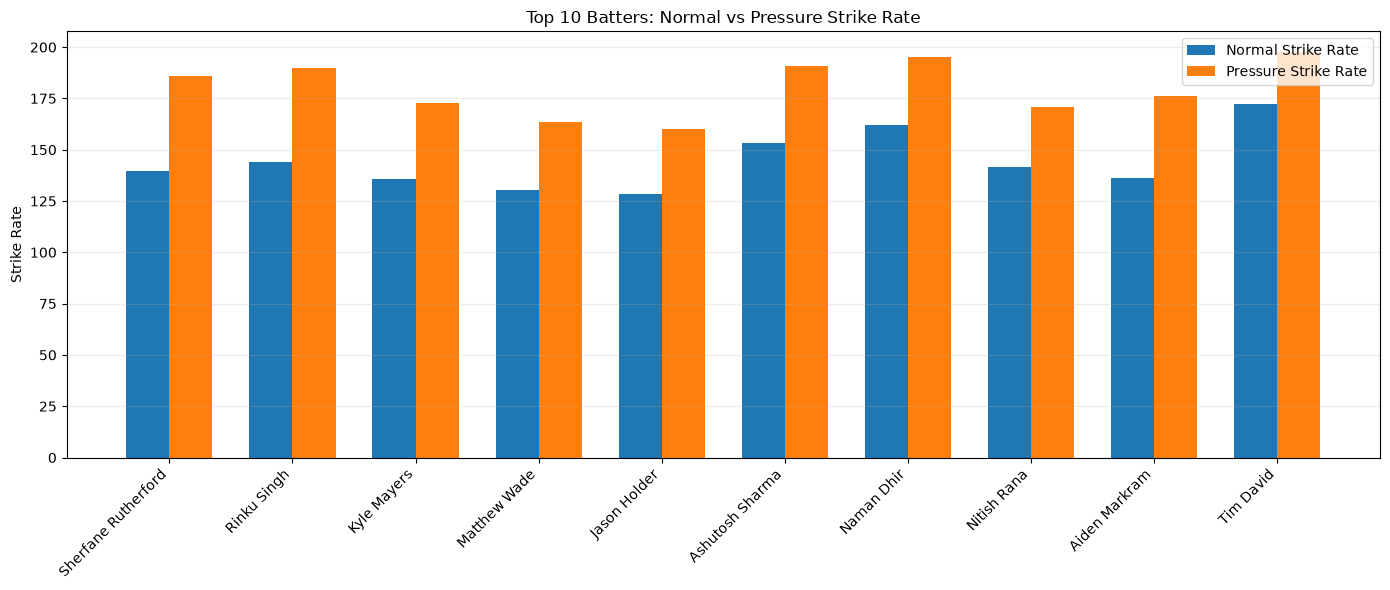

,rank,striker_name,strike_rate_normal,strike_rate_pressure,balls_normal,balls_pressure
0,1,Sherfane Rutherford,139.84,186.05,645.0,172.0
1,2,Rinku Singh,143.99,189.64,1057.0,222.0
2,3,Kyle Mayers,135.67,172.97,628.0,111.0
3,4,Matthew Wade,130.31,163.55,320.0,107.0
4,5,Jason Holder,128.29,160.20,251.0,196.0
5,6,Ashutosh Sharma,153.25,190.58,169.0,138.0
6,7,Naman Dhir,161.94,195.28,402.0,106.0
7,8,Nitish Rana,141.72,170.77,731.0,130.0
8,9,Aiden Markram,136.24,176.19,1377.0,294.0
9,10,Tim David,172.10,197.81,993.0,228.0


In [191]:

# STEP 150: Batter pressure vs normal strike rate

import matplotlib.pyplot as plt
import numpy as np

# Select top 10 batters, retaining unique player IDs
top_batters = (
    final_batter_ranking
    .head(10)
    [["rank", "striker_id", "striker_name"]]
    .copy()
)

# Merge using striker_id to avoid duplicate-name errors
batter_chart_data = top_batters.merge(
    batter_comparison[
        [
            "striker_id",
            "strike_rate_pressure",
            "strike_rate_normal",
            "balls_pressure",
            "balls_normal"
        ]
    ],
    on="striker_id",
    how="left",
    validate="one_to_one"
).sort_values("rank")

# Check that every selected player has comparison data
assert batter_chart_data["strike_rate_pressure"].notna().all()
assert batter_chart_data["strike_rate_normal"].notna().all()

# Plot
x = np.arange(len(batter_chart_data))
width = 0.35

plt.figure(figsize=(14, 6))

plt.bar(
    x - width/2,
    batter_chart_data["strike_rate_normal"],
    width,
    label="Normal Strike Rate"
)

plt.bar(
    x + width/2,
    batter_chart_data["strike_rate_pressure"],
    width,
    label="Pressure Strike Rate"
)

plt.xticks(
    x,
    batter_chart_data["striker_name"],
    rotation=45,
    ha="right"
)

plt.ylabel("Strike Rate")
plt.title("Top 10 Batters: Normal vs Pressure Strike Rate")
plt.legend()
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# Display exact comparison values
display(
    batter_chart_data[
        [
            "rank",
            "striker_name",
            "strike_rate_normal",
            "strike_rate_pressure",
            "balls_normal",
            "balls_pressure"
        ]
    ].round(2)
)


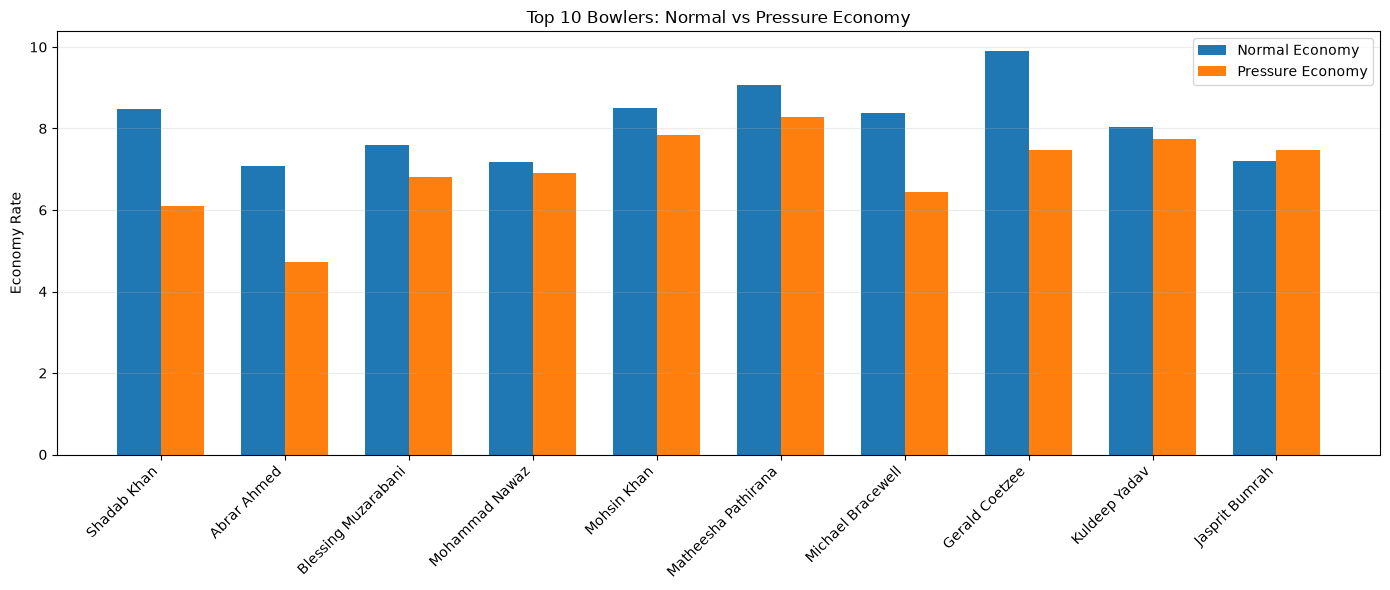

,rank,bowler_name,economy_normal,economy_pressure,legal_balls_normal,legal_balls_pressure
0,1,Shadab Khan,8.49,6.09,615.0,199.0
1,2,Abrar Ahmed,7.07,4.71,638.0,126.0
2,3,Blessing Muzarabani,7.60,6.81,707.0,111.0
3,4,Mohammad Nawaz,7.18,6.90,811.0,193.0
4,5,Mohsin Khan,8.51,7.84,555.0,98.0
5,6,Matheesha Pathirana,9.07,8.28,808.0,297.0
6,7,Michael Bracewell,8.37,6.44,537.0,123.0
7,8,Gerald Coetzee,9.89,7.48,526.0,65.0
8,9,Kuldeep Yadav,8.03,7.74,1558.0,344.0
9,10,Jasprit Bumrah,7.20,7.47,1402.0,306.0


In [192]:

# STEP 151: Bowler pressure vs normal economy

import matplotlib.pyplot as plt
import numpy as np

# Select top 10 bowlers
top_bowlers = (
    final_bowler_top10[
        ["rank", "bowler_name"]
    ].copy()
)

# Match by unique bowler ID
top_bowler_ids = bowler_ranking.head(10)[
    ["rank", "bowler_id", "bowler_name"]
].copy()

bowler_chart_data = top_bowler_ids.merge(
    eligible_bowlers[
        [
            "bowler_id",
            "economy_pressure",
            "economy_normal",
            "legal_balls_pressure",
            "legal_balls_normal"
        ]
    ],
    on="bowler_id",
    how="left",
    validate="one_to_one"
).sort_values("rank")

assert bowler_chart_data["economy_pressure"].notna().all()
assert bowler_chart_data["economy_normal"].notna().all()

# Plot economy comparison
x = np.arange(len(bowler_chart_data))
width = 0.35

plt.figure(figsize=(14, 6))

plt.bar(
    x - width/2,
    bowler_chart_data["economy_normal"],
    width,
    label="Normal Economy"
)

plt.bar(
    x + width/2,
    bowler_chart_data["economy_pressure"],
    width,
    label="Pressure Economy"
)

plt.xticks(
    x,
    bowler_chart_data["bowler_name"],
    rotation=45,
    ha="right"
)

plt.ylabel("Economy Rate")
plt.title("Top 10 Bowlers: Normal vs Pressure Economy")
plt.legend()
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# Display supporting data
display(
    bowler_chart_data[
        [
            "rank",
            "bowler_name",
            "economy_normal",
            "economy_pressure",
            "legal_balls_normal",
            "legal_balls_pressure"
        ]
    ].round(2)
)


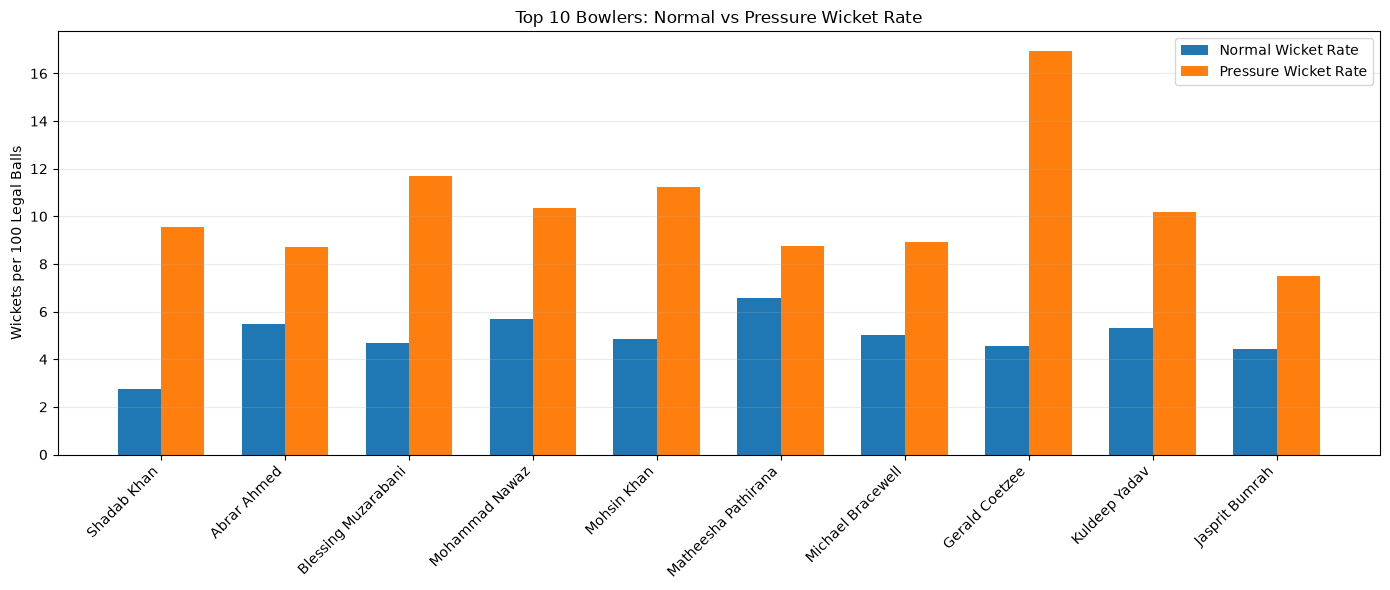

,rank,bowler_name,wicket_rate_normal,wicket_rate_pressure,legal_balls_normal,legal_balls_pressure
0,1,Shadab Khan,2.76,9.55,615.0,199.0
1,2,Abrar Ahmed,5.49,8.73,638.0,126.0
2,3,Blessing Muzarabani,4.67,11.71,707.0,111.0
3,4,Mohammad Nawaz,5.67,10.36,811.0,193.0
4,5,Mohsin Khan,4.86,11.22,555.0,98.0
5,6,Matheesha Pathirana,6.56,8.75,808.0,297.0
6,7,Michael Bracewell,5.03,8.94,537.0,123.0
7,8,Gerald Coetzee,4.56,16.92,526.0,65.0
8,9,Kuldeep Yadav,5.33,10.17,1558.0,344.0
9,10,Jasprit Bumrah,4.42,7.52,1402.0,306.0


In [193]:

# STEP 152: Bowler pressure vs normal wicket rate

import matplotlib.pyplot as plt
import numpy as np

# Prepare top 10 bowlers
top_bowler_ids = (
    bowler_ranking
    .head(10)
    [["rank", "bowler_id", "bowler_name"]]
    .copy()
)

# Merge wicket-rate metrics
wicket_chart_data = top_bowler_ids.merge(
    eligible_bowlers[
        [
            "bowler_id",
            "wicket_rate_pressure",
            "wicket_rate_normal",
            "legal_balls_pressure",
            "legal_balls_normal"
        ]
    ],
    on="bowler_id",
    how="left",
    validate="one_to_one"
).sort_values("rank")

# Validate data
assert wicket_chart_data["wicket_rate_pressure"].notna().all()
assert wicket_chart_data["wicket_rate_normal"].notna().all()

# Plot
x = np.arange(len(wicket_chart_data))
width = 0.35

plt.figure(figsize=(14, 6))

plt.bar(
    x - width/2,
    wicket_chart_data["wicket_rate_normal"],
    width,
    label="Normal Wicket Rate"
)

plt.bar(
    x + width/2,
    wicket_chart_data["wicket_rate_pressure"],
    width,
    label="Pressure Wicket Rate"
)

plt.xticks(
    x,
    wicket_chart_data["bowler_name"],
    rotation=45,
    ha="right"
)

plt.ylabel("Wickets per 100 Legal Balls")
plt.title("Top 10 Bowlers: Normal vs Pressure Wicket Rate")
plt.legend()
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

display(
    wicket_chart_data[
        [
            "rank",
            "bowler_name",
            "wicket_rate_normal",
            "wicket_rate_pressure",
            "legal_balls_normal",
            "legal_balls_pressure"
        ]
    ].round(2)
)


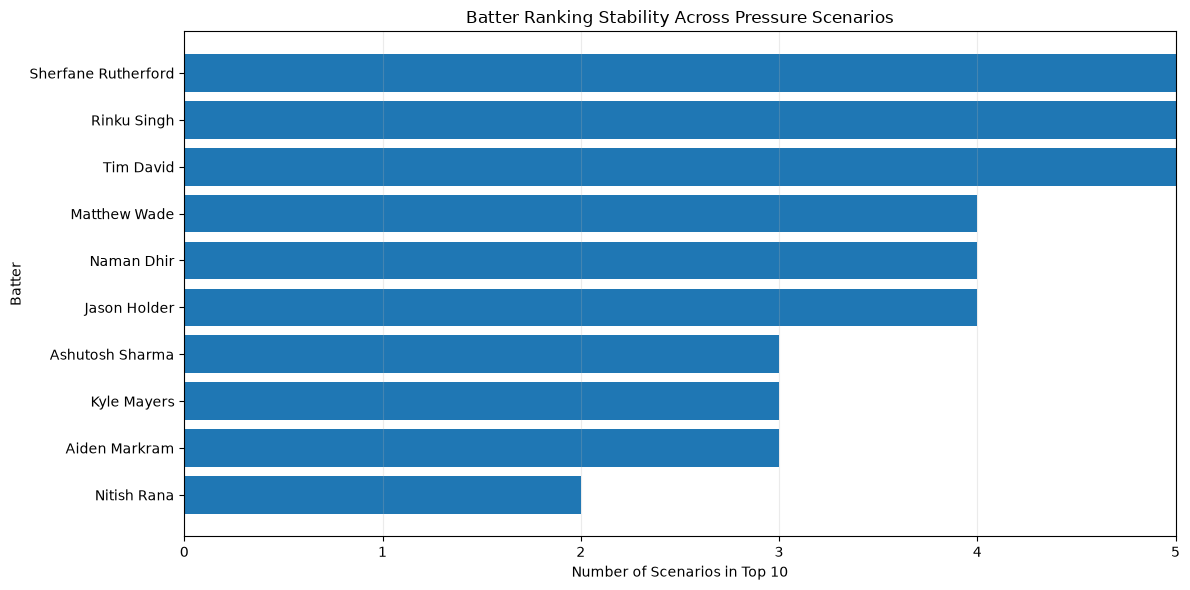

,striker_id,striker_name,top10_appearances,average_rank,best_rank,worst_rank
15,6725,Sherfane Rutherford,5,3.40,1,7
11,4708,Rinku Singh,5,3.60,2,5
13,6396,Tim David,5,7.40,4,10
2,796,Matthew Wade,4,3.75,1,8
19,37052,Naman Dhir,4,4.75,3,7
6,2633,Jason Holder,4,5.25,1,9
16,8101,Ashutosh Sharma,3,3.00,1,6
4,2416,Kyle Mayers,3,5.67,3,7
8,3605,Aiden Markram,3,7.67,5,9
9,4246,Nitish Rana,2,5.00,2,8


In [195]:

# STEP 153: Batter ranking stability visualization

import matplotlib.pyplot as plt

# Use the stability results already calculated in Step 128
batter_stability_chart = batter_stability.copy()

batter_stability_chart = batter_stability_chart.sort_values(
    ["top10_appearances", "average_rank"],
    ascending=[False, True]
).head(10)

plt.figure(figsize=(12, 6))

plt.barh(
    batter_stability_chart["striker_name"],
    batter_stability_chart["top10_appearances"]
)

plt.xlabel("Number of Scenarios in Top 10")
plt.ylabel("Batter")
plt.title("Batter Ranking Stability Across Pressure Scenarios")
plt.xlim(0, 5)
plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

display(batter_stability_chart.round(2))


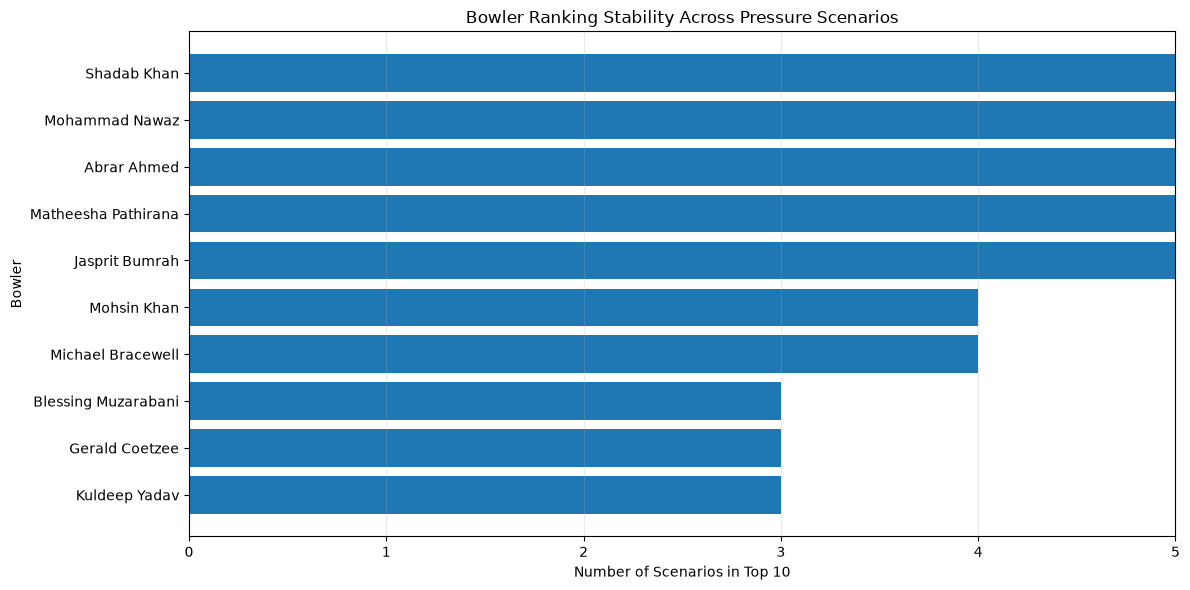

,bowler_id,bowler_name,top10_appearances,average_rank,best_rank,worst_rank
7,4926,Shadab Khan,5,1.60,1,3
1,2490,Mohammad Nawaz,5,3.20,1,6
8,5979,Abrar Ahmed,5,4.40,2,9
17,8661,Matheesha Pathirana,5,7.00,5,10
3,2933,Jasprit Bumrah,5,8.00,6,10
14,6669,Mohsin Khan,4,3.75,2,5
11,6512,Michael Bracewell,4,5.00,3,7
12,6523,Blessing Muzarabani,3,2.33,2,3
13,6628,Gerald Coetzee,3,7.33,6,8
4,3644,Kuldeep Yadav,3,9.67,9,10


In [196]:

# STEP 154: Bowler ranking stability visualization

bowler_stability_chart = bowler_stability.copy()

bowler_stability_chart = bowler_stability_chart.sort_values(
    ["top10_appearances", "average_rank"],
    ascending=[False, True]
).head(10)

plt.figure(figsize=(12, 6))

plt.barh(
    bowler_stability_chart["bowler_name"],
    bowler_stability_chart["top10_appearances"]
)

plt.xlabel("Number of Scenarios in Top 10")
plt.ylabel("Bowler")
plt.title("Bowler Ranking Stability Across Pressure Scenarios")
plt.xlim(0, 5)
plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

display(bowler_stability_chart.round(2))


In [197]:

# STEP 155: Final methodology audit

methodology_audit = pd.DataFrame([
    {
        "Area": "Dataset",
        "Method": "Historical IPL and T20I ball-by-ball data from 2022 onwards",
        "Limitation": "Findings depend on the supplied dataset and its coverage"
    },
    {
        "Area": "First innings pressure",
        "Method": "Expected-score model; pressure when standardized scoring deficit >= 1",
        "Limitation": "Pressure depends on the model's expected-score estimate"
    },
    {
        "Area": "Chase pressure",
        "Method": "Logistic regression; pressure when predicted win probability <= 20%",
        "Limitation": "Win-probability calibration is imperfect"
    },
    {
        "Area": "Batting rating",
        "Method": "Format-adjusted pressure strike rate, improvement, dot avoidance and boundaries",
        "Limitation": "Composite weights are analyst-selected"
    },
    {
        "Area": "Bowling rating",
        "Method": "Economy, wicket rate, dot balls and batter-boundary control",
        "Limitation": "Some uncertain extras are excluded"
    },
    {
        "Area": "Sample size",
        "Method": "Minimum pressure and normal sample requirements",
        "Limitation": "Some players have substantially more observations than others"
    },
    {
        "Area": "IPL and T20I",
        "Method": "Format-specific baselines and pressure strike-rate adjustment",
        "Limitation": "Not every composite component is fully format-normalized"
    },
    {
        "Area": "Robustness",
        "Method": "Pressure threshold, shrinkage and weight sensitivity checks",
        "Limitation": "Sensitivity does not eliminate uncertainty from the dataset"
    },
    {
        "Area": "Bowling extras",
        "Method": "Provisional runs-conceded calculation",
        "Limitation": "Undocumented extras fields may affect economy estimates"
    }
])

display(methodology_audit)

methodology_audit.to_csv(
    "Round1_Methodology_Audit.csv",
    index=False
)

print("Methodology audit exported successfully.")


,Area,Method,Limitation
0,Dataset,Historical IPL and T20I ball-by-ball data from...,Findings depend on the supplied dataset and it...
1,First innings pressure,Expected-score model; pressure when standardiz...,Pressure depends on the model's expected-score...
2,Chase pressure,Logistic regression; pressure when predicted w...,Win-probability calibration is imperfect
3,Batting rating,"Format-adjusted pressure strike rate, improvem...",Composite weights are analyst-selected
4,Bowling rating,"Economy, wicket rate, dot balls and batter-bou...",Some uncertain extras are excluded
5,Sample size,Minimum pressure and normal sample requirements,Some players have substantially more observati...
6,IPL and T20I,Format-specific baselines and pressure strike-...,Not every composite component is fully format-...
7,Robustness,"Pressure threshold, shrinkage and weight sensi...",Sensitivity does not eliminate uncertainty fro...
8,Bowling extras,Provisional runs-conceded calculation,Undocumented extras fields may affect economy ...


Methodology audit exported successfully.


In [198]:

# STEP 156: Consolidate model performance metrics

model_summary = pd.DataFrame([
    {
        "Model": "First innings expected-score model",
        "Method": "Random Forest Regressor",
        "Evaluation": "5-fold GroupKFold by match_id",
        "Metric": "MAE",
        "Value": 12.923
    },
    {
        "Model": "First innings expected-score model",
        "Method": "Random Forest Regressor",
        "Evaluation": "5-fold GroupKFold by match_id",
        "Metric": "RMSE",
        "Value": 18.093
    },
    {
        "Model": "First innings expected-score model",
        "Method": "Random Forest Regressor",
        "Evaluation": "5-fold GroupKFold by match_id",
        "Metric": "R-squared",
        "Value": 0.893
    },
    {
        "Model": "Chase win-probability model",
        "Method": "Logistic Regression",
        "Evaluation": "5-fold GroupKFold by match_id",
        "Metric": "ROC-AUC",
        "Value": 0.893
    },
    {
        "Model": "Chase win-probability model",
        "Method": "Logistic Regression",
        "Evaluation": "5-fold GroupKFold by match_id",
        "Metric": "Accuracy",
        "Value": 0.809
    },
    {
        "Model": "Chase win-probability model",
        "Method": "Logistic Regression",
        "Evaluation": "5-fold GroupKFold by match_id",
        "Metric": "Brier Score",
        "Value": 0.135
    },
    {
        "Model": "Chase win-probability model",
        "Method": "Logistic Regression",
        "Evaluation": "5-fold GroupKFold by match_id",
        "Metric": "Log Loss",
        "Value": 0.418
    }
])

display(model_summary)

model_summary.to_csv(
    "Round1_Model_Performance.csv",
    index=False
)

print("Model performance summary exported successfully.")


,Model,Method,Evaluation,Metric,Value
0,First innings expected-score model,Random Forest Regressor,5-fold GroupKFold by match_id,MAE,12.923
1,First innings expected-score model,Random Forest Regressor,5-fold GroupKFold by match_id,RMSE,18.093
2,First innings expected-score model,Random Forest Regressor,5-fold GroupKFold by match_id,R-squared,0.893
3,Chase win-probability model,Logistic Regression,5-fold GroupKFold by match_id,ROC-AUC,0.893
4,Chase win-probability model,Logistic Regression,5-fold GroupKFold by match_id,Accuracy,0.809
5,Chase win-probability model,Logistic Regression,5-fold GroupKFold by match_id,Brier Score,0.135
6,Chase win-probability model,Logistic Regression,5-fold GroupKFold by match_id,Log Loss,0.418


Model performance summary exported successfully.


In [199]:

# STEP 157: Export all charts for methodology report

import os
import matplotlib.pyplot as plt
import numpy as np

os.makedirs("Round1_Report_Charts", exist_ok=True)

# 1. Batter strike-rate comparison
fig, ax = plt.subplots(figsize=(14, 6))
x = np.arange(len(batter_chart_data))
w = 0.35

ax.bar(x - w/2, batter_chart_data["strike_rate_normal"],
       w, label="Normal Strike Rate")
ax.bar(x + w/2, batter_chart_data["strike_rate_pressure"],
       w, label="Pressure Strike Rate")

ax.set_xticks(x)
ax.set_xticklabels(batter_chart_data["striker_name"],
                   rotation=45, ha="right")
ax.set_ylabel("Strike Rate")
ax.set_title("Top 10 Batters: Normal vs Pressure Strike Rate")
ax.legend()
fig.tight_layout()
fig.savefig("Round1_Report_Charts/01_batter_strike_rate.png",
            dpi=300, bbox_inches="tight")
plt.close(fig)

# 2. Bowler economy comparison
fig, ax = plt.subplots(figsize=(14, 6))
x = np.arange(len(bowler_chart_data))

ax.bar(x - w/2, bowler_chart_data["economy_normal"],
       w, label="Normal Economy")
ax.bar(x + w/2, bowler_chart_data["economy_pressure"],
       w, label="Pressure Economy")

ax.set_xticks(x)
ax.set_xticklabels(bowler_chart_data["bowler_name"],
                   rotation=45, ha="right")
ax.set_ylabel("Economy Rate")
ax.set_title("Top 10 Bowlers: Normal vs Pressure Economy")
ax.legend()
fig.tight_layout()
fig.savefig("Round1_Report_Charts/02_bowler_economy.png",
            dpi=300, bbox_inches="tight")
plt.close(fig)

# 3. Bowler wicket-rate comparison
fig, ax = plt.subplots(figsize=(14, 6))
x = np.arange(len(wicket_chart_data))

ax.bar(x - w/2, wicket_chart_data["wicket_rate_normal"],
       w, label="Normal Wicket Rate")
ax.bar(x + w/2, wicket_chart_data["wicket_rate_pressure"],
       w, label="Pressure Wicket Rate")

ax.set_xticks(x)
ax.set_xticklabels(wicket_chart_data["bowler_name"],
                   rotation=45, ha="right")
ax.set_ylabel("Wickets per 100 Legal Balls")
ax.set_title("Top 10 Bowlers: Normal vs Pressure Wicket Rate")
ax.legend()
fig.tight_layout()
fig.savefig("Round1_Report_Charts/03_bowler_wicket_rate.png",
            dpi=300, bbox_inches="tight")
plt.close(fig)

# 4. Batter ranking stability
fig, ax = plt.subplots(figsize=(12, 6))
ax.barh(batter_stability_chart["striker_name"],
        batter_stability_chart["top10_appearances"])
ax.set_xlabel("Number of Scenarios in Top 10")
ax.set_title("Batter Ranking Stability Across Pressure Scenarios")
ax.set_xlim(0, 5)
ax.invert_yaxis()
fig.tight_layout()
fig.savefig("Round1_Report_Charts/04_batter_stability.png",
            dpi=300, bbox_inches="tight")
plt.close(fig)

# 5. Bowler ranking stability
fig, ax = plt.subplots(figsize=(12, 6))
ax.barh(bowler_stability_chart["bowler_name"],
        bowler_stability_chart["top10_appearances"])
ax.set_xlabel("Number of Scenarios in Top 10")
ax.set_title("Bowler Ranking Stability Across Pressure Scenarios")
ax.set_xlim(0, 5)
ax.invert_yaxis()
fig.tight_layout()
fig.savefig("Round1_Report_Charts/05_bowler_stability.png",
            dpi=300, bbox_inches="tight")
plt.close(fig)

print("All five report charts exported successfully.")
print(os.listdir("Round1_Report_Charts"))


All five report charts exported successfully.
['01_batter_strike_rate.png', '03_bowler_wicket_rate.png', '05_bowler_stability.png', '04_batter_stability.png', '02_bowler_economy.png']


In [201]:

# STEP 158: Expand player rankings for auction feasibility analysis

print("TOP 15 BATTERS - ORIGINAL ANALYTICAL RANKING")

display(
    final_batter_ranking
    .head(15)
    .round(2)
)

print("\nTOP 20 BOWLERS - ORIGINAL ANALYTICAL RANKING")

display(
    bowler_ranking
    .head(20)
    .round(2)
)

print("\nBOWLING RANKING COLUMNS:")
print(bowler_ranking.columns.tolist())

print("\nBATTING RANKING COLUMNS:")
print(final_batter_ranking.columns.tolist())


TOP 15 BATTERS - ORIGINAL ANALYTICAL RANKING


,striker_id,striker_name,runs_normal,runs_pressure,balls_normal,balls_pressure,strike_rate_normal,strike_rate_pressure,dot_ball_pct_normal,dot_ball_pct_pressure,...,sr_score,improvement_score,dot_avoidance_score,boundary_score,format_adjusted_score,format_pressure_balls,formats_played,format_sr_score,final_batter_score,rank
0,6725,Sherfane Rutherford,902.0,320.0,645.0,172.0,139.84,186.05,39.22,34.30,...,94.90,100.00,80.61,95.92,110.34,172.0,2.0,96.94,94.29,1
1,4708,Rinku Singh,1522.0,421.0,1057.0,222.0,143.99,189.64,31.60,29.73,...,98.98,98.98,62.24,98.98,114.82,222.0,2.0,100.00,92.04,2
2,2416,Kyle Mayers,852.0,192.0,628.0,111.0,135.67,172.97,49.20,40.54,...,87.76,95.92,92.86,88.78,104.77,111.0,2.0,85.71,90.15,3
3,796,Matthew Wade,417.0,175.0,320.0,107.0,130.31,163.55,38.44,28.04,...,78.57,92.86,96.94,74.49,106.45,107.0,2.0,90.82,90.10,4
4,2633,Jason Holder,322.0,314.0,251.0,196.0,128.29,160.20,43.43,31.63,...,75.51,91.84,98.98,71.43,106.44,196.0,2.0,89.80,89.39,5
5,8101,Ashutosh Sharma,259.0,263.0,169.0,138.0,153.25,190.58,32.54,31.16,...,96.94,96.94,58.16,94.90,112.11,138.0,1.0,97.96,89.29,6
6,37052,Naman Dhir,651.0,207.0,402.0,106.0,161.94,195.28,30.85,26.42,...,95.92,93.88,75.51,87.76,109.73,106.0,2.0,93.88,89.29,7
7,4246,Nitish Rana,1036.0,222.0,731.0,130.0,141.72,170.77,39.53,33.08,...,86.73,87.76,87.76,92.86,104.70,130.0,1.0,84.69,87.30,8
8,3605,Aiden Markram,1876.0,518.0,1377.0,294.0,136.24,176.19,31.08,30.95,...,93.88,97.96,47.96,97.96,109.83,294.0,2.0,95.92,87.14,9
9,6396,Tim David,1709.0,451.0,993.0,228.0,172.10,197.81,31.62,28.07,...,100.00,83.67,68.37,83.67,114.49,228.0,2.0,98.98,86.73,10



TOP 20 BOWLERS - ORIGINAL ANALYTICAL RANKING


,bowler_id,bowler_name,pressure_balls,formats_played,economy_score,wicket_score,dot_score,boundary_score,economy_component,wicket_component,dot_component,boundary_component,bowler_score,rank
0,4926,Shadab Khan,199.0,1.0,120.75,120.22,110.92,138.22,98.52,88.15,93.33,99.26,93.96,1
1,5979,Abrar Ahmed,126.0,1.0,131.13,110.71,122.56,133.10,99.26,77.78,100.00,97.78,91.67,2
2,6523,Blessing Muzarabani,111.0,1.0,109.85,131.52,110.31,106.09,91.85,97.78,91.11,68.89,90.33,3
3,2490,Mohammad Nawaz,193.0,1.0,111.73,127.34,102.53,131.90,94.81,94.81,63.70,97.04,88.93,4
4,6669,Mohsin Khan,98.0,1.0,107.74,139.00,106.77,109.86,85.93,99.26,84.44,76.30,88.85,5
5,8661,Matheesha Pathirana,297.0,2.0,105.76,120.62,105.08,121.70,80.74,89.63,78.52,93.33,85.30,6
6,6512,Michael Bracewell,123.0,2.0,110.59,109.44,109.31,114.73,94.07,74.07,88.89,83.70,84.48,7
7,6628,Gerald Coetzee,65.0,2.0,103.90,136.55,106.56,105.10,76.30,98.52,83.70,65.93,84.00,8
8,3644,Kuldeep Yadav,344.0,2.0,108.34,128.56,98.83,118.63,88.89,96.30,42.96,88.89,82.30,9
9,2933,Jasprit Bumrah,306.0,2.0,110.11,107.64,110.58,108.19,92.59,68.89,92.59,74.81,81.63,10



BOWLING RANKING COLUMNS:
['bowler_id', 'bowler_name', 'pressure_balls', 'formats_played', 'economy_score', 'wicket_score', 'dot_score', 'boundary_score', 'economy_component', 'wicket_component', 'dot_component', 'boundary_component', 'bowler_score', 'rank']

BATTING RANKING COLUMNS:
['striker_id', 'striker_name', 'runs_normal', 'runs_pressure', 'balls_normal', 'balls_pressure', 'strike_rate_normal', 'strike_rate_pressure', 'dot_ball_pct_normal', 'dot_ball_pct_pressure', 'boundary_pct_normal', 'boundary_pct_pressure', 'dismissals_normal', 'dismissals_pressure', 'matches_normal', 'matches_pressure', 'strike_rate_difference', 'dot_ball_difference', 'boundary_difference', 'adjusted_sr_k50', 'adjusted_sr_k100', 'adjusted_sr_k150', 'valid_pressure_matches', 'average_match_runs', 'median_match_runs', 'average_match_sr', 'median_match_sr', 'sr_volatility', 'average_match_dot_pct', 'match_coverage', 'sr_score', 'improvement_score', 'dot_avoidance_score', 'boundary_score', 'format_adjusted_scor

In [202]:

# STEP 159: Create nationality-screened auction candidate rankings

# Pakistan-national players identified for historical-only treatment
pakistan_players = {
    "Shadab Khan",
    "Abrar Ahmed",
    "Mohammad Nawaz",
    "Shaheen Afridi"
}

# Keep original batter ranking unchanged
rr_batter_candidates = (
    final_batter_ranking
    .head(10)
    [[
        "rank",
        "striker_id",
        "striker_name",
        "final_batter_score",
        "format_pressure_balls",
        "formats_played"
    ]]
    .copy()
)

# Filter Pakistan-national players from actionable bowler pool
rr_bowler_candidates = (
    bowler_ranking[
        ~bowler_ranking["bowler_name"].isin(pakistan_players)
    ]
    .head(10)
    [[
        "rank",
        "bowler_id",
        "bowler_name",
        "bowler_score",
        "pressure_balls",
        "formats_played"
    ]]
    .copy()
)

# Add new shortlist positions while preserving original analytical ranks
rr_batter_candidates.insert(
    0, "shortlist_rank", range(1, len(rr_batter_candidates) + 1)
)

rr_bowler_candidates.insert(
    0, "shortlist_rank", range(1, len(rr_bowler_candidates) + 1)
)

print("RR BATTER CANDIDATES")
display(rr_batter_candidates.round(2))

print("\nRR BOWLER CANDIDATES")
display(rr_bowler_candidates.round(2))

# Explicitly mark that availability is not yet verified
rr_batter_candidates["auction_availability"] = "Unverified"
rr_bowler_candidates["auction_availability"] = "Unverified"

rr_batter_candidates.to_csv(
    "RR_Batter_Candidate_Ranking.csv", index=False
)

rr_bowler_candidates.to_csv(
    "RR_Bowler_Candidate_Ranking.csv", index=False
)

print("\nNationality-screened candidate files exported.")
print("Note: These are not confirmed auction-available players.")


RR BATTER CANDIDATES


,shortlist_rank,rank,striker_id,striker_name,final_batter_score,format_pressure_balls,formats_played
0,1,1,6725,Sherfane Rutherford,94.29,172.0,2.0
1,2,2,4708,Rinku Singh,92.04,222.0,2.0
2,3,3,2416,Kyle Mayers,90.15,111.0,2.0
3,4,4,796,Matthew Wade,90.10,107.0,2.0
4,5,5,2633,Jason Holder,89.39,196.0,2.0
5,6,6,8101,Ashutosh Sharma,89.29,138.0,1.0
6,7,7,37052,Naman Dhir,89.29,106.0,2.0
7,8,8,4246,Nitish Rana,87.30,130.0,1.0
8,9,9,3605,Aiden Markram,87.14,294.0,2.0
9,10,10,6396,Tim David,86.73,228.0,2.0



RR BOWLER CANDIDATES


,shortlist_rank,rank,bowler_id,bowler_name,bowler_score,pressure_balls,formats_played
2,1,3,6523,Blessing Muzarabani,90.33,111.0,1.0
4,2,5,6669,Mohsin Khan,88.85,98.0,1.0
5,3,6,8661,Matheesha Pathirana,85.30,297.0,2.0
6,4,7,6512,Michael Bracewell,84.48,123.0,2.0
7,5,8,6628,Gerald Coetzee,84.00,65.0,2.0
8,6,9,3644,Kuldeep Yadav,82.30,344.0,2.0
9,7,10,2933,Jasprit Bumrah,81.63,306.0,2.0
11,8,12,830,Josh Hazlewood,78.74,333.0,2.0
12,9,13,4489,Prasidh Krishna,78.41,200.0,2.0
13,10,14,6256,Varun Chakravarthy,78.33,506.0,2.0



Nationality-screened candidate files exported.
Note: These are not confirmed auction-available players.


In [203]:

# STEP 160: Prepare RR squad-fit verification sheet

# Combine batter and bowler candidate lists
rr_batters = rr_batter_candidates.copy()
rr_batters["analysis_category"] = "Batter"
rr_batters["player_name"] = rr_batters["striker_name"]
rr_batters["original_score"] = rr_batters["final_batter_score"]
rr_batters["original_rank"] = rr_batters["rank"]

rr_bowlers = rr_bowler_candidates.copy()
rr_bowlers["analysis_category"] = "Bowler"
rr_bowlers["player_name"] = rr_bowlers["bowler_name"]
rr_bowlers["original_score"] = rr_bowlers["bowler_score"]
rr_bowlers["original_rank"] = rr_bowlers["rank"]

# Common player list
rr_squad_fit = pd.concat(
    [
        rr_batters[[
            "analysis_category",
            "player_name",
            "original_rank",
            "original_score"
        ]],
        rr_bowlers[[
            "analysis_category",
            "player_name",
            "original_rank",
            "original_score"
        ]]
    ],
    ignore_index=True
)

# Research verification fields
rr_squad_fit["2026_franchise"] = "Pending verification"
rr_squad_fit["2027_retention_status"] = "Pending official announcement"
rr_squad_fit["auction_registration"] = "Unverified"
rr_squad_fit["nationality"] = "Pending verification"
rr_squad_fit["playing_role"] = "Pending verification"
rr_squad_fit["rr_squad_gap"] = "Pending analysis"
rr_squad_fit["auction_availability"] = "Unverified"
rr_squad_fit["recommendation"] = "Pending analysis"
rr_squad_fit["source"] = "Pending"

display(rr_squad_fit)

rr_squad_fit.to_csv(
    "RR_2027_Squad_Fit_Verification.csv",
    index=False
)

print("RR squad-fit verification sheet exported.")


,analysis_category,player_name,original_rank,original_score,2026_franchise,2027_retention_status,auction_registration,nationality,playing_role,rr_squad_gap,auction_availability,recommendation,source
0,Batter,Sherfane Rutherford,1,94.285714,Pending verification,Pending official announcement,Unverified,Pending verification,Pending verification,Pending analysis,Unverified,Pending analysis,Pending
1,Batter,Rinku Singh,2,92.040816,Pending verification,Pending official announcement,Unverified,Pending verification,Pending verification,Pending analysis,Unverified,Pending analysis,Pending
2,Batter,Kyle Mayers,3,90.153061,Pending verification,Pending official announcement,Unverified,Pending verification,Pending verification,Pending analysis,Unverified,Pending analysis,Pending
3,Batter,Matthew Wade,4,90.102041,Pending verification,Pending official announcement,Unverified,Pending verification,Pending verification,Pending analysis,Unverified,Pending analysis,Pending
4,Batter,Jason Holder,5,89.387755,Pending verification,Pending official announcement,Unverified,Pending verification,Pending verification,Pending analysis,Unverified,Pending analysis,Pending
5,Batter,Ashutosh Sharma,6,89.285714,Pending verification,Pending official announcement,Unverified,Pending verification,Pending verification,Pending analysis,Unverified,Pending analysis,Pending
6,Batter,Naman Dhir,7,89.285714,Pending verification,Pending official announcement,Unverified,Pending verification,Pending verification,Pending analysis,Unverified,Pending analysis,Pending
7,Batter,Nitish Rana,8,87.295918,Pending verification,Pending official announcement,Unverified,Pending verification,Pending verification,Pending analysis,Unverified,Pending analysis,Pending
8,Batter,Aiden Markram,9,87.142857,Pending verification,Pending official announcement,Unverified,Pending verification,Pending verification,Pending analysis,Unverified,Pending analysis,Pending
9,Batter,Tim David,10,86.734694,Pending verification,Pending official announcement,Unverified,Pending verification,Pending verification,Pending analysis,Unverified,Pending analysis,Pending


RR squad-fit verification sheet exported.


In [204]:
# STEP 161: Prepare final player verification tracker

rr_squad_fit["verification_status"] = "Research required"
rr_squad_fit["source_date"] = ""
rr_squad_fit["source_url"] = ""
rr_squad_fit["confidence"] = "Not assessed"

rr_squad_fit["rr_fit_reason"] = ""
rr_squad_fit["auction_priority"] = ""

# Keep original rankings separate from squad-fit decisions
rr_squad_fit = rr_squad_fit.sort_values(
    ["analysis_category", "original_rank"]
).reset_index(drop=True)

display(rr_squad_fit)

rr_squad_fit.to_csv(
    "RR_2027_Player_Verification_Tracker.csv",
    index=False
)

print("Step 161 completed: Player verification tracker exported.")

,analysis_category,player_name,original_rank,original_score,2026_franchise,2027_retention_status,auction_registration,nationality,playing_role,rr_squad_gap,auction_availability,recommendation,source,verification_status,source_date,source_url,confidence,rr_fit_reason,auction_priority
0,Batter,Sherfane Rutherford,1,94.285714,Pending verification,Pending official announcement,Unverified,Pending verification,Pending verification,Pending analysis,Unverified,Pending analysis,Pending,Research required,,,Not assessed,,
1,Batter,Rinku Singh,2,92.040816,Pending verification,Pending official announcement,Unverified,Pending verification,Pending verification,Pending analysis,Unverified,Pending analysis,Pending,Research required,,,Not assessed,,
2,Batter,Kyle Mayers,3,90.153061,Pending verification,Pending official announcement,Unverified,Pending verification,Pending verification,Pending analysis,Unverified,Pending analysis,Pending,Research required,,,Not assessed,,
3,Batter,Matthew Wade,4,90.102041,Pending verification,Pending official announcement,Unverified,Pending verification,Pending verification,Pending analysis,Unverified,Pending analysis,Pending,Research required,,,Not assessed,,
4,Batter,Jason Holder,5,89.387755,Pending verification,Pending official announcement,Unverified,Pending verification,Pending verification,Pending analysis,Unverified,Pending analysis,Pending,Research required,,,Not assessed,,
5,Batter,Ashutosh Sharma,6,89.285714,Pending verification,Pending official announcement,Unverified,Pending verification,Pending verification,Pending analysis,Unverified,Pending analysis,Pending,Research required,,,Not assessed,,
6,Batter,Naman Dhir,7,89.285714,Pending verification,Pending official announcement,Unverified,Pending verification,Pending verification,Pending analysis,Unverified,Pending analysis,Pending,Research required,,,Not assessed,,
7,Batter,Nitish Rana,8,87.295918,Pending verification,Pending official announcement,Unverified,Pending verification,Pending verification,Pending analysis,Unverified,Pending analysis,Pending,Research required,,,Not assessed,,
8,Batter,Aiden Markram,9,87.142857,Pending verification,Pending official announcement,Unverified,Pending verification,Pending verification,Pending analysis,Unverified,Pending analysis,Pending,Research required,,,Not assessed,,
9,Batter,Tim David,10,86.734694,Pending verification,Pending official announcement,Unverified,Pending verification,Pending verification,Pending analysis,Unverified,Pending analysis,Pending,Research required,,,Not assessed,,


Step 161 completed: Player verification tracker exported.


In [205]:
# STEP 162: Record IPL 2027 research cutoff and verification rules

research_cutoff = "2026-11-14"

rr_squad_fit["research_cutoff"] = research_cutoff

rr_squad_fit["2027_status_note"] = (
    "Await official retention/release list and auction register"
)

rr_squad_fit["availability_rule"] = (
    "Available only if released/not retained, "
    "registered and included in final auction list"
)

rr_squad_fit["2026_franchise"] = "Research pending"
rr_squad_fit["2027_retention_status"] = "Not yet verified"
rr_squad_fit["auction_registration"] = "Not yet verified"
rr_squad_fit["auction_availability"] = "Not confirmed"

rr_squad_fit.to_csv(
    "RR_2027_Player_Verification_Tracker.csv",
    index=False
)

display(
    rr_squad_fit[
        [
            "analysis_category",
            "player_name",
            "original_rank",
            "original_score",
            "2026_franchise",
            "2027_retention_status",
            "auction_availability",
            "research_cutoff"
        ]
    ]
)

print("Step 162 completed.")

,analysis_category,player_name,original_rank,original_score,2026_franchise,2027_retention_status,auction_availability,research_cutoff
0,Batter,Sherfane Rutherford,1,94.285714,Research pending,Not yet verified,Not confirmed,2026-11-14
1,Batter,Rinku Singh,2,92.040816,Research pending,Not yet verified,Not confirmed,2026-11-14
2,Batter,Kyle Mayers,3,90.153061,Research pending,Not yet verified,Not confirmed,2026-11-14
3,Batter,Matthew Wade,4,90.102041,Research pending,Not yet verified,Not confirmed,2026-11-14
4,Batter,Jason Holder,5,89.387755,Research pending,Not yet verified,Not confirmed,2026-11-14
5,Batter,Ashutosh Sharma,6,89.285714,Research pending,Not yet verified,Not confirmed,2026-11-14
6,Batter,Naman Dhir,7,89.285714,Research pending,Not yet verified,Not confirmed,2026-11-14
7,Batter,Nitish Rana,8,87.295918,Research pending,Not yet verified,Not confirmed,2026-11-14
8,Batter,Aiden Markram,9,87.142857,Research pending,Not yet verified,Not confirmed,2026-11-14
9,Batter,Tim David,10,86.734694,Research pending,Not yet verified,Not confirmed,2026-11-14


Step 162 completed.


In [206]:
# STEP 163: Add verified 2026 franchise associations

franchise_2026 = {
    "Sherfane Rutherford": "Mumbai Indians",
    "Naman Dhir": "Mumbai Indians",
    "Jasprit Bumrah": "Mumbai Indians",
    "Rinku Singh": "Kolkata Knight Riders",
    "Blessing Muzarabani": "Kolkata Knight Riders",
    "Matheesha Pathirana": "Kolkata Knight Riders",
    "Varun Chakravarthy": "Kolkata Knight Riders",
    "Aiden Markram": "Lucknow Super Giants",
    "Mohsin Khan": "Lucknow Super Giants",
    "Tim David": "Royal Challengers Bengaluru",
    "Josh Hazlewood": "Royal Challengers Bengaluru",
    "Nitish Rana": "Delhi Capitals",
    "Ashutosh Sharma": "Delhi Capitals",
    "Gerald Coetzee": "Sunrisers Hyderabad"
}

rr_squad_fit["2026_franchise"] = (
    rr_squad_fit["player_name"]
    .map(franchise_2026)
    .fillna("Not verified")
)

rr_squad_fit["franchise_source"] = (
    rr_squad_fit["2026_franchise"]
    .apply(
        lambda x: "Published IPL 2026 squad lists"
        if x != "Not verified"
        else "Research required"
    )
)

display(
    rr_squad_fit[
        [
            "player_name",
            "analysis_category",
            "original_rank",
            "2026_franchise",
            "franchise_source"
        ]
    ]
)

rr_squad_fit.to_csv(
    "RR_2027_Player_Verification_Tracker.csv",
    index=False
)

print("Step 163 completed.")

,player_name,analysis_category,original_rank,2026_franchise,franchise_source
0,Sherfane Rutherford,Batter,1,Mumbai Indians,Published IPL 2026 squad lists
1,Rinku Singh,Batter,2,Kolkata Knight Riders,Published IPL 2026 squad lists
2,Kyle Mayers,Batter,3,Not verified,Research required
3,Matthew Wade,Batter,4,Not verified,Research required
4,Jason Holder,Batter,5,Not verified,Research required
5,Ashutosh Sharma,Batter,6,Delhi Capitals,Published IPL 2026 squad lists
6,Naman Dhir,Batter,7,Mumbai Indians,Published IPL 2026 squad lists
7,Nitish Rana,Batter,8,Delhi Capitals,Published IPL 2026 squad lists
8,Aiden Markram,Batter,9,Lucknow Super Giants,Published IPL 2026 squad lists
9,Tim David,Batter,10,Royal Challengers Bengaluru,Published IPL 2026 squad lists


Step 163 completed.


In [207]:
# STEP 164: Correct and complete 2026 franchise mapping

franchise_2026 = {
    "Sherfane Rutherford": "Mumbai Indians",
    "Rinku Singh": "Kolkata Knight Riders",
    "Kyle Mayers": "Not verified",
    "Matthew Wade": "Not verified",
    "Jason Holder": "Gujarat Titans",
    "Ashutosh Sharma": "Delhi Capitals",
    "Naman Dhir": "Mumbai Indians",
    "Nitish Rana": "Delhi Capitals",
    "Aiden Markram": "Lucknow Super Giants",
    "Tim David": "Royal Challengers Bengaluru",

    "Blessing Muzarabani": "Kolkata Knight Riders",
    "Mohsin Khan": "Lucknow Super Giants",
    "Matheesha Pathirana": "Kolkata Knight Riders",
    "Michael Bracewell": "Not verified",
    "Gerald Coetzee": "Sunrisers Hyderabad",
    "Kuldeep Yadav": "Delhi Capitals",
    "Jasprit Bumrah": "Mumbai Indians",
    "Josh Hazlewood": "Royal Challengers Bengaluru",
    "Prasidh Krishna": "Gujarat Titans",
    "Varun Chakravarthy": "Kolkata Knight Riders"
}

rr_squad_fit["2026_franchise"] = (
    rr_squad_fit["player_name"]
    .map(franchise_2026)
    .fillna("Not verified")
)

rr_squad_fit["franchise_verification"] = (
    rr_squad_fit["2026_franchise"]
    .apply(
        lambda x: "Verified against 2026 squad sources"
        if x != "Not verified"
        else "Requires further verification"
    )
)

display(
    rr_squad_fit[
        [
            "player_name",
            "analysis_category",
            "original_rank",
            "2026_franchise",
            "franchise_verification"
        ]
    ]
)

rr_squad_fit.to_csv(
    "RR_2027_Player_Verification_Tracker.csv",
    index=False
)

print("Step 164 completed.")

,player_name,analysis_category,original_rank,2026_franchise,franchise_verification
0,Sherfane Rutherford,Batter,1,Mumbai Indians,Verified against 2026 squad sources
1,Rinku Singh,Batter,2,Kolkata Knight Riders,Verified against 2026 squad sources
2,Kyle Mayers,Batter,3,Not verified,Requires further verification
3,Matthew Wade,Batter,4,Not verified,Requires further verification
4,Jason Holder,Batter,5,Gujarat Titans,Verified against 2026 squad sources
5,Ashutosh Sharma,Batter,6,Delhi Capitals,Verified against 2026 squad sources
6,Naman Dhir,Batter,7,Mumbai Indians,Verified against 2026 squad sources
7,Nitish Rana,Batter,8,Delhi Capitals,Verified against 2026 squad sources
8,Aiden Markram,Batter,9,Lucknow Super Giants,Verified against 2026 squad sources
9,Tim David,Batter,10,Royal Challengers Bengaluru,Verified against 2026 squad sources


Step 164 completed.


In [208]:
# STEP 165: Add player role classifications

player_roles = {
    "Sherfane Rutherford": "Middle-order batter / Finisher",
    "Rinku Singh": "Middle-order batter / Finisher",
    "Kyle Mayers": "Opening batter / Seam-bowling all-rounder",
    "Matthew Wade": "Wicketkeeper / Top-order batter",
    "Jason Holder": "Fast-bowling all-rounder",
    "Ashutosh Sharma": "Middle-order batter / Finisher",
    "Naman Dhir": "Middle-order batter / All-rounder",
    "Nitish Rana": "Top-order batter",
    "Aiden Markram": "Top-order batter / Off-spin all-rounder",
    "Tim David": "Middle-order batter / Finisher",

    "Blessing Muzarabani": "Fast bowler",
    "Mohsin Khan": "Left-arm fast bowler",
    "Matheesha Pathirana": "Right-arm fast bowler",
    "Michael Bracewell": "Batting all-rounder / Off-spinner",
    "Gerald Coetzee": "Fast bowler",
    "Kuldeep Yadav": "Left-arm wrist spinner",
    "Jasprit Bumrah": "Fast bowler",
    "Josh Hazlewood": "Fast bowler",
    "Prasidh Krishna": "Fast bowler",
    "Varun Chakravarthy": "Mystery spinner"
}

rr_squad_fit["playing_role"] = (
    rr_squad_fit["player_name"]
    .map(player_roles)
    .fillna("Role verification required")
)

display(
    rr_squad_fit[
        [
            "player_name",
            "analysis_category",
            "playing_role",
            "2026_franchise"
        ]
    ]
)

rr_squad_fit.to_csv(
    "RR_2027_Player_Verification_Tracker.csv",
    index=False
)

print("Step 165 completed.")

,player_name,analysis_category,playing_role,2026_franchise
0,Sherfane Rutherford,Batter,Middle-order batter / Finisher,Mumbai Indians
1,Rinku Singh,Batter,Middle-order batter / Finisher,Kolkata Knight Riders
2,Kyle Mayers,Batter,Opening batter / Seam-bowling all-rounder,Not verified
3,Matthew Wade,Batter,Wicketkeeper / Top-order batter,Not verified
4,Jason Holder,Batter,Fast-bowling all-rounder,Gujarat Titans
5,Ashutosh Sharma,Batter,Middle-order batter / Finisher,Delhi Capitals
6,Naman Dhir,Batter,Middle-order batter / All-rounder,Mumbai Indians
7,Nitish Rana,Batter,Top-order batter,Delhi Capitals
8,Aiden Markram,Batter,Top-order batter / Off-spin all-rounder,Lucknow Super Giants
9,Tim David,Batter,Middle-order batter / Finisher,Royal Challengers Bengaluru


Step 165 completed.


In [209]:
# STEP 166: Build RR squad-gap and candidate-fit matrix

rr_role_needs = {
    "Middle-order batter / Finisher":
        "Medium - existing options include Hetmyer, Ferreira and Dubey",
    "Top-order batter":
        "Low - Jaiswal, Sooryavanshi and Parag provide options",
    "Wicketkeeper / Top-order batter":
        "Low - Jurel, Ferreira and Ravi Singh provide options",
    "Opening batter / Seam-bowling all-rounder":
        "Medium - potential overseas batting and bowling flexibility",
    "Fast-bowling all-rounder":
        "Medium - Jadeja and Curran provide all-round options",
    "Middle-order batter / All-rounder":
        "Medium - assess additional batting depth and flexibility",
    "Top-order batter / Off-spin all-rounder":
        "Medium - assess batting depth and spin utility",
    "Fast bowler":
        "Medium - assess pace depth, workload and backup options",
    "Left-arm fast bowler":
        "Medium - assess left-arm pace depth",
    "Right-arm fast bowler":
        "Medium - assess specialist pace and death-over options",
    "Batting all-rounder / Off-spinner":
        "Medium - assess batting depth and spin coverage",
    "Left-arm wrist spinner":
        "Low - Ravi Bishnoi provides a specialist wrist-spin option",
    "Mystery spinner":
        "Low - Bishnoi and Jadeja already provide spin options"
}

rr_squad_fit["rr_squad_gap"] = (
    rr_squad_fit["playing_role"]
    .map(rr_role_needs)
    .fillna("Requires role-based assessment")
)

rr_squad_fit["fit_assessment"] = (
    rr_squad_fit["rr_squad_gap"].apply(
        lambda x: (
            "Potential role to strengthen"
            if x.startswith("Medium")
            else "Additional depth / lower immediate priority"
        )
    )
)

display(
    rr_squad_fit[
        [
            "player_name",
            "analysis_category",
            "playing_role",
            "original_rank",
            "original_score",
            "rr_squad_gap",
            "fit_assessment"
        ]
    ]
)

rr_squad_fit.to_csv(
    "RR_2027_Squad_Gap_Analysis.csv",
    index=False
)

print("Step 166 completed: RR squad-gap analysis exported.")

,player_name,analysis_category,playing_role,original_rank,original_score,rr_squad_gap,fit_assessment
0,Sherfane Rutherford,Batter,Middle-order batter / Finisher,1,94.285714,"Medium - existing options include Hetmyer, Fer...",Potential role to strengthen
1,Rinku Singh,Batter,Middle-order batter / Finisher,2,92.040816,"Medium - existing options include Hetmyer, Fer...",Potential role to strengthen
2,Kyle Mayers,Batter,Opening batter / Seam-bowling all-rounder,3,90.153061,Medium - potential overseas batting and bowlin...,Potential role to strengthen
3,Matthew Wade,Batter,Wicketkeeper / Top-order batter,4,90.102041,"Low - Jurel, Ferreira and Ravi Singh provide o...",Additional depth / lower immediate priority
4,Jason Holder,Batter,Fast-bowling all-rounder,5,89.387755,Medium - Jadeja and Curran provide all-round o...,Potential role to strengthen
5,Ashutosh Sharma,Batter,Middle-order batter / Finisher,6,89.285714,"Medium - existing options include Hetmyer, Fer...",Potential role to strengthen
6,Naman Dhir,Batter,Middle-order batter / All-rounder,7,89.285714,Medium - assess additional batting depth and f...,Potential role to strengthen
7,Nitish Rana,Batter,Top-order batter,8,87.295918,"Low - Jaiswal, Sooryavanshi and Parag provide ...",Additional depth / lower immediate priority
8,Aiden Markram,Batter,Top-order batter / Off-spin all-rounder,9,87.142857,Medium - assess batting depth and spin utility,Potential role to strengthen
9,Tim David,Batter,Middle-order batter / Finisher,10,86.734694,"Medium - existing options include Hetmyer, Fer...",Potential role to strengthen


Step 166 completed: RR squad-gap analysis exported.


In [210]:
# STEP 167: Calculate preliminary RR squad-fit priority

fit_points = {
    "Potential role to strengthen": 70,
    "Additional depth / lower immediate priority": 40
}

rr_squad_fit["fit_points"] = (
    rr_squad_fit["fit_assessment"]
    .map(fit_points)
    .fillna(30)
)

# Normalize original pressure score to a 0-100 scale
score_min = rr_squad_fit["original_score"].min()
score_max = rr_squad_fit["original_score"].max()

rr_squad_fit["pressure_score_normalized"] = (
    (rr_squad_fit["original_score"] - score_min)
    / (score_max - score_min) * 100
)

# 60% pressure performance + 40% preliminary squad fit
rr_squad_fit["preliminary_fit_score"] = (
    0.60 * rr_squad_fit["pressure_score_normalized"]
    + 0.40 * rr_squad_fit["fit_points"]
)

rr_squad_fit["preliminary_fit_rank"] = (
    rr_squad_fit["preliminary_fit_score"]
    .rank(method="first", ascending=False)
    .astype(int)
)

rr_squad_fit = rr_squad_fit.sort_values(
    "preliminary_fit_rank"
).reset_index(drop=True)

display(
    rr_squad_fit[
        [
            "preliminary_fit_rank",
            "player_name",
            "analysis_category",
            "original_rank",
            "original_score",
            "fit_assessment",
            "preliminary_fit_score"
        ]
    ]
)

rr_squad_fit.to_csv(
    "RR_2027_Preliminary_Fit_Ranking.csv",
    index=False
)

print("Step 167 completed.")

,preliminary_fit_rank,player_name,analysis_category,original_rank,original_score,fit_assessment,preliminary_fit_score
0,1,Sherfane Rutherford,Batter,1,94.285714,Potential role to strengthen,88.000000
1,2,Rinku Singh,Batter,2,92.040816,Potential role to strengthen,79.556503
2,3,Blessing Muzarabani,Bowler,3,90.333333,Potential role to strengthen,73.134328
3,4,Kyle Mayers,Batter,3,90.153061,Potential role to strengthen,72.456290
4,5,Jason Holder,Batter,5,89.387755,Potential role to strengthen,69.577825
5,6,Ashutosh Sharma,Batter,6,89.285714,Potential role to strengthen,69.194030
6,7,Naman Dhir,Batter,7,89.285714,Potential role to strengthen,69.194030
7,8,Mohsin Khan,Bowler,5,88.851852,Potential role to strengthen,67.562189
8,9,Aiden Markram,Batter,9,87.142857,Potential role to strengthen,61.134328
9,10,Matthew Wade,Batter,4,90.102041,Additional depth / lower immediate priority,60.264392


Step 167 completed.


In [211]:
# STEP 168: Separate fit rankings by player category

rr_batter_fit = (
    rr_squad_fit[
        rr_squad_fit["analysis_category"] == "Batter"
    ]
    .sort_values("preliminary_fit_score", ascending=False)
    .copy()
)

rr_bowler_fit = (
    rr_squad_fit[
        rr_squad_fit["analysis_category"] == "Bowler"
    ]
    .sort_values("preliminary_fit_score", ascending=False)
    .copy()
)

rr_batter_fit["category_fit_rank"] = range(
    1, len(rr_batter_fit) + 1
)

rr_bowler_fit["category_fit_rank"] = range(
    1, len(rr_bowler_fit) + 1
)

display(
    rr_batter_fit[
        [
            "category_fit_rank",
            "player_name",
            "original_rank",
            "original_score",
            "preliminary_fit_score"
        ]
    ]
)

display(
    rr_bowler_fit[
        [
            "category_fit_rank",
            "player_name",
            "original_rank",
            "original_score",
            "preliminary_fit_score"
        ]
    ]
)

rr_batter_fit.to_csv("RR_2027_Batter_Fit_Ranking.csv", index=False)
rr_bowler_fit.to_csv("RR_2027_Bowler_Fit_Ranking.csv", index=False)

print("Step 168 completed.")

,category_fit_rank,player_name,original_rank,original_score,preliminary_fit_score
0,1,Sherfane Rutherford,1,94.285714,88.000000
1,2,Rinku Singh,2,92.040816,79.556503
3,3,Kyle Mayers,3,90.153061,72.456290
4,4,Jason Holder,5,89.387755,69.577825
5,5,Ashutosh Sharma,6,89.285714,69.194030
6,6,Naman Dhir,7,89.285714,69.194030
8,7,Aiden Markram,9,87.142857,61.134328
9,8,Matthew Wade,4,90.102041,60.264392
10,9,Tim David,10,86.734694,59.599147
13,10,Nitish Rana,8,87.295918,49.710021


,category_fit_rank,player_name,original_rank,original_score,preliminary_fit_score
2,1,Blessing Muzarabani,3,90.333333,73.134328
7,2,Mohsin Khan,5,88.851852,67.562189
11,3,Matheesha Pathirana,6,85.296296,54.189055
12,4,Michael Bracewell,7,84.481481,51.124378
14,5,Gerald Coetzee,8,84.000000,49.313433
15,6,Jasprit Bumrah,10,81.629630,40.398010
16,7,Kuldeep Yadav,9,82.296296,30.905473
17,8,Josh Hazlewood,12,78.740741,29.532338
18,9,Prasidh Krishna,13,78.407407,28.278607
19,10,Varun Chakravarthy,14,78.333333,16.000000


Step 168 completed.


In [212]:
# STEP 169: Create official Round 1 submission rankings

# Original top 10 batters
round1_batters = (
    final_batter_ranking
    .sort_values("rank")
    .head(10)
    .copy()
)

# Original top 10 bowlers
round1_bowlers = (
    bowler_ranking
    .sort_values("rank")
    .head(10)
    .copy()
)

# Verify rank sequence
assert round1_batters["rank"].tolist() == list(range(1, 11))
assert round1_bowlers["rank"].tolist() == list(range(1, 11))

# Export complete evidence tables
round1_batters.to_csv(
    "ROUND1_OFFICIAL_TOP10_BATTERS.csv",
    index=False
)

round1_bowlers.to_csv(
    "ROUND1_OFFICIAL_TOP10_BOWLERS.csv",
    index=False
)

# Display final submission lists
print("OFFICIAL ROUND 1 - TOP 10 BATTERS")
display(
    round1_batters[
        ["rank", "striker_name", "final_batter_score"]
    ].round(2)
)

print("OFFICIAL ROUND 1 - TOP 10 BOWLERS")
display(
    round1_bowlers[
        ["rank", "bowler_name", "bowler_score"]
    ].round(2)
)

print("Both official Round 1 ranking files exported.")

OFFICIAL ROUND 1 - TOP 10 BATTERS


,rank,striker_name,final_batter_score
0,1,Sherfane Rutherford,94.29
1,2,Rinku Singh,92.04
2,3,Kyle Mayers,90.15
3,4,Matthew Wade,90.10
4,5,Jason Holder,89.39
5,6,Ashutosh Sharma,89.29
6,7,Naman Dhir,89.29
7,8,Nitish Rana,87.30
8,9,Aiden Markram,87.14
9,10,Tim David,86.73


OFFICIAL ROUND 1 - TOP 10 BOWLERS


,rank,bowler_name,bowler_score
0,1,Shadab Khan,93.96
1,2,Abrar Ahmed,91.67
2,3,Blessing Muzarabani,90.33
3,4,Mohammad Nawaz,88.93
4,5,Mohsin Khan,88.85
5,6,Matheesha Pathirana,85.30
6,7,Michael Bracewell,84.48
7,8,Gerald Coetzee,84.00
8,9,Kuldeep Yadav,82.30
9,10,Jasprit Bumrah,81.63


Both official Round 1 ranking files exported.


In [213]:
# STEP 170: Final Round 1 ranking evidence audit

# Batter evidence
batter_final_audit = round1_batters[
    [
        "rank",
        "striker_name",
        "final_batter_score",
        "format_pressure_balls",
        "formats_played",
        "adjusted_sr_k100",
        "strike_rate_difference",
        "dot_ball_difference",
        "boundary_difference"
    ]
].copy()

# Bowler evidence
bowler_final_audit = round1_bowlers[
    [
        "rank",
        "bowler_name",
        "bowler_score",
        "pressure_balls",
        "formats_played",
        "economy_score",
        "wicket_score",
        "dot_score",
        "boundary_score"
    ]
].copy()

# Export final evidence
batter_final_audit.to_csv(
    "ROUND1_FINAL_BATTER_EVIDENCE.csv",
    index=False
)

bowler_final_audit.to_csv(
    "ROUND1_FINAL_BOWLER_EVIDENCE.csv",
    index=False
)

# Ranking integrity checks
assert batter_final_audit["striker_name"].is_unique
assert bowler_final_audit["bowler_name"].is_unique

assert batter_final_audit["final_batter_score"].notna().all()
assert bowler_final_audit["bowler_score"].notna().all()

assert batter_final_audit["format_pressure_balls"].gt(0).all()
assert bowler_final_audit["pressure_balls"].gt(0).all()

print("BATTER EVIDENCE")
display(batter_final_audit.round(2))

print("BOWLER EVIDENCE")
display(bowler_final_audit.round(2))

print("All final ranking integrity checks passed.")

BATTER EVIDENCE


,rank,striker_name,final_batter_score,format_pressure_balls,formats_played,adjusted_sr_k100,strike_rate_difference,dot_ball_difference,boundary_difference
0,1,Sherfane Rutherford,94.29,172.0,2.0,173.54,46.20,4.92,7.79
1,2,Rinku Singh,92.04,222.0,2.0,177.96,45.65,1.87,9.84
2,3,Kyle Mayers,90.15,111.0,2.0,163.04,37.30,8.66,5.69
3,4,Matthew Wade,90.10,107.0,2.0,157.98,33.24,10.40,4.31
4,5,Jason Holder,89.39,196.0,2.0,157.44,31.92,11.79,4.07
5,6,Ashutosh Sharma,89.29,138.0,1.0,174.38,37.33,1.38,7.55
6,7,Naman Dhir,89.29,106.0,2.0,174.28,33.34,4.43,5.61
7,8,Nitish Rana,87.30,130.0,1.0,162.62,29.05,6.46,6.76
8,9,Aiden Markram,87.14,294.0,2.0,170.06,39.95,0.13,9.78
9,10,Tim David,86.73,228.0,2.0,183.85,25.70,3.55,5.22


BOWLER EVIDENCE


,rank,bowler_name,bowler_score,pressure_balls,formats_played,economy_score,wicket_score,dot_score,boundary_score
0,1,Shadab Khan,93.96,199.0,1.0,120.75,120.22,110.92,138.22
1,2,Abrar Ahmed,91.67,126.0,1.0,131.13,110.71,122.56,133.10
2,3,Blessing Muzarabani,90.33,111.0,1.0,109.85,131.52,110.31,106.09
3,4,Mohammad Nawaz,88.93,193.0,1.0,111.73,127.34,102.53,131.90
4,5,Mohsin Khan,88.85,98.0,1.0,107.74,139.00,106.77,109.86
5,6,Matheesha Pathirana,85.30,297.0,2.0,105.76,120.62,105.08,121.70
6,7,Michael Bracewell,84.48,123.0,2.0,110.59,109.44,109.31,114.73
7,8,Gerald Coetzee,84.00,65.0,2.0,103.90,136.55,106.56,105.10
8,9,Kuldeep Yadav,82.30,344.0,2.0,108.34,128.56,98.83,118.63
9,10,Jasprit Bumrah,81.63,306.0,2.0,110.11,107.64,110.58,108.19


All final ranking integrity checks passed.


In [214]:
# STEP 171: Final Round 1 ranking quality audit

import pandas as pd
import numpy as np

checks = []

def add_check(name, condition, detail):
    checks.append({
        "check": name,
        "status": "PASS" if condition else "FAIL",
        "detail": detail
    })

# 1. Ranking order
add_check(
    "Batter rank sequence",
    round1_batters["rank"].tolist() == list(range(1, 11)),
    "Ranks must be exactly 1 to 10"
)

add_check(
    "Bowler rank sequence",
    round1_bowlers["rank"].tolist() == list(range(1, 11)),
    "Ranks must be exactly 1 to 10"
)

# 2. Unique players
add_check(
    "Unique batters",
    round1_batters["striker_name"].nunique() == 10,
    "No repeated batter"
)

add_check(
    "Unique bowlers",
    round1_bowlers["bowler_name"].nunique() == 10,
    "No repeated bowler"
)

# 3. Descending score order
add_check(
    "Batter score order",
    round1_batters["final_batter_score"].is_monotonic_decreasing,
    "Highest batter score must be rank 1"
)

add_check(
    "Bowler score order",
    round1_bowlers["bowler_score"].is_monotonic_decreasing,
    "Highest bowler score must be rank 1"
)

# 4. Valid pressure samples
add_check(
    "Batter pressure sample",
    round1_batters["format_pressure_balls"].ge(100).all(),
    "All selected batters meet 100 pressure-ball threshold"
)

add_check(
    "Bowler pressure sample",
    round1_bowlers["pressure_balls"].ge(60).all(),
    "All selected bowlers meet 60 pressure-ball threshold"
)

# 5. Valid scores
add_check(
    "Batter scores finite",
    np.isfinite(round1_batters["final_batter_score"]).all(),
    "No missing or infinite scores"
)

add_check(
    "Bowler scores finite",
    np.isfinite(round1_bowlers["bowler_score"]).all(),
    "No missing or infinite scores"
)

qa_results = pd.DataFrame(checks)

display(qa_results)

qa_results.to_csv(
    "ROUND1_FINAL_QA_CHECKS.csv",
    index=False
)

if (qa_results["status"] == "PASS").all():
    print("ALL QUALITY CHECKS PASSED.")
else:
    print("WARNING: REVIEW FAILED CHECKS BEFORE SUBMISSION.")

print("Step 171 completed.")

,check,status,detail
0,Batter rank sequence,PASS,Ranks must be exactly 1 to 10
1,Bowler rank sequence,PASS,Ranks must be exactly 1 to 10
2,Unique batters,PASS,No repeated batter
3,Unique bowlers,PASS,No repeated bowler
4,Batter score order,PASS,Highest batter score must be rank 1
5,Bowler score order,PASS,Highest bowler score must be rank 1
6,Batter pressure sample,PASS,All selected batters meet 100 pressure-ball th...
7,Bowler pressure sample,PASS,All selected bowlers meet 60 pressure-ball thr...
8,Batter scores finite,PASS,No missing or infinite scores
9,Bowler scores finite,PASS,No missing or infinite scores


ALL QUALITY CHECKS PASSED.
Step 171 completed.


In [215]:
# STEP 172: Create reproducible methodology reference

methodology_reference = pd.DataFrame([
    {
        "Stage": "Dataset",
        "Implementation": "IPL and T20I ball-by-ball data from 2022 onwards",
        "Purpose": "Analyse delivery-level performance in match context"
    },
    {
        "Stage": "First-innings pressure",
        "Implementation": "Expected-score model; standardized scoring deficit >= 1",
        "Purpose": "Identify innings falling materially behind expected scoring trajectory"
    },
    {
        "Stage": "Chase pressure",
        "Implementation": "Logistic regression; predicted chase win probability <= 0.20",
        "Purpose": "Identify deliveries in difficult chase states"
    },
    {
        "Stage": "First-innings model",
        "Implementation": "Random Forest; grouped cross-validation by match",
        "Purpose": "Estimate expected score from innings and match state"
    },
    {
        "Stage": "Chase model",
        "Implementation": "Logistic Regression; grouped cross-validation by match",
        "Purpose": "Estimate probability of winning the chase"
    },
    {
        "Stage": "Batter eligibility",
        "Implementation": "At least 100 pressure balls and 10 pressure matches; 100 normal balls and 10 normal matches",
        "Purpose": "Reduce rankings driven by very small samples"
    },
    {
        "Stage": "Batter shrinkage",
        "Implementation": "n/(n+100) * player pressure SR + 100/(n+100) * eligible-player baseline",
        "Purpose": "Moderate extreme strike rates from smaller samples"
    },
    {
        "Stage": "Batter score",
        "Implementation": "40% format-adjusted pressure SR; 25% SR improvement; 20% dot avoidance; 15% boundary contribution",
        "Purpose": "Combine pressure output and improvement over normal performance"
    },
    {
        "Stage": "Bowler eligibility",
        "Implementation": "At least 60 pressure legal balls and 10 pressure matches; 60 normal legal balls and 10 normal matches",
        "Purpose": "Require a minimum evidence base for bowling comparisons"
    },
    {
        "Stage": "Bowler score",
        "Implementation": "30% economy; 35% wicket rate; 20% dot balls; 15% boundary control",
        "Purpose": "Combine run prevention and wicket-taking under pressure"
    },
    {
        "Stage": "Format comparison",
        "Implementation": "Format-specific baselines; pressure strike-rate adjustment for batters",
        "Purpose": "Reduce differences caused by IPL and T20I scoring environments"
    },
    {
        "Stage": "Robustness",
        "Implementation": "Pressure thresholds, shrinkage constants, scoring weights and stricter eligibility",
        "Purpose": "Check whether leading players remain competitive under alternative assumptions"
    },
    {
        "Stage": "Ranking",
        "Implementation": "Descending category-specific composite score",
        "Purpose": "Produce separate ordered top-10 batter and bowler lists"
    }
])

display(methodology_reference)

methodology_reference.to_csv(
    "ROUND1_METHODOLOGY_REFERENCE.csv",
    index=False
)

print("Step 172 completed.")

,Stage,Implementation,Purpose
0,Dataset,IPL and T20I ball-by-ball data from 2022 onwards,Analyse delivery-level performance in match co...
1,First-innings pressure,Expected-score model; standardized scoring def...,Identify innings falling materially behind exp...
2,Chase pressure,Logistic regression; predicted chase win proba...,Identify deliveries in difficult chase states
3,First-innings model,Random Forest; grouped cross-validation by match,Estimate expected score from innings and match...
4,Chase model,Logistic Regression; grouped cross-validation ...,Estimate probability of winning the chase
5,Batter eligibility,At least 100 pressure balls and 10 pressure ma...,Reduce rankings driven by very small samples
6,Batter shrinkage,n/(n+100) * player pressure SR + 100/(n+100) *...,Moderate extreme strike rates from smaller sam...
7,Batter score,40% format-adjusted pressure SR; 25% SR improv...,Combine pressure output and improvement over n...
8,Bowler eligibility,At least 60 pressure legal balls and 10 pressu...,Require a minimum evidence base for bowling co...
9,Bowler score,30% economy; 35% wicket rate; 20% dot balls; 1...,Combine run prevention and wicket-taking under...


Step 172 completed.


In [216]:
# STEP 173: Recalculate model validation metrics from OOF predictions

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    roc_auc_score,
    accuracy_score,
    brier_score_loss,
    log_loss
)

import numpy as np
import pandas as pd

validation_results = []

# ---------------------------------
# 1. First-innings expected-score model
# ---------------------------------

first_actual = first["score_before"]
first_predicted = first["expected_score"]

validation_results.extend([
    {
        "Model": "First-Innings Expected Score",
        "Metric": "MAE",
        "Value": mean_absolute_error(first_actual, first_predicted)
    },
    {
        "Model": "First-Innings Expected Score",
        "Metric": "RMSE",
        "Value": np.sqrt(
            mean_squared_error(first_actual, first_predicted)
        )
    },
    {
        "Model": "First-Innings Expected Score",
        "Metric": "R2",
        "Value": r2_score(first_actual, first_predicted)
    }
])

# ---------------------------------
# 2. Chase win-probability model
# ---------------------------------

chase_actual = chase_model_data["chase_won"]
chase_predicted = chase_model_data["chase_win_probability"]

validation_results.extend([
    {
        "Model": "Chase Win Probability",
        "Metric": "ROC-AUC",
        "Value": roc_auc_score(chase_actual, chase_predicted)
    },
    {
        "Model": "Chase Win Probability",
        "Metric": "Accuracy",
        "Value": accuracy_score(
            chase_actual,
            chase_predicted >= 0.5
        )
    },
    {
        "Model": "Chase Win Probability",
        "Metric": "Brier Score",
        "Value": brier_score_loss(
            chase_actual,
            chase_predicted
        )
    },
    {
        "Model": "Chase Win Probability",
        "Metric": "Log Loss",
        "Value": log_loss(
            chase_actual,
            chase_predicted
        )
    }
])

validation_table = pd.DataFrame(validation_results)

validation_table["Value"] = validation_table["Value"].round(4)

display(validation_table)

validation_table.to_csv(
    "ROUND1_RECALCULATED_MODEL_VALIDATION.csv",
    index=False
)

# ---------------------------------
# 3. Dataset coverage
# ---------------------------------

coverage = pd.DataFrame([
    {
        "Model": "First innings",
        "Deliveries": len(first),
        "Matches": first["match_id"].nunique()
    },
    {
        "Model": "Chase",
        "Deliveries": len(chase_model_data),
        "Matches": chase_model_data["match_id"].nunique()
    }
])

display(coverage)

coverage.to_csv(
    "ROUND1_MODEL_DATASET_COVERAGE.csv",
    index=False
)

print("Step 173 completed.")

,Model,Metric,Value
0,First-Innings Expected Score,MAE,12.9227
1,First-Innings Expected Score,RMSE,18.0928
2,First-Innings Expected Score,R2,0.8925
3,Chase Win Probability,ROC-AUC,0.8935
4,Chase Win Probability,Accuracy,0.8088
5,Chase Win Probability,Brier Score,0.1349
6,Chase Win Probability,Log Loss,0.4182


,Model,Deliveries,Matches
0,First innings,100391,815
1,Chase,91791,812


Step 173 completed.


In [217]:
# STEP 174: Export ranking robustness and sensitivity evidence

import pandas as pd

# 1. Batter stability across pressure definitions
batter_robustness = batter_stability.copy()
batter_robustness["category"] = "Batter"

# 2. Bowler stability across pressure definitions
bowler_robustness = bowler_stability.copy()
bowler_robustness["category"] = "Bowler"

# Standardize column names
batter_robustness = batter_robustness.rename(
    columns={"striker_name": "player_name"}
)

bowler_robustness = bowler_robustness.rename(
    columns={"bowler_name": "player_name"}
)

pressure_robustness = pd.concat(
    [batter_robustness, bowler_robustness],
    ignore_index=True
)

# 3. Component-weight sensitivity
batter_weight_evidence = weight_stability.copy()
batter_weight_evidence["category"] = "Batter"

bowler_weight_evidence = bowler_weight_stability.copy()
bowler_weight_evidence["category"] = "Bowler"

weight_robustness = pd.concat(
    [batter_weight_evidence, bowler_weight_evidence],
    ignore_index=True
)

# 4. Export separate and combined evidence
pressure_robustness.to_csv(
    "ROUND1_PRESSURE_THRESHOLD_ROBUSTNESS.csv",
    index=False
)

weight_robustness.to_csv(
    "ROUND1_COMPONENT_WEIGHT_ROBUSTNESS.csv",
    index=False
)

# 5. Display the leading stable players
print("PRESSURE-THRESHOLD ROBUSTNESS")

display(
    pressure_robustness.sort_values(
        ["category", "top10_appearances", "average_rank"],
        ascending=[True, False, True]
    ).groupby("category").head(10).round(2)
)

print("COMPONENT-WEIGHT ROBUSTNESS")

display(
    weight_robustness.sort_values(
        ["category", "top10_appearances", "best_rank"],
        ascending=[True, False, True]
    ).groupby("category").head(10).round(2)
)

print("Step 174 completed.")

PRESSURE-THRESHOLD ROBUSTNESS


,striker_id,player_name,top10_appearances,average_rank,best_rank,worst_rank,category,bowler_id
0,6725.0,Sherfane Rutherford,5,3.40,1,7,Batter,NaN
1,4708.0,Rinku Singh,5,3.60,2,5,Batter,NaN
2,6396.0,Tim David,5,7.40,4,10,Batter,NaN
3,796.0,Matthew Wade,4,3.75,1,8,Batter,NaN
4,37052.0,Naman Dhir,4,4.75,3,7,Batter,NaN
5,2633.0,Jason Holder,4,5.25,1,9,Batter,NaN
6,8101.0,Ashutosh Sharma,3,3.00,1,6,Batter,NaN
7,2416.0,Kyle Mayers,3,5.67,3,7,Batter,NaN
8,3605.0,Aiden Markram,3,7.67,5,9,Batter,NaN
9,4246.0,Nitish Rana,2,5.00,2,8,Batter,NaN


COMPONENT-WEIGHT ROBUSTNESS


,striker_name,top10_appearances,best_rank,worst_rank,category,bowler_name
0,Sherfane Rutherford,5,1.0,1.0,Batter,NaN
1,Matthew Wade,5,2.0,8.0,Batter,NaN
2,Rinku Singh,5,2.0,5.0,Batter,NaN
3,Ashutosh Sharma,5,3.0,8.0,Batter,NaN
4,Kyle Mayers,5,3.0,7.0,Batter,NaN
5,Naman Dhir,5,4.0,6.0,Batter,NaN
6,Nitish Rana,5,6.0,10.0,Batter,NaN
7,Tim David,5,8.0,10.0,Batter,NaN
8,Aiden Markram,4,4.0,9.0,Batter,NaN
9,Jason Holder,4,4.0,9.0,Batter,NaN


Step 174 completed.


In [218]:
# STEP 175: Correct robustness tables and standardize player names

# Pressure-threshold robustness
batter_pressure_final = batter_stability.rename(
    columns={
        "striker_id": "player_id",
        "striker_name": "player_name"
    }
).copy()

batter_pressure_final["category"] = "Batter"

bowler_pressure_final = bowler_stability.rename(
    columns={
        "bowler_id": "player_id",
        "bowler_name": "player_name"
    }
).copy()

bowler_pressure_final["category"] = "Bowler"

pressure_robustness_final = pd.concat(
    [batter_pressure_final, bowler_pressure_final],
    ignore_index=True
)

# Component-weight robustness
batter_weight_final = weight_stability.rename(
    columns={"striker_name": "player_name"}
).copy()

batter_weight_final["category"] = "Batter"

bowler_weight_final = bowler_weight_stability.rename(
    columns={"bowler_name": "player_name"}
).copy()

bowler_weight_final["category"] = "Bowler"

weight_robustness_final = pd.concat(
    [batter_weight_final, bowler_weight_final],
    ignore_index=True
)

# Check player names
assert pressure_robustness_final["player_name"].notna().all()
assert weight_robustness_final["player_name"].notna().all()

# Export corrected evidence
pressure_robustness_final.to_csv(
    "ROUND1_PRESSURE_THRESHOLD_ROBUSTNESS.csv",
    index=False
)

weight_robustness_final.to_csv(
    "ROUND1_COMPONENT_WEIGHT_ROBUSTNESS.csv",
    index=False
)

print("PRESSURE THRESHOLD ROBUSTNESS")
display(
    pressure_robustness_final.sort_values(
        ["category", "top10_appearances", "average_rank"],
        ascending=[True, False, True]
    ).groupby("category").head(10).round(2)
)

print("COMPONENT WEIGHT ROBUSTNESS")
display(
    weight_robustness_final.sort_values(
        ["category", "top10_appearances", "best_rank"],
        ascending=[True, False, True]
    ).groupby("category").head(10).round(2)
)

print("Step 175 completed. Robustness evidence corrected.")

PRESSURE THRESHOLD ROBUSTNESS


,player_id,player_name,top10_appearances,average_rank,best_rank,worst_rank,category
0,6725,Sherfane Rutherford,5,3.40,1,7,Batter
1,4708,Rinku Singh,5,3.60,2,5,Batter
2,6396,Tim David,5,7.40,4,10,Batter
3,796,Matthew Wade,4,3.75,1,8,Batter
4,37052,Naman Dhir,4,4.75,3,7,Batter
5,2633,Jason Holder,4,5.25,1,9,Batter
6,8101,Ashutosh Sharma,3,3.00,1,6,Batter
7,2416,Kyle Mayers,3,5.67,3,7,Batter
8,3605,Aiden Markram,3,7.67,5,9,Batter
9,4246,Nitish Rana,2,5.00,2,8,Batter


COMPONENT WEIGHT ROBUSTNESS


,player_name,top10_appearances,best_rank,worst_rank,category
0,Sherfane Rutherford,5,1.0,1.0,Batter
1,Matthew Wade,5,2.0,8.0,Batter
2,Rinku Singh,5,2.0,5.0,Batter
3,Ashutosh Sharma,5,3.0,8.0,Batter
4,Kyle Mayers,5,3.0,7.0,Batter
5,Naman Dhir,5,4.0,6.0,Batter
6,Nitish Rana,5,6.0,10.0,Batter
7,Tim David,5,8.0,10.0,Batter
8,Aiden Markram,4,4.0,9.0,Batter
9,Jason Holder,4,4.0,9.0,Batter


Step 175 completed. Robustness evidence corrected.


In [219]:

# STEP 176: Build detailed player-by-player performance evidence

# -------------------------
# BATTER EVIDENCE
# -------------------------

batter_top10_evidence = (
    final_batter_ranking.head(10)
    [[
        "rank",
        "striker_id",
        "striker_name",
        "final_batter_score",
        "format_pressure_balls",
        "formats_played",
        "adjusted_sr_k100"
    ]]
    .merge(
        batter_comparison[
            [
                "striker_id",
                "balls_pressure",
                "matches_pressure",
                "runs_pressure",
                "strike_rate_pressure",
                "balls_normal",
                "matches_normal",
                "runs_normal",
                "strike_rate_normal",
                "dot_ball_pct_pressure",
                "dot_ball_pct_normal",
                "boundary_pct_pressure",
                "boundary_pct_normal"
            ]
        ],
        on="striker_id",
        how="left",
        validate="one_to_one"
    )
)

# -------------------------
# BOWLER EVIDENCE
# -------------------------

bowler_top10_evidence = (
    bowler_ranking.head(10)
    [[
        "rank",
        "bowler_id",
        "bowler_name",
        "bowler_score",
        "pressure_balls",
        "formats_played",
        "economy_score",
        "wicket_score",
        "dot_score",
        "boundary_score"
    ]]
    .merge(
        bowler_pivot[
            [
                "bowler_id",
                "runs_conceded_pressure",
                "legal_balls_pressure",
                "matches_pressure",
                "wickets_pressure",
                "economy_pressure",
                "wicket_rate_pressure",
                "dot_ball_pct_pressure",
                "boundary_pct_pressure",
                "runs_conceded_normal",
                "legal_balls_normal",
                "matches_normal",
                "wickets_normal",
                "economy_normal",
                "wicket_rate_normal",
                "dot_ball_pct_normal",
                "boundary_pct_normal"
            ]
        ],
        on="bowler_id",
        how="left",
        validate="one_to_one"
    )
)

# -------------------------
# QUALITY CHECKS
# -------------------------

assert len(batter_top10_evidence) == 10
assert len(bowler_top10_evidence) == 10

assert batter_top10_evidence["strike_rate_pressure"].notna().all()
assert bowler_top10_evidence["economy_pressure"].notna().all()

assert batter_top10_evidence["striker_name"].notna().all()
assert bowler_top10_evidence["bowler_name"].notna().all()

# -------------------------
# EXPORT
# -------------------------

batter_top10_evidence.to_csv(
    "ROUND1_DETAILED_TOP10_BATTER_EVIDENCE.csv",
    index=False
)

bowler_top10_evidence.to_csv(
    "ROUND1_DETAILED_TOP10_BOWLER_EVIDENCE.csv",
    index=False
)

print("TOP 10 BATTER PERFORMANCE EVIDENCE")
display(batter_top10_evidence.round(2))

print("\nTOP 10 BOWLER PERFORMANCE EVIDENCE")
display(bowler_top10_evidence.round(2))

print("\nStep 176 completed successfully.")
print("Both detailed evidence files exported.")


TOP 10 BATTER PERFORMANCE EVIDENCE


,rank,striker_id,striker_name,final_batter_score,format_pressure_balls,formats_played,adjusted_sr_k100,balls_pressure,matches_pressure,runs_pressure,strike_rate_pressure,balls_normal,matches_normal,runs_normal,strike_rate_normal,dot_ball_pct_pressure,dot_ball_pct_normal,boundary_pct_pressure,boundary_pct_normal
0,1,6725,Sherfane Rutherford,94.29,172.0,2.0,173.54,172.0,20.0,320.0,186.05,645.0,45.0,902.0,139.84,34.30,39.22,27.33,19.53
1,2,4708,Rinku Singh,92.04,222.0,2.0,177.96,222.0,17.0,421.0,189.64,1057.0,79.0,1522.0,143.99,29.73,31.60,28.38,18.54
2,3,2416,Kyle Mayers,90.15,111.0,2.0,163.04,111.0,12.0,192.0,172.97,628.0,44.0,852.0,135.67,40.54,49.20,27.03,21.34
3,4,796,Matthew Wade,90.10,107.0,2.0,157.98,107.0,11.0,175.0,163.55,320.0,27.0,417.0,130.31,28.04,38.44,21.50,17.19
4,5,2633,Jason Holder,89.39,196.0,2.0,157.44,196.0,24.0,314.0,160.20,251.0,43.0,322.0,128.29,31.63,43.43,20.41,16.33
5,6,8101,Ashutosh Sharma,89.29,138.0,1.0,174.38,138.0,15.0,263.0,190.58,169.0,19.0,259.0,153.25,31.16,32.54,28.26,20.71
6,7,37052,Naman Dhir,89.29,106.0,2.0,174.28,106.0,12.0,207.0,195.28,402.0,33.0,651.0,161.94,26.42,30.85,29.25,23.63
7,8,4246,Nitish Rana,87.30,130.0,1.0,162.62,130.0,13.0,222.0,170.77,731.0,47.0,1036.0,141.72,33.08,39.53,27.69,20.93
8,9,3605,Aiden Markram,87.14,294.0,2.0,170.06,294.0,33.0,518.0,176.19,1377.0,87.0,1876.0,136.24,30.95,31.08,26.19,16.41
9,10,6396,Tim David,86.73,228.0,2.0,183.85,228.0,25.0,451.0,197.81,993.0,85.0,1709.0,172.10,28.07,31.62,29.39,24.17



TOP 10 BOWLER PERFORMANCE EVIDENCE


,rank,bowler_id,bowler_name,bowler_score,pressure_balls,formats_played,economy_score,wicket_score,dot_score,boundary_score,...,dot_ball_pct_pressure,boundary_pct_pressure,runs_conceded_normal,legal_balls_normal,matches_normal,wickets_normal,economy_normal,wicket_rate_normal,dot_ball_pct_normal,boundary_pct_normal
0,1,4926,Shadab Khan,93.96,199.0,1.0,120.75,120.22,110.92,138.22,...,44.72,10.05,870.0,615.0,35.0,17.0,8.49,2.76,28.46,15.45
1,2,5979,Abrar Ahmed,91.67,126.0,1.0,131.13,110.71,122.56,133.10,...,53.97,9.52,752.0,638.0,32.0,35.0,7.07,5.49,39.50,12.54
2,3,6523,Blessing Muzarabani,90.33,111.0,1.0,109.85,131.52,110.31,106.09,...,45.95,15.32,896.0,707.0,37.0,33.0,7.60,4.67,42.01,17.40
3,4,2490,Mohammad Nawaz,88.93,193.0,1.0,111.73,127.34,102.53,131.90,...,39.90,10.88,970.0,811.0,47.0,46.0,7.18,5.67,33.05,12.08
4,5,6669,Mohsin Khan,88.85,98.0,1.0,107.74,139.00,106.77,109.86,...,38.78,16.33,787.0,555.0,30.0,27.0,8.51,4.86,42.16,20.00
5,6,8661,Matheesha Pathirana,85.30,297.0,2.0,105.76,120.62,105.08,121.70,...,38.05,13.80,1221.0,808.0,46.0,53.0,9.07,6.56,32.43,17.45
6,7,6512,Michael Bracewell,84.48,123.0,2.0,110.59,109.44,109.31,114.73,...,47.15,13.01,749.0,537.0,36.0,27.0,8.37,5.03,32.22,15.64
7,8,6628,Gerald Coetzee,84.00,65.0,2.0,103.90,136.55,106.56,105.10,...,46.15,15.38,867.0,526.0,29.0,24.0,9.89,4.56,38.21,23.00
8,9,3644,Kuldeep Yadav,82.30,344.0,2.0,108.34,128.56,98.83,118.63,...,36.05,14.24,2084.0,1558.0,82.0,83.0,8.03,5.33,32.48,14.18
9,10,2933,Jasprit Bumrah,81.63,306.0,2.0,110.11,107.64,110.58,108.19,...,41.83,16.67,1683.0,1402.0,72.0,62.0,7.20,4.42,43.37,14.91



Step 176 completed successfully.
Both detailed evidence files exported.


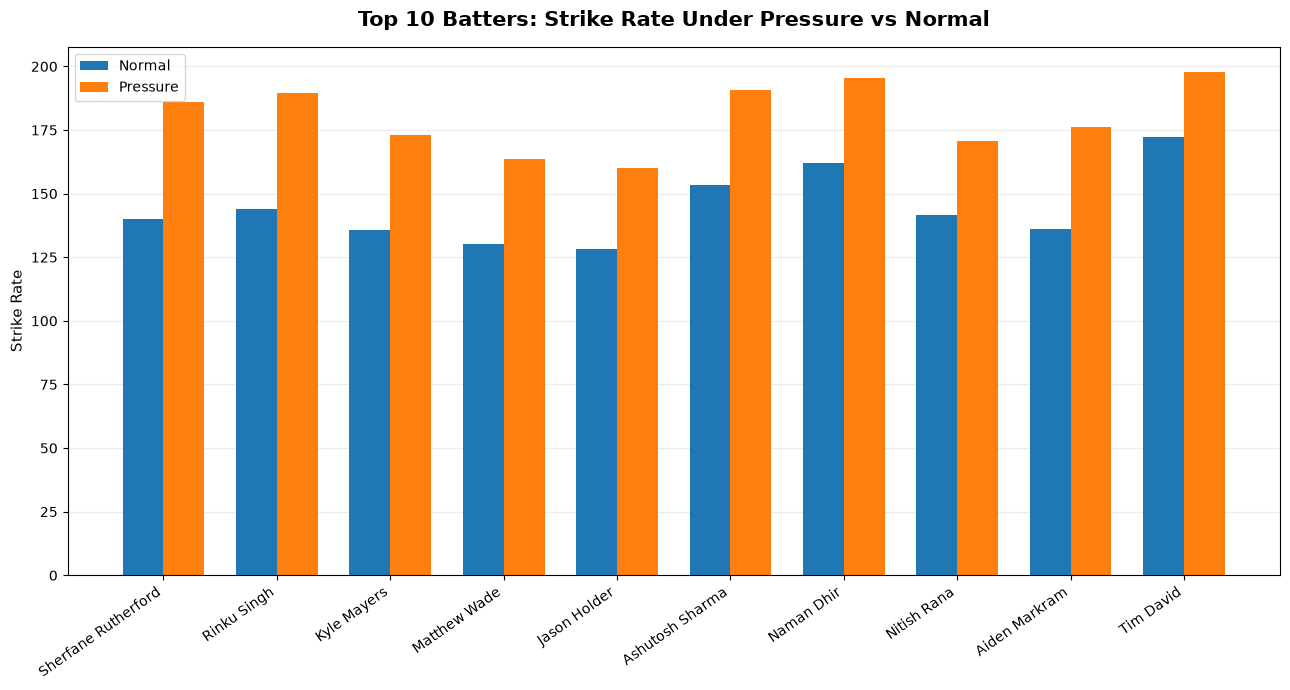

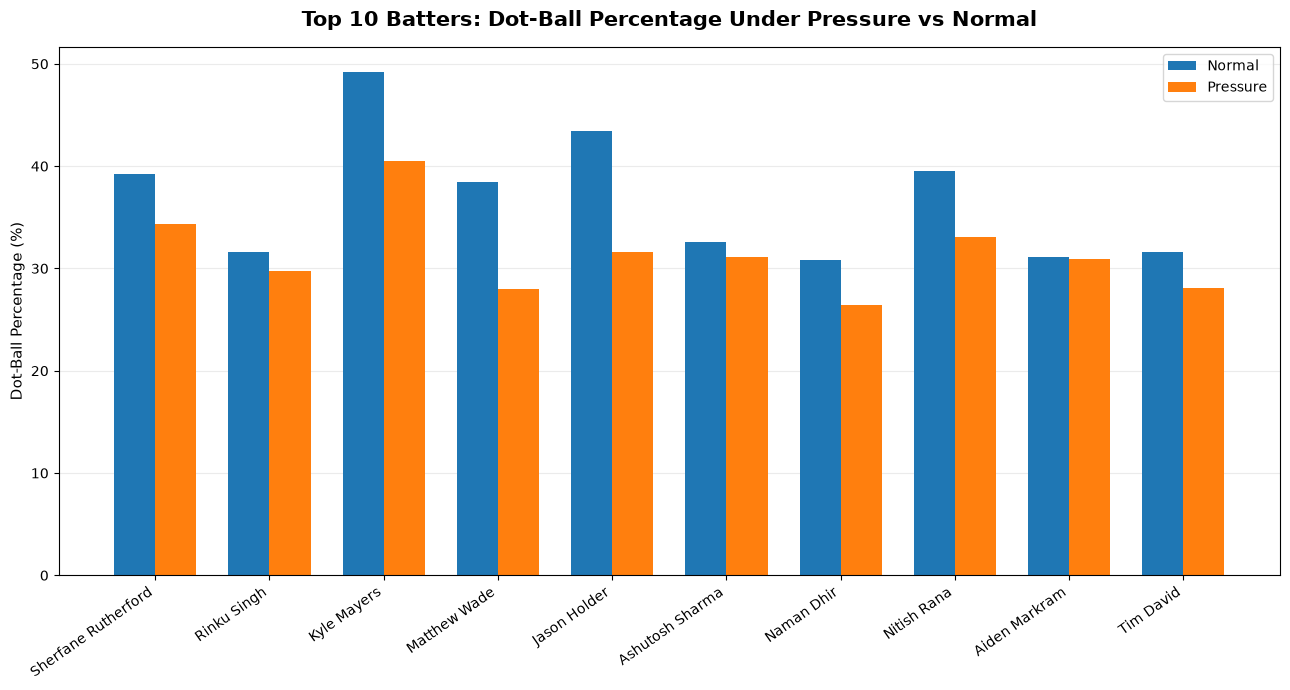

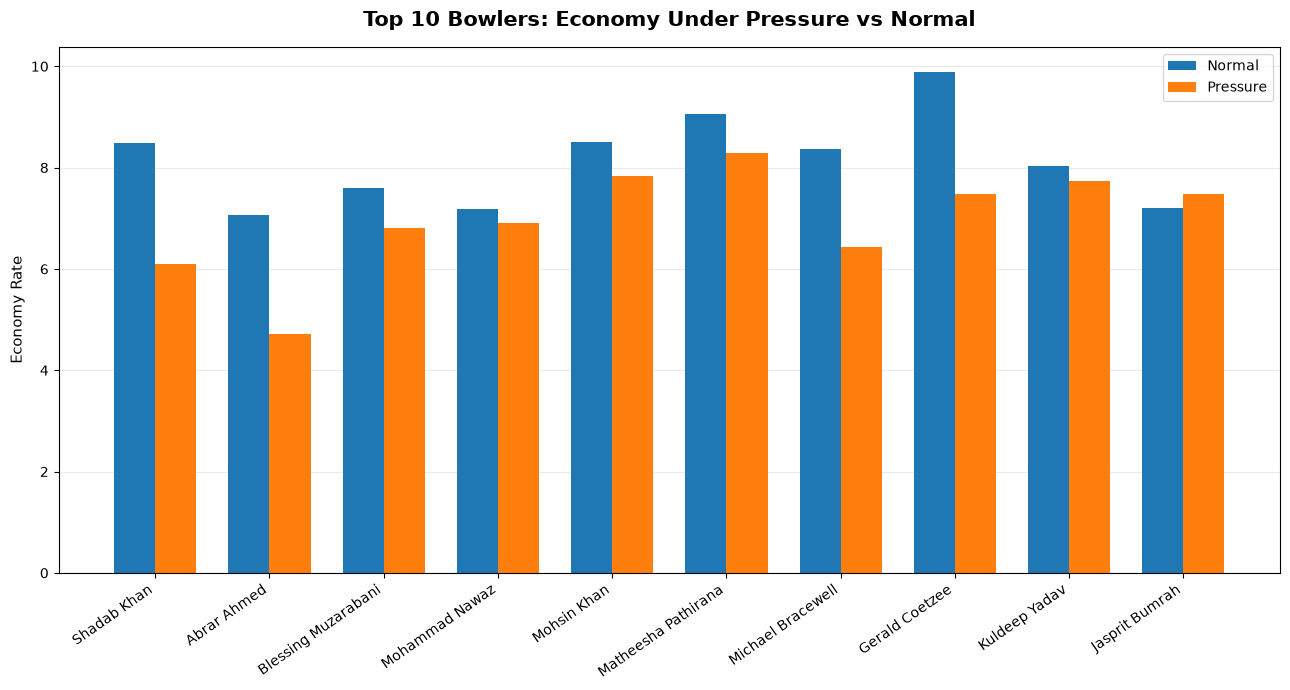

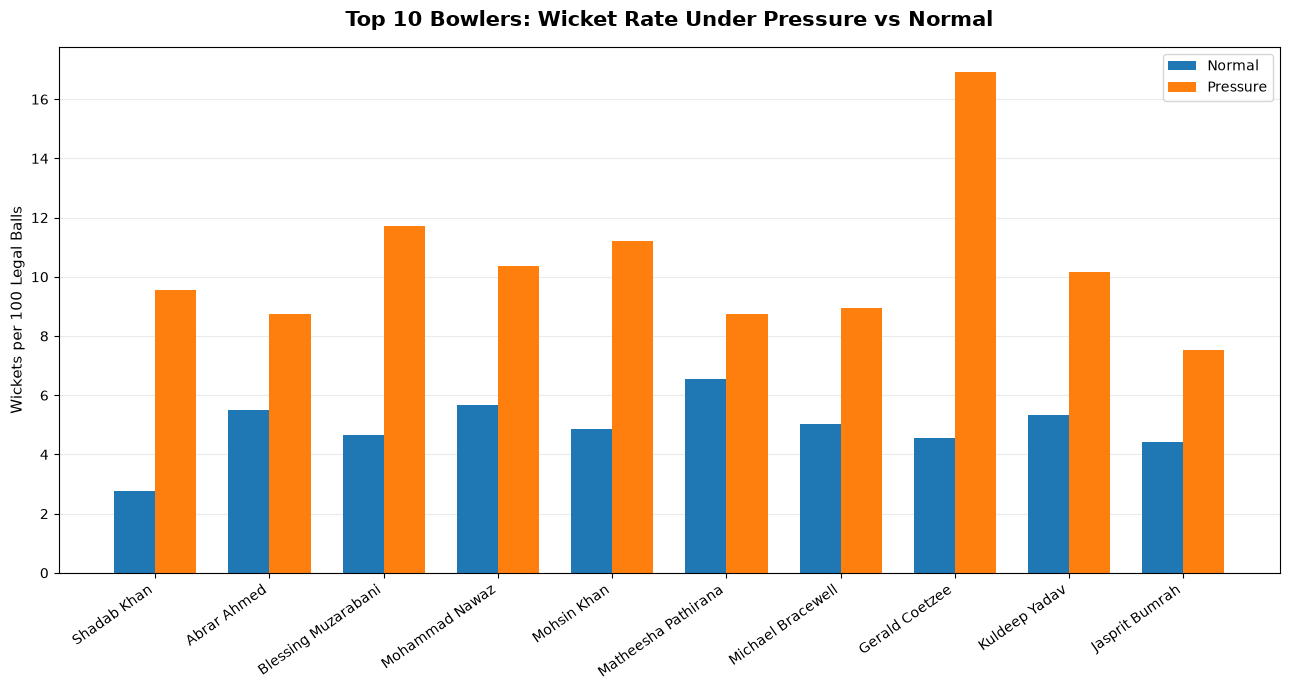

Step 177 completed successfully.
Four charts saved as high-resolution PNG files.


In [220]:

# STEP 177: Create report-ready performance comparison charts

import matplotlib.pyplot as plt
import numpy as np

# Consistent chart style
plt.rcParams.update({
    "figure.figsize": (12, 7),
    "font.size": 10,
    "axes.titlesize": 15,
    "axes.labelsize": 11
})

def comparison_chart(df, name_col, pressure_col, normal_col,
                     title, ylabel, filename, higher_is_better=True):

    data = df.sort_values("rank").copy()
    names = data[name_col].tolist()
    pressure = data[pressure_col].astype(float).to_numpy()
    normal = data[normal_col].astype(float).to_numpy()

    x = np.arange(len(names))
    width = 0.36

    fig, ax = plt.subplots(figsize=(13, 7))

    ax.bar(x - width/2, normal, width, label="Normal")
    ax.bar(x + width/2, pressure, width, label="Pressure")

    ax.set_title(title, pad=15, fontweight="bold")
    ax.set_ylabel(ylabel)
    ax.set_xticks(x)
    ax.set_xticklabels(names, rotation=35, ha="right")
    ax.legend()
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

    fig.tight_layout()
    fig.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

# 1. Batter strike rate
comparison_chart(
    batter_top10_evidence,
    "striker_name",
    "strike_rate_pressure",
    "strike_rate_normal",
    "Top 10 Batters: Strike Rate Under Pressure vs Normal",
    "Strike Rate",
    "ROUND1_BATTER_STRIKE_RATE.png"
)

# 2. Batter dot-ball percentage
comparison_chart(
    batter_top10_evidence,
    "striker_name",
    "dot_ball_pct_pressure",
    "dot_ball_pct_normal",
    "Top 10 Batters: Dot-Ball Percentage Under Pressure vs Normal",
    "Dot-Ball Percentage (%)",
    "ROUND1_BATTER_DOT_BALLS.png",
    higher_is_better=False
)

# 3. Bowler economy
comparison_chart(
    bowler_top10_evidence,
    "bowler_name",
    "economy_pressure",
    "economy_normal",
    "Top 10 Bowlers: Economy Under Pressure vs Normal",
    "Economy Rate",
    "ROUND1_BOWLER_ECONOMY.png",
    higher_is_better=False
)

# 4. Bowler wicket rate
comparison_chart(
    bowler_top10_evidence,
    "bowler_name",
    "wicket_rate_pressure",
    "wicket_rate_normal",
    "Top 10 Bowlers: Wicket Rate Under Pressure vs Normal",
    "Wickets per 100 Legal Balls",
    "ROUND1_BOWLER_WICKET_RATE.png"
)

print("Step 177 completed successfully.")
print("Four charts saved as high-resolution PNG files.")


In [221]:

# STEP 178: Final integrity audit and RR nationality screening

import os
import pandas as pd

# 1. Apply the nationality rule to BOTH RR shortlists
pakistan_players = {
    "Shadab Khan",
    "Abrar Ahmed",
    "Mohammad Nawaz",
    "Shaheen Afridi"
}

# Rebuild RR batter shortlist
rr_batter_candidates = (
    final_batter_ranking[
        ~final_batter_ranking["striker_name"].isin(pakistan_players)
    ]
    .head(10)
    [[
        "rank", "striker_id", "striker_name",
        "final_batter_score", "format_pressure_balls",
        "formats_played"
    ]]
    .copy()
)

# Rebuild RR bowler shortlist
rr_bowler_candidates = (
    bowler_ranking[
        ~bowler_ranking["bowler_name"].isin(pakistan_players)
    ]
    .head(10)
    [[
        "rank", "bowler_id", "bowler_name",
        "bowler_score", "pressure_balls",
        "formats_played"
    ]]
    .copy()
)

# Create fresh shortlist positions
rr_batter_candidates.insert(
    0, "shortlist_rank",
    range(1, len(rr_batter_candidates) + 1)
)

rr_bowler_candidates.insert(
    0, "shortlist_rank",
    range(1, len(rr_bowler_candidates) + 1)
)

rr_batter_candidates["auction_availability"] = "Unverified"
rr_bowler_candidates["auction_availability"] = "Unverified"

# 2. Verify nationality exclusion
assert not set(rr_batter_candidates["striker_name"]) & pakistan_players
assert not set(rr_bowler_candidates["bowler_name"]) & pakistan_players

# 3. Verify official Round 1 rankings are unchanged
assert len(round1_batters) == 10
assert len(round1_bowlers) == 10

assert round1_batters["rank"].tolist() == list(range(1, 11))
assert round1_bowlers["rank"].tolist() == list(range(1, 11))

# 4. Verify evidence tables
assert len(batter_top10_evidence) == 10
assert len(bowler_top10_evidence) == 10

assert batter_top10_evidence["striker_name"].notna().all()
assert bowler_top10_evidence["bowler_name"].notna().all()

# 5. Verify robustness tables
assert pressure_robustness_final["player_name"].notna().all()
assert weight_robustness_final["player_name"].notna().all()

# 6. Verify all four charts exist
chart_files = [
    "ROUND1_BATTER_STRIKE_RATE.png",
    "ROUND1_BATTER_DOT_BALLS.png",
    "ROUND1_BOWLER_ECONOMY.png",
    "ROUND1_BOWLER_WICKET_RATE.png"
]

chart_status = {
    filename: os.path.exists(filename)
    for filename in chart_files
}

assert all(chart_status.values()), "One or more chart files are missing."

# 7. Export final RR shortlists
rr_batter_candidates.to_csv(
    "RR_Batter_Candidate_Ranking.csv",
    index=False
)

rr_bowler_candidates.to_csv(
    "RR_Bowler_Candidate_Ranking.csv",
    index=False
)

# 8. Export official Round 1 rankings again
round1_batters.to_csv(
    "ROUND1_OFFICIAL_TOP10_BATTERS.csv",
    index=False
)

round1_bowlers.to_csv(
    "ROUND1_OFFICIAL_TOP10_BOWLERS.csv",
    index=False
)

print("RR BATTER SHORTLIST")
display(rr_batter_candidates)

print("\nRR BOWLER SHORTLIST")
display(rr_bowler_candidates)

print("\nCHART FILE CHECK")
display(pd.DataFrame(
    list(chart_status.items()),
    columns=["Chart", "Exists"]
))

print("\nFINAL INTEGRITY AUDIT PASSED.")
print("Official Round 1 rankings remain separate.")
print("Pakistan-national players are excluded from both RR shortlists.")
print("Auction availability remains unverified.")


RR BATTER SHORTLIST


,shortlist_rank,rank,striker_id,striker_name,final_batter_score,format_pressure_balls,formats_played,auction_availability
0,1,1,6725,Sherfane Rutherford,94.285714,172.0,2.0,Unverified
1,2,2,4708,Rinku Singh,92.040816,222.0,2.0,Unverified
2,3,3,2416,Kyle Mayers,90.153061,111.0,2.0,Unverified
3,4,4,796,Matthew Wade,90.102041,107.0,2.0,Unverified
4,5,5,2633,Jason Holder,89.387755,196.0,2.0,Unverified
5,6,6,8101,Ashutosh Sharma,89.285714,138.0,1.0,Unverified
6,7,7,37052,Naman Dhir,89.285714,106.0,2.0,Unverified
7,8,8,4246,Nitish Rana,87.295918,130.0,1.0,Unverified
8,9,9,3605,Aiden Markram,87.142857,294.0,2.0,Unverified
9,10,10,6396,Tim David,86.734694,228.0,2.0,Unverified



RR BOWLER SHORTLIST


,shortlist_rank,rank,bowler_id,bowler_name,bowler_score,pressure_balls,formats_played,auction_availability
2,1,3,6523,Blessing Muzarabani,90.333333,111.0,1.0,Unverified
4,2,5,6669,Mohsin Khan,88.851852,98.0,1.0,Unverified
5,3,6,8661,Matheesha Pathirana,85.296296,297.0,2.0,Unverified
6,4,7,6512,Michael Bracewell,84.481481,123.0,2.0,Unverified
7,5,8,6628,Gerald Coetzee,84.000000,65.0,2.0,Unverified
8,6,9,3644,Kuldeep Yadav,82.296296,344.0,2.0,Unverified
9,7,10,2933,Jasprit Bumrah,81.629630,306.0,2.0,Unverified
11,8,12,830,Josh Hazlewood,78.740741,333.0,2.0,Unverified
12,9,13,4489,Prasidh Krishna,78.407407,200.0,2.0,Unverified
13,10,14,6256,Varun Chakravarthy,78.333333,506.0,2.0,Unverified



CHART FILE CHECK


,Chart,Exists
0,ROUND1_BATTER_STRIKE_RATE.png,True
1,ROUND1_BATTER_DOT_BALLS.png,True
2,ROUND1_BOWLER_ECONOMY.png,True
3,ROUND1_BOWLER_WICKET_RATE.png,True



FINAL INTEGRITY AUDIT PASSED.
Official Round 1 rankings remain separate.
Pakistan-national players are excluded from both RR shortlists.
Auction availability remains unverified.


In [223]:

# STEP 179: Freeze final Round 1 submission tables

import os
import shutil
import pandas as pd

os.makedirs("ROUND1_SUBMISSION", exist_ok=True)

# 1. Official rankings
round1_batters.to_csv(
    "ROUND1_SUBMISSION/Official_Top10_Batters.csv",
    index=False
)

round1_bowlers.to_csv(
    "ROUND1_SUBMISSION/Official_Top10_Bowlers.csv",
    index=False
)

# 2. Detailed player evidence
batter_top10_evidence.to_csv(
    "ROUND1_SUBMISSION/Detailed_Batter_Evidence.csv",
    index=False
)

bowler_top10_evidence.to_csv(
    "ROUND1_SUBMISSION/Detailed_Bowler_Evidence.csv",
    index=False
)

# 3. Robustness analysis
pressure_robustness_final.to_csv(
    "ROUND1_SUBMISSION/Pressure_Threshold_Robustness.csv",
    index=False
)

weight_robustness_final.to_csv(
    "ROUND1_SUBMISSION/Component_Weight_Robustness.csv",
    index=False
)

# 4. Model validation and dataset coverage
validation_table.to_csv(
    "ROUND1_SUBMISSION/Model_Validation.csv",
    index=False
)

coverage.to_csv(
    "ROUND1_SUBMISSION/Model_Dataset_Coverage.csv",
    index=False
)

# 5. Methodology reference
methodology_reference.to_csv(
    "ROUND1_SUBMISSION/Methodology_Reference.csv",
    index=False
)

# 6. Copy charts
chart_files = [
    "ROUND1_BATTER_STRIKE_RATE.png",
    "ROUND1_BATTER_DOT_BALLS.png",
    "ROUND1_BOWLER_ECONOMY.png",
    "ROUND1_BOWLER_WICKET_RATE.png"
]

for filename in chart_files:
    assert os.path.exists(filename), f"Missing chart: {filename}"
    shutil.copy2(
        filename,
        os.path.join("ROUND1_SUBMISSION", filename)
    )

# 7. Create manifest
manifest = pd.DataFrame({
    "Artifact": [
        "Official Top 10 Batters",
        "Official Top 10 Bowlers",
        "Detailed Batter Evidence",
        "Detailed Bowler Evidence",
        "Pressure Threshold Robustness",
        "Component Weight Robustness",
        "Model Validation",
        "Model Dataset Coverage",
        "Methodology Reference",
        "Batter Strike Rate Chart",
        "Batter Dot Ball Chart",
        "Bowler Economy Chart",
        "Bowler Wicket Rate Chart"
    ]
})

manifest["Status"] = "Ready"

manifest.to_csv(
    "ROUND1_SUBMISSION/Submission_Manifest.csv",
    index=False
)

# 8. Verify all exported files
expected_files = [
    "Official_Top10_Batters.csv",
    "Official_Top10_Bowlers.csv",
    "Detailed_Batter_Evidence.csv",
    "Detailed_Bowler_Evidence.csv",
    "Pressure_Threshold_Robustness.csv",
    "Component_Weight_Robustness.csv",
    "Model_Validation.csv",
    "Model_Dataset_Coverage.csv",
    "Methodology_Reference.csv",
    "Submission_Manifest.csv"
] + chart_files

missing_files = [
    filename for filename in expected_files
    if not os.path.exists(
        os.path.join("ROUND1_SUBMISSION", filename)
    )
]

assert len(missing_files) == 0, f"Missing files: {missing_files}"

print("FINAL SUBMISSION PACKAGE VERIFIED")
display(manifest)

print("\nOfficial Batter Rankings")
display(round1_batters)

print("\nOfficial Bowler Rankings")
display(round1_bowlers)

print("\nTotal files exported:", len(expected_files))
print("All files saved inside ROUND1_SUBMISSION.")


FINAL SUBMISSION PACKAGE VERIFIED


,Artifact,Status
0,Official Top 10 Batters,Ready
1,Official Top 10 Bowlers,Ready
2,Detailed Batter Evidence,Ready
3,Detailed Bowler Evidence,Ready
4,Pressure Threshold Robustness,Ready
5,Component Weight Robustness,Ready
6,Model Validation,Ready
7,Model Dataset Coverage,Ready
8,Methodology Reference,Ready
9,Batter Strike Rate Chart,Ready



Official Batter Rankings


,striker_id,striker_name,runs_normal,runs_pressure,balls_normal,balls_pressure,strike_rate_normal,strike_rate_pressure,dot_ball_pct_normal,dot_ball_pct_pressure,...,sr_score,improvement_score,dot_avoidance_score,boundary_score,format_adjusted_score,format_pressure_balls,formats_played,format_sr_score,final_batter_score,rank
0,6725,Sherfane Rutherford,902.0,320.0,645.0,172.0,139.844961,186.046512,39.224806,34.302326,...,94.897959,100.000000,80.612245,95.918367,110.335374,172.0,2.0,96.938776,94.285714,1
1,4708,Rinku Singh,1522.0,421.0,1057.0,222.0,143.992431,189.639640,31.598865,29.729730,...,98.979592,98.979592,62.244898,98.979592,114.821916,222.0,2.0,100.000000,92.040816,2
2,2416,Kyle Mayers,852.0,192.0,628.0,111.0,135.668790,172.972973,49.203822,40.540541,...,87.755102,95.918367,92.857143,88.775510,104.774538,111.0,2.0,85.714286,90.153061,3
3,796,Matthew Wade,417.0,175.0,320.0,107.0,130.312500,163.551402,38.437500,28.037383,...,78.571429,92.857143,96.938776,74.489796,106.452916,107.0,2.0,90.816327,90.102041,4
4,2633,Jason Holder,322.0,314.0,251.0,196.0,128.286853,160.204082,43.426295,31.632653,...,75.510204,91.836735,98.979592,71.428571,106.435949,196.0,2.0,89.795918,89.387755,5
5,8101,Ashutosh Sharma,259.0,263.0,169.0,138.0,153.254438,190.579710,32.544379,31.159420,...,96.938776,96.938776,58.163265,94.897959,112.105423,138.0,1.0,97.959184,89.285714,6
6,37052,Naman Dhir,651.0,207.0,402.0,106.0,161.940299,195.283019,30.845771,26.415094,...,95.918367,93.877551,75.510204,87.755102,109.733234,106.0,2.0,93.877551,89.285714,7
7,4246,Nitish Rana,1036.0,222.0,731.0,130.0,141.723666,170.769231,39.534884,33.076923,...,86.734694,87.755102,87.755102,92.857143,104.698333,130.0,1.0,84.693878,87.295918,8
8,3605,Aiden Markram,1876.0,518.0,1377.0,294.0,136.238199,176.190476,31.082062,30.952381,...,93.877551,97.959184,47.959184,97.959184,109.833849,294.0,2.0,95.918367,87.142857,9
9,6396,Tim David,1709.0,451.0,993.0,228.0,172.104733,197.807018,31.621349,28.070175,...,100.000000,83.673469,68.367347,83.673469,114.489132,228.0,2.0,98.979592,86.734694,10



Official Bowler Rankings


,bowler_id,bowler_name,pressure_balls,formats_played,economy_score,wicket_score,dot_score,boundary_score,economy_component,wicket_component,dot_component,boundary_component,bowler_score,rank
0,4926,Shadab Khan,199.0,1.0,120.751009,120.216815,110.921989,138.216024,98.518519,88.148148,93.333333,99.259259,93.962963,1
1,5979,Abrar Ahmed,126.0,1.0,131.130850,110.711016,122.564675,133.100257,99.259259,77.777778,100.000000,97.777778,91.666667,2
2,6523,Blessing Muzarabani,111.0,1.0,109.851254,131.524759,110.306694,106.094754,91.851852,97.777778,91.111111,68.888889,90.333333,3
3,2490,Mohammad Nawaz,193.0,1.0,111.732900,127.339061,102.533150,131.896172,94.814815,94.814815,63.703704,97.037037,88.925926,4
4,6669,Mohsin Khan,98.0,1.0,107.736749,139.004076,106.774652,109.858956,85.925926,99.259259,84.444444,76.296296,88.851852,5
5,8661,Matheesha Pathirana,297.0,2.0,105.759465,120.618461,105.084953,121.697694,80.740741,89.629630,78.518519,93.333333,85.296296,6
6,6512,Michael Bracewell,123.0,2.0,110.585135,109.438202,109.309087,114.730993,94.074074,74.074074,88.888889,83.703704,84.481481,7
7,6628,Gerald Coetzee,65.0,2.0,103.900016,136.554890,106.564753,105.095192,76.296296,98.518519,83.703704,65.925926,84.000000,8
8,3644,Kuldeep Yadav,344.0,2.0,108.337898,128.559383,98.832142,118.629315,88.888889,96.296296,42.962963,88.888889,82.296296,9
9,2933,Jasprit Bumrah,306.0,2.0,110.108763,107.635409,110.576980,108.188137,92.592593,68.888889,92.592593,74.814815,81.629630,10



Total files exported: 14
All files saved inside ROUND1_SUBMISSION.
